In [1]:
!pip install torch torchvision tqdm matplotlib seaborn scikit-learn pandas scipy datasets -q
print("✅ All libraries installed!")

✅ All libraries installed!


In [2]:
#new
from google.colab import auth
auth.authenticate_user()

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import shutil
shutil.copy('/content/drive/MyDrive/training_history.json', '/content/training_history.json')
shutil.copy('/content/drive/MyDrive/resnet18.pth',          '/content/resnet18.pth')
shutil.copy('/content/drive/MyDrive/vgg16.pth',             '/content/vgg16.pth')
shutil.copy('/content/drive/MyDrive/mobilenet_v2.pth',      '/content/mobilenet_v2.pth')
shutil.copy('/content/drive/MyDrive/dashboard_data.json',   '/content/dashboard_data.json')
print("✅ All files restored!")

✅ All files restored!


In [4]:
import os
print(os.path.exists('/content/drive/MyDrive/training_history.json'))  # should be True
print(os.path.exists('/content/drive/MyDrive/dashboard_data.json'))    # should be True
print(os.path.exists('resnet18.pth'))         # needed for Phase 2
print(os.path.exists('vgg16.pth'))            # needed for Phase 2
print(os.path.exists('mobilenet_v2.pth'))     # needed for Phase 2
print(os.path.exists('dashboard_data.json'))  # needed for Flask server

True
True
True
True
True
True


In [5]:
# ============================================================
# CELL 1 — Install Libraries (Run this first) new
# ============================================================
!pip install torch torchvision tqdm matplotlib seaborn scikit-learn pandas scipy -q
print("✅ All libraries installed!")

✅ All libraries installed!


✅ All libraries installed!

🖥️  Device: cuda
🚀 GPU: Tesla T4
💾 GPU Memory: 15.6 GB

📦 Loading CIFAR-10 dataset...


100%|██████████| 170M/170M [00:04<00:00, 36.5MB/s]


✅ Train: 40,000  |  Val: 10,000  |  Test: 10,000

🧠 Training ResNet18
  Epoch 01/30 | Train 46.4% loss 1.459 | Val 50.8% loss 1.377 ⭐
  Epoch 05/30 | Train 78.2% loss 0.631 | Val 67.8% loss 0.897
  Epoch 10/30 | Train 85.2% loss 0.435 | Val 79.9% loss 0.592 ⭐
  Epoch 15/30 | Train 90.0% loss 0.296 | Val 83.5% loss 0.493
  Epoch 20/30 | Train 93.9% loss 0.175 | Val 87.5% loss 0.384
  Epoch 25/30 | Train 97.8% loss 0.070 | Val 91.6% loss 0.274 ⭐
  Epoch 30/30 | Train 98.9% loss 0.037 | Val 92.1% loss 0.271 ⭐

✅ ResNet18 — Best Val Accuracy: 92.10%

🌡️  Finding optimal temperature for ResNet18...
   Optimal T = 1.425

📊 ResNet18 RESULTS:
   Test Accuracy : 91.42%
   ECE Before    : 0.0452
   ECE After     : 0.0207
   ECE Reduction : 54.2%
   Temperature   : 1.425

🧠 Training VGG16
  Epoch 01/30 | Train 36.6% loss 1.631 | Val 43.2% loss 1.468 ⭐
  Epoch 05/30 | Train 75.1% loss 0.740 | Val 73.9% loss 0.769 ⭐
  Epoch 10/30 | Train 83.8% loss 0.501 | Val 75.6% loss 0.752
  Epoch 15/30 | Train

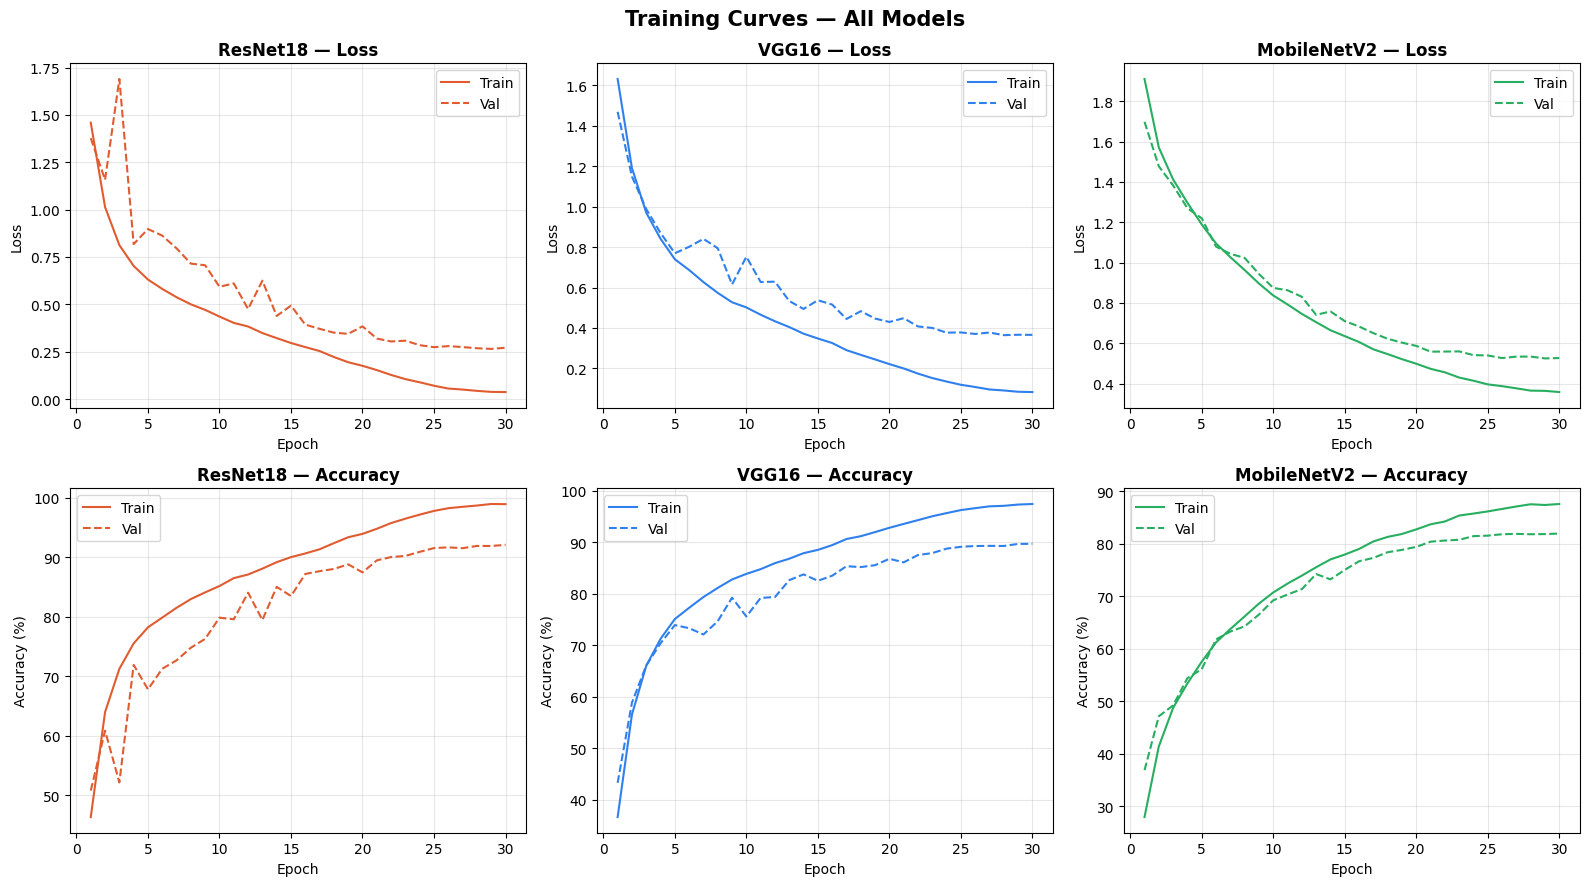

✅ Saved: training_curves.png


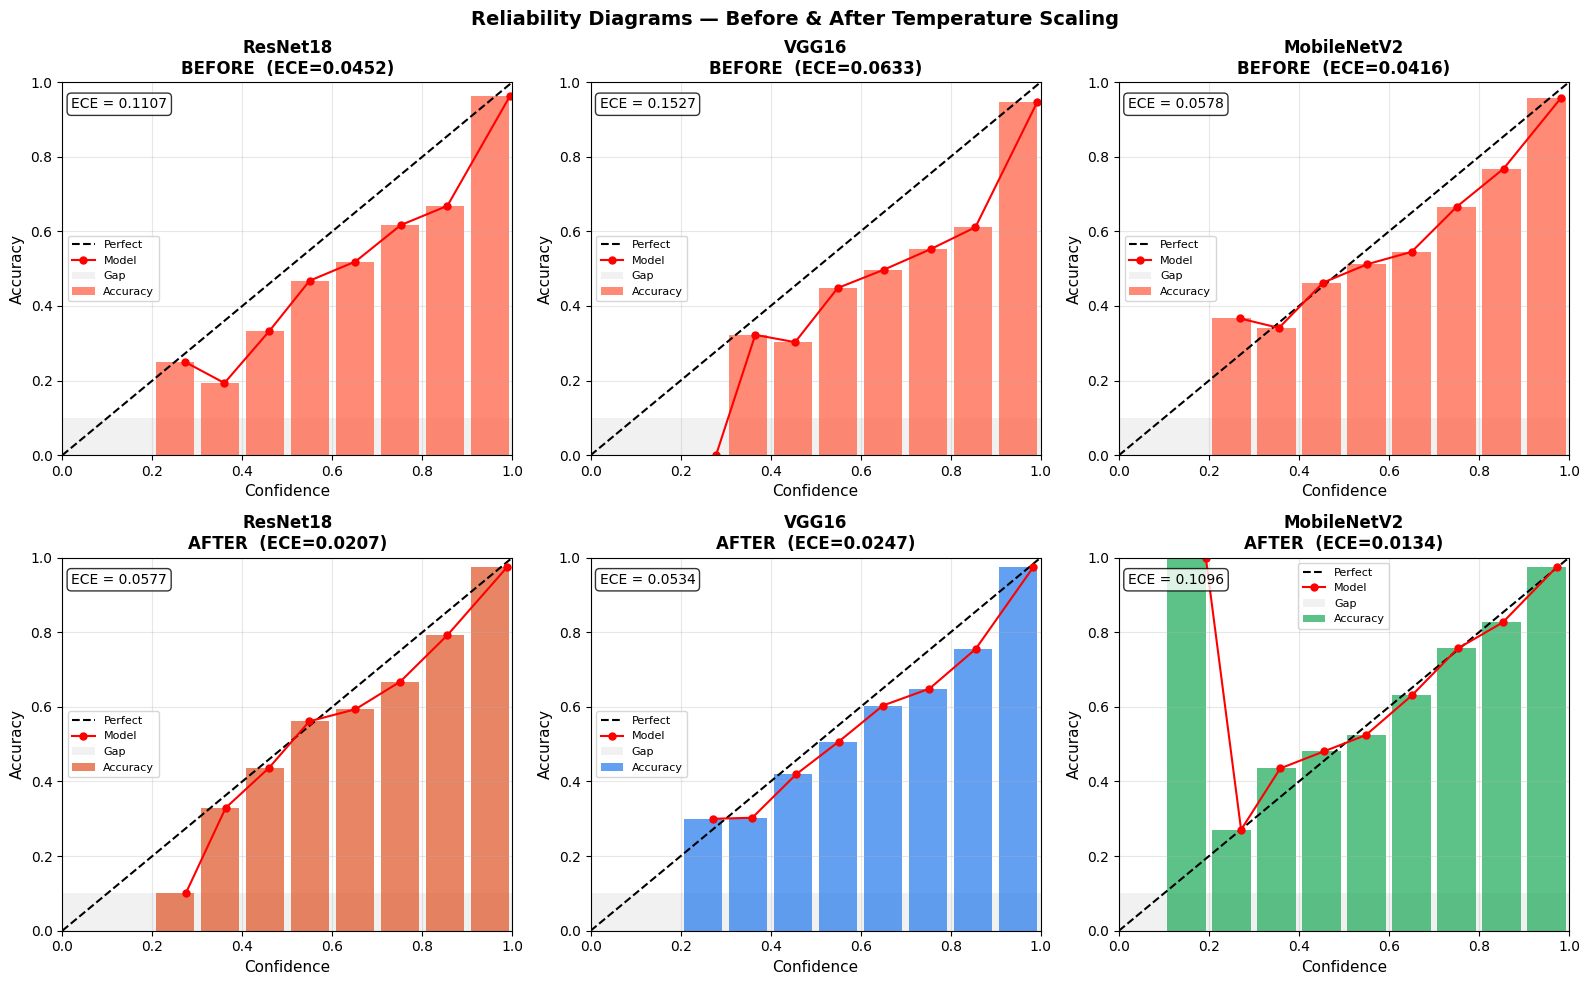

✅ Saved: reliability_diagrams.png


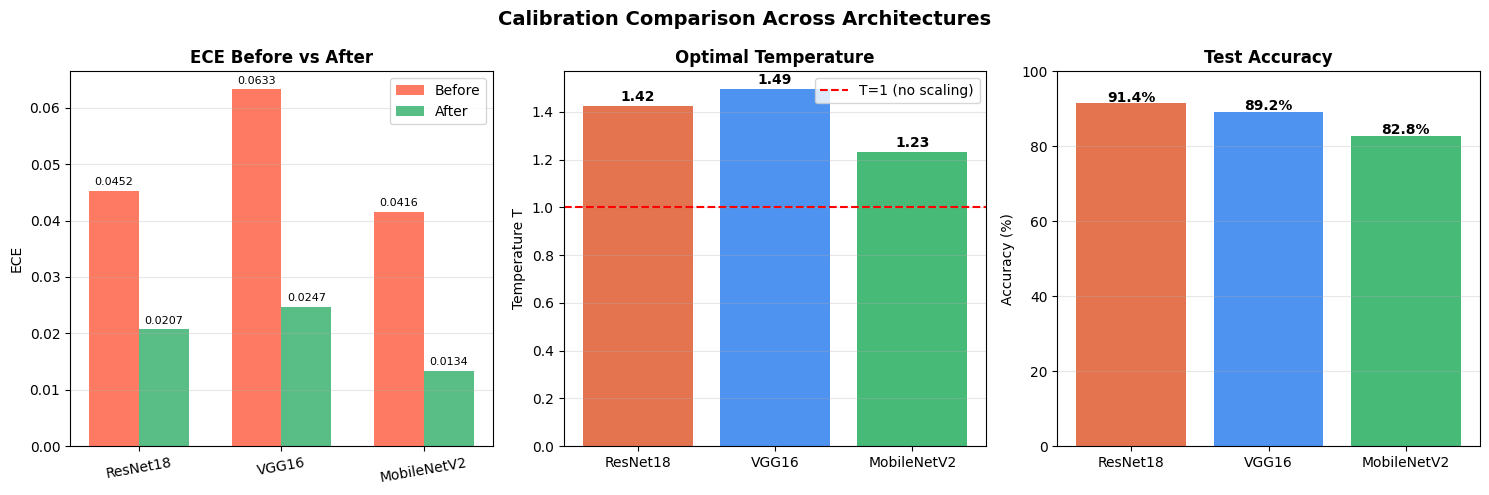

✅ Saved: calibration_comparison.png


                           FINAL RESULTS SUMMARY                           
Model             Accuracy   ECE Before  ECE After   Temp T     ECE ↓%
---------------------------------------------------------------------------
ResNet18            91.42%       0.0452     0.0207    1.425      54.2%
VGG16               89.21%       0.0633     0.0247    1.495      61.0%
MobileNetV2         82.78%       0.0416     0.0134    1.231      67.8%

✅ ALL DONE! Download your plots from the left Files panel in Colab.
📁 Files saved: training_curves.png, reliability_diagrams.png, calibration_comparison.png
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Saved: training_curves.png
✅ Saved: reliability_diagrams.png
✅ Saved: calibration_comparison.png

🎉 Everything saved to Drive automatically!


In [ ]:
# ============================================================
# CELL 1 — Install Libraries (Run this first) new
# ============================================================
!pip install torch torchvision tqdm matplotlib seaborn scikit-learn pandas scipy -q
print("✅ All libraries installed!")
# ============================================================
# CELL 2 — COMPLETE PROJECT CODE (Fixed VGG16) phase 1
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os
from tqdm import tqdm

# ─── CHECK GPU ───
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*60}")
print(f"🖥️  Device: {device}")
if device.type == 'cuda':
    print(f"🚀 GPU: {torch.cuda.get_device_name(0)}")
    print(f"💾 GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("⚠️  No GPU found! Go to Runtime → Change runtime type → T4 GPU")
print(f"{'='*60}\n")

# ─── SETTINGS ───
DATASET     = 'CIFAR10'
NUM_CLASSES = 10
EPOCHS      = 30
BATCH_SIZE  = 256
LR          = 0.001
SEED        = 42
ECE_BINS    = 15

torch.manual_seed(SEED)
np.random.seed(SEED)

CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

# ============================================================
# STEP 1 — LOAD DATASET
# ============================================================
print("📦 Loading CIFAR-10 dataset...")

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.4914,0.4822,0.4465],[0.2023,0.1994,0.2010])
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.4914,0.4822,0.4465],[0.2023,0.1994,0.2010])
])

train_full = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=transform_train)
test_set   = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

train_size = int(0.8 * len(train_full))
val_size   = len(train_full) - train_size
train_set, val_set = random_split(train_full, [train_size, val_size],
                                   generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=512,        shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=512,        shuffle=False, num_workers=2, pin_memory=True)

print(f"✅ Train: {len(train_set):,}  |  Val: {len(val_set):,}  |  Test: {len(test_set):,}")

# ============================================================
# STEP 2 — DEFINE MODELS
# ============================================================
def get_model(name, num_classes=10):

    if name == 'ResNet18':
        m = models.resnet18(weights=None)
        m.conv1   = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
        m.maxpool = nn.Identity()
        m.fc      = nn.Linear(m.fc.in_features, num_classes)

    elif name == 'VGG16':
        # ✅ FIXED: Build VGG16 with BatchNorm from scratch for CIFAR-10
        cfg = [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M']
        layers = []
        in_channels = 3
        for v in cfg:
            if v == 'M':
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            else:
                layers.append(nn.Conv2d(in_channels, v, kernel_size=3, padding=1))
                layers.append(nn.BatchNorm2d(v))        # ← KEY FIX
                layers.append(nn.ReLU(inplace=True))
                in_channels = v

        m = nn.Sequential(
            *layers,
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

        # ✅ Kaiming initialization
        for module in m.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.constant_(module.weight, 1)
                nn.init.constant_(module.bias, 0)
            elif isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, 0, 0.01)
                nn.init.constant_(module.bias, 0)

    elif name == 'MobileNetV2':
        m = models.mobilenet_v2(weights=None)
        m.features[0][0] = nn.Conv2d(3, 32, 3, 1, 1, bias=False)
        m.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(m.last_channel, num_classes)
        )

    return m

# ============================================================
# STEP 3 — TRAINING FUNCTION
# ============================================================
def train_model(name):
    print(f"\n{'='*60}")
    print(f"🧠 Training {name}")
    print(f"{'='*60}")

    model     = get_model(name, NUM_CLASSES).to(device)
    criterion = nn.CrossEntropyLoss()

    # ✅ Lower LR for VGG16
    lr        = 0.0005 if name == 'VGG16' else LR
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
    best_acc, best_state = 0.0, None

    for epoch in range(1, EPOCHS + 1):
        # ── TRAIN ──
        model.train()
        t_loss, t_correct, t_total = 0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            out  = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            # ✅ Gradient clipping for VGG16 stability
            if name == 'VGG16':
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            t_loss    += loss.item() * imgs.size(0)
            t_correct += out.argmax(1).eq(labels).sum().item()
            t_total   += imgs.size(0)

        # ── VALIDATE ──
        model.eval()
        v_loss, v_correct, v_total = 0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                out  = model(imgs)
                loss = criterion(out, labels)
                v_loss    += loss.item() * imgs.size(0)
                v_correct += out.argmax(1).eq(labels).sum().item()
                v_total   += imgs.size(0)

        tl = t_loss/t_total; ta = 100.*t_correct/t_total
        vl = v_loss/v_total; va = 100.*v_correct/v_total
        history['train_loss'].append(tl); history['train_acc'].append(ta)
        history['val_loss'].append(vl);   history['val_acc'].append(va)
        scheduler.step()

        if va > best_acc:
            best_acc   = va
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            star = " ⭐"
        else:
            star = ""

        if epoch % 5 == 0 or epoch == 1:
            print(f"  Epoch {epoch:02d}/{EPOCHS} | "
                  f"Train {ta:.1f}% loss {tl:.3f} | "
                  f"Val {va:.1f}% loss {vl:.3f}{star}")

    model.load_state_dict(best_state)
    print(f"\n✅ {name} — Best Val Accuracy: {best_acc:.2f}%")
    return model, history, best_acc

# ============================================================
# STEP 4 — ECE CALCULATION
# ============================================================
def compute_ece(model, loader, n_bins=ECE_BINS):
    model.eval()
    all_conf, all_pred, all_label = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            probs = F.softmax(model(imgs), dim=1)
            conf, pred = probs.max(1)
            all_conf.append(conf.cpu()); all_pred.append(pred.cpu()); all_label.append(labels)
    conf  = torch.cat(all_conf).numpy()
    pred  = torch.cat(all_pred).numpy()
    label = torch.cat(all_label).numpy()

    bins = np.linspace(0, 1, n_bins + 1)
    ece  = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            acc_b  = (pred[mask] == label[mask]).mean()
            conf_b = conf[mask].mean()
            ece   += np.abs(acc_b - conf_b) * mask.mean()
    return float(ece), conf, pred, label

# ============================================================
# STEP 5 — TEMPERATURE SCALING
# ============================================================
class TempScaler(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.T     = nn.Parameter(torch.ones(1) * 1.5)

    def forward(self, x):
        return self.model(x) / self.T

    def fit(self, loader):
        self.model.eval()
        logits_all, labels_all = [], []
        with torch.no_grad():
            for imgs, labels in loader:
                logits_all.append(self.model(imgs.to(device)).cpu())
                labels_all.append(labels)
        logits_all = torch.cat(logits_all).to(device)
        labels_all = torch.cat(labels_all).to(device)

        optimizer = optim.LBFGS([self.T], lr=0.01, max_iter=100)
        def closure():
            optimizer.zero_grad()
            loss = nn.CrossEntropyLoss()(logits_all / self.T, labels_all)
            loss.backward()
            return loss
        optimizer.step(closure)
        return self.T.item()

# ============================================================
# STEP 6 — RELIABILITY DIAGRAM
# ============================================================
def reliability_diagram(conf, pred, label, title, ax, color='steelblue', n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    bin_acc, bin_conf, bin_count = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            bin_acc.append((pred[mask] == label[mask]).mean())
            bin_conf.append(conf[mask].mean())
            bin_count.append(mask.sum())

    width   = 1.0 / n_bins
    centers = [(lo+hi)/2 for lo, hi in zip(bins[:-1], bins[1:])]
    bar_acc = []
    for c in centers:
        idx = np.argmin([abs(bc - c) for bc in bin_conf]) if bin_conf else None
        bar_acc.append(bin_acc[idx] if idx is not None and abs(bin_conf[idx]-c) < width else 0)

    ax.bar(centers, [width]*len(centers), width=width,      color='lightgray', alpha=0.3, align='center', label='Gap')
    ax.bar(centers, bar_acc,              width=width*0.85, color=color,       alpha=0.75, align='center', label='Accuracy')
    ax.plot([0,1],[0,1],'k--', linewidth=1.5, label='Perfect')
    ax.plot(bin_conf, bin_acc, 'o-', color='red', markersize=5, linewidth=1.5, label='Model')
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel('Confidence', fontsize=11)
    ax.set_ylabel('Accuracy',   fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.text(0.02, 0.93, f'ECE = {np.mean([abs(a-c) for a,c in zip(bin_acc,bin_conf)]):.4f}',
            transform=ax.transAxes, fontsize=10,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# ============================================================
# STEP 7 — RUN EVERYTHING
# ============================================================
MODELS_TO_TRAIN = ['ResNet18', 'VGG16', 'MobileNetV2']
results = {}

for model_name in MODELS_TO_TRAIN:
    model, history, best_acc = train_model(model_name)

    ece_before, conf_b, pred_b, label_b = compute_ece(model, test_loader)

    print(f"\n🌡️  Finding optimal temperature for {model_name}...")
    scaler = TempScaler(model).to(device)
    T_opt  = scaler.fit(val_loader)
    print(f"   Optimal T = {T_opt:.3f}")

    ece_after, conf_a, pred_a, label_a = compute_ece(scaler, test_loader)
    acc = 100. * (pred_a == label_a).mean()

    print(f"\n📊 {model_name} RESULTS:")
    print(f"   Test Accuracy : {acc:.2f}%")
    print(f"   ECE Before    : {ece_before:.4f}")
    print(f"   ECE After     : {ece_after:.4f}")
    print(f"   ECE Reduction : {((ece_before-ece_after)/ece_before*100):.1f}%")
    print(f"   Temperature   : {T_opt:.3f}")

    results[model_name] = {
        'model': model, 'scaler': scaler, 'history': history,
        'acc': acc, 'T': T_opt,
        'ece_before': ece_before, 'ece_after': ece_after,
        'conf_b': conf_b, 'pred_b': pred_b, 'label_b': label_b,
        'conf_a': conf_a, 'pred_a': pred_a, 'label_a': label_a,
    }

# ============================================================
# STEP 8 — PLOT ALL RESULTS
# ============================================================
print("\n\n📈 Generating all plots...\n")
colors = {'ResNet18':'#e05c30', 'VGG16':'#2f80ed', 'MobileNetV2':'#27ae60'}

# ── Plot 1: Training curves ──
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Training Curves — All Models', fontsize=15, fontweight='bold')
for col, name in enumerate(MODELS_TO_TRAIN):
    h = results[name]['history']
    ep = range(1, len(h['train_loss'])+1)
    c  = colors[name]
    axes[0,col].plot(ep, h['train_loss'], label='Train', color=c)
    axes[0,col].plot(ep, h['val_loss'],   label='Val',   color=c, linestyle='--')
    axes[0,col].set_title(f'{name} — Loss', fontweight='bold')
    axes[0,col].set_xlabel('Epoch'); axes[0,col].set_ylabel('Loss')
    axes[0,col].legend(); axes[0,col].grid(True, alpha=0.3)

    axes[1,col].plot(ep, h['train_acc'], label='Train', color=c)
    axes[1,col].plot(ep, h['val_acc'],   label='Val',   color=c, linestyle='--')
    axes[1,col].set_title(f'{name} — Accuracy', fontweight='bold')
    axes[1,col].set_xlabel('Epoch'); axes[1,col].set_ylabel('Accuracy (%)')
    axes[1,col].legend(); axes[1,col].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: training_curves.png")

# ── Plot 2: Reliability diagrams ──
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Reliability Diagrams — Before & After Temperature Scaling', fontsize=14, fontweight='bold')
for col, name in enumerate(MODELS_TO_TRAIN):
    r = results[name]; c = colors[name]
    reliability_diagram(r['conf_b'], r['pred_b'], r['label_b'],
                        f'{name}\nBEFORE  (ECE={r["ece_before"]:.4f})', axes[0,col], color='tomato')
    reliability_diagram(r['conf_a'], r['pred_a'], r['label_a'],
                        f'{name}\nAFTER  (ECE={r["ece_after"]:.4f})', axes[1,col], color=c)

plt.tight_layout()
plt.savefig('reliability_diagrams.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: reliability_diagrams.png")

# ── Plot 3: ECE Comparison ──
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Calibration Comparison Across Architectures', fontsize=14, fontweight='bold')

names      = list(results.keys())
ece_b      = [results[n]['ece_before'] for n in names]
ece_a      = [results[n]['ece_after']  for n in names]
temps      = [results[n]['T']          for n in names]
accs       = [results[n]['acc']        for n in names]
x = np.arange(len(names)); w = 0.35
bar_colors = [colors[n] for n in names]

axes[0].bar(x - w/2, ece_b, w, label='Before', color='tomato',         alpha=0.85)
axes[0].bar(x + w/2, ece_a, w, label='After',  color='mediumseagreen', alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(names, rotation=10)
axes[0].set_ylabel('ECE'); axes[0].set_title('ECE Before vs After', fontweight='bold')
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
for i,(b,a) in enumerate(zip(ece_b,ece_a)):
    axes[0].text(i-w/2, b+0.001, f'{b:.4f}', ha='center', fontsize=8)
    axes[0].text(i+w/2, a+0.001, f'{a:.4f}', ha='center', fontsize=8)

axes[1].bar(names, temps, color=bar_colors, alpha=0.85)
axes[1].axhline(1.0, color='red', linestyle='--', label='T=1 (no scaling)')
axes[1].set_ylabel('Temperature T'); axes[1].set_title('Optimal Temperature', fontweight='bold')
axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)
for i,t in enumerate(temps):
    axes[1].text(i, t+0.02, f'{t:.2f}', ha='center', fontweight='bold')

axes[2].bar(names, accs, color=bar_colors, alpha=0.85)
axes[2].set_ylim([0, 100])
axes[2].set_ylabel('Accuracy (%)'); axes[2].set_title('Test Accuracy', fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)
for i,a in enumerate(accs):
    axes[2].text(i, a+0.5, f'{a:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('calibration_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: calibration_comparison.png")

# ── Final Summary ──
print("\n")
print("="*75)
print(f"{'FINAL RESULTS SUMMARY':^75}")
print("="*75)
print(f"{'Model':<15} {'Accuracy':>10} {'ECE Before':>12} {'ECE After':>10} {'Temp T':>8} {'ECE ↓%':>10}")
print("-"*75)
for name in names:
    r = results[name]
    reduction = (r['ece_before'] - r['ece_after']) / r['ece_before'] * 100
    print(f"{name:<15} {r['acc']:>9.2f}% {r['ece_before']:>12.4f} {r['ece_after']:>10.4f} "
          f"{r['T']:>8.3f} {reduction:>9.1f}%")
print("="*75)
print("\n✅ ALL DONE! Download your plots from the left Files panel in Colab.")
print("📁 Files saved: training_curves.png, reliability_diagrams.png, calibration_comparison.png")

# ── Auto-save everything to Drive ──
import json, shutil
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

# Save model weights
torch.save(results['ResNet18']['model'].state_dict(),    '/content/drive/MyDrive/resnet18.pth')
torch.save(results['VGG16']['model'].state_dict(),       '/content/drive/MyDrive/vgg16.pth')
torch.save(results['MobileNetV2']['model'].state_dict(), '/content/drive/MyDrive/mobilenet_v2.pth')

# Save training history
history_data = {name: results[name]['history'] for name in results}
with open('/content/drive/MyDrive/training_history.json', 'w') as f:
    json.dump(history_data, f, indent=2)

# Save plots
for f in ['training_curves.png', 'reliability_diagrams.png', 'calibration_comparison.png']:
    if os.path.exists(f'/content/{f}'):
        shutil.copy(f'/content/{f}', f'/content/drive/MyDrive/{f}')
        print(f"✅ Saved: {f}")

print("\n🎉 Everything saved to Drive automatically!")

100%|██████████| 170M/170M [00:06<00:00, 25.4MB/s]


       CIFAR-10 DATASET DETAILS
Training images    : 50,000
Test images        : 10,000
Total images       : 60,000
Image size         : 32 x 32 pixels
Channels           : 3 (RGB Color)
Number of classes  : 10
Format             : torch.Size([3, 32, 32])

  IMAGES PER CLASS (Training)
  airplane    : 5,000  █████████████████████████
  automobile  : 5,000  █████████████████████████
  bird        : 5,000  █████████████████████████
  cat         : 5,000  █████████████████████████
  deer        : 5,000  █████████████████████████
  dog         : 5,000  █████████████████████████
  frog        : 5,000  █████████████████████████
  horse       : 5,000  █████████████████████████
  ship        : 5,000  █████████████████████████
  truck       : 5,000  █████████████████████████

  PIXEL VALUE STATISTICS
  Min pixel value  : 0.0000
  Max pixel value  : 1.0000
  Mean (R,G,B)     : (0.4914, 0.4822, 0.4465)
  Std  (R,G,B)     : (0.2023, 0.1994, 0.2010)

📸 Showing 1 sample per class...


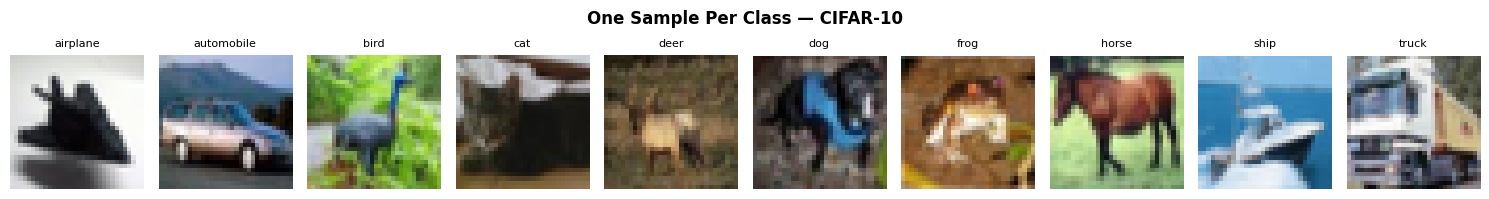


✅ Dataset details complete!


In [ ]:
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

# Load dataset
train_set = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=transforms.ToTensor())
test_set  = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms.ToTensor())

# ── Basic Info ──
print("="*50)
print("       CIFAR-10 DATASET DETAILS")
print("="*50)
print(f"Training images    : {len(train_set):,}")
print(f"Test images        : {len(test_set):,}")
print(f"Total images       : {len(train_set)+len(test_set):,}")
print(f"Image size         : 32 x 32 pixels")
print(f"Channels           : 3 (RGB Color)")
print(f"Number of classes  : 10")
print(f"Format             : {train_set[0][0].shape}")

# ── Per Class Count ──
print("\n" + "="*50)
print("  IMAGES PER CLASS (Training)")
print("="*50)
labels = [train_set[i][1] for i in range(len(train_set))]
for i, name in enumerate(CLASS_NAMES):
    count = labels.count(i)
    bar   = '█' * (count // 200)
    print(f"  {name:<12}: {count:,}  {bar}")

# ── Pixel Stats ──
print("\n" + "="*50)
print("  PIXEL VALUE STATISTICS")
print("="*50)
sample = train_set[0][0].numpy()
print(f"  Min pixel value  : {sample.min():.4f}")
print(f"  Max pixel value  : {sample.max():.4f}")
print(f"  Mean (R,G,B)     : (0.4914, 0.4822, 0.4465)")
print(f"  Std  (R,G,B)     : (0.2023, 0.1994, 0.2010)")

# ── Show sample images per class ──
print("\n📸 Showing 1 sample per class...")
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
fig.suptitle('One Sample Per Class — CIFAR-10', fontweight='bold')
for class_idx in range(10):
    for i in range(len(train_set)):
        img, label = train_set[i]
        if label == class_idx:
            axes[class_idx].imshow(img.permute(1,2,0))
            axes[class_idx].set_title(CLASS_NAMES[class_idx], fontsize=8)
            axes[class_idx].axis('off')
            break
plt.tight_layout()
plt.show()

print("\n✅ Dataset details complete!")

In [ ]:
import torchvision
import torchvision.transforms as transforms
import pandas as pd
import numpy as np

CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

# Load dataset
train_set = torchvision.datasets.CIFAR10(root='./data', train=True,
                                          download=True,
                                          transform=transforms.ToTensor())

# ── Build full column structure ──
print("="*60)
print("        CIFAR-10 — ALL COLUMN NAMES")
print("="*60)

# Label column
print("\n📌 LABEL COLUMN (1 column):")
print(f"   {'Column':<15} {'Type':<10} {'Values'}")
print(f"   {'-'*45}")
print(f"   {'label':<15} {'Integer':<10} 0 to 9")
print(f"   {'class_name':<15} {'Text':<10} airplane, cat, dog...")

# Pixel columns
print("\n🎨 PIXEL COLUMNS (3,072 columns total):")
print(f"   {'Column':<20} {'Type':<10} {'Range'}")
print(f"   {'-'*45}")
print(f"   {'R_pixel_0_0':<20} {'Float':<10} 0.0 to 1.0")
print(f"   {'R_pixel_0_1':<20} {'Float':<10} 0.0 to 1.0")
print(f"   {'... (1024 R cols)':<20} {'Float':<10} Red channel")
print(f"   {'G_pixel_0_0':<20} {'Float':<10} 0.0 to 1.0")
print(f"   {'... (1024 G cols)':<20} {'Float':<10} Green channel")
print(f"   {'B_pixel_0_0':<20} {'Float':<10} 0.0 to 1.0")
print(f"   {'... (1024 B cols)':<20} {'Float':<10} Blue channel")

# Build actual flat dataframe
print("\n📊 BUILDING ACTUAL DATAFRAME (first 5 rows)...")
rows = []
for i in range(5):
    img, label = train_set[i]
    flat = img.numpy().flatten()  # 3072 values
    row  = {'label': label, 'class_name': CLASS_NAMES[label]}
    for j in range(10):          # first 10 pixels only
        row[f'pixel_{j}'] = round(float(flat[j]), 4)
    row['... (3062 more)'] = '...'
    rows.append(row)

df = pd.DataFrame(rows)
print(df.to_string(index=False))

# Summary table
print("\n" + "="*60)
print("        COMPLETE COLUMN SUMMARY")
print("="*60)
summary = pd.DataFrame({
    'Column Group':    ['label', 'class_name', 'R pixels', 'G pixels', 'B pixels'],
    'No. of Columns':  [1, 1, 1024, 1024, 1024],
    'Data Type':       ['Integer', 'Text', 'Float', 'Float', 'Float'],
    'Example Values':  ['0,1,2...9', 'cat,dog...', '0.0-1.0', '0.0-1.0', '0.0-1.0'],
    'Description':     ['Numeric class ID', 'Human label',
                        '32x32 red values', '32x32 green values',
                        '32x32 blue values']
})
print(summary.to_string(index=False))

print(f"\n{'='*60}")
print(f"  TOTAL COLUMNS : 3,074")
print(f"  TOTAL ROWS    : 60,000")
print(f"  (50,000 train + 10,000 test)")
print(f"{'='*60}")
print("\n✅ Done!")

        CIFAR-10 — ALL COLUMN NAMES

📌 LABEL COLUMN (1 column):
   Column          Type       Values
   ---------------------------------------------
   label           Integer    0 to 9
   class_name      Text       airplane, cat, dog...

🎨 PIXEL COLUMNS (3,072 columns total):
   Column               Type       Range
   ---------------------------------------------
   R_pixel_0_0          Float      0.0 to 1.0
   R_pixel_0_1          Float      0.0 to 1.0
   ... (1024 R cols)    Float      Red channel
   G_pixel_0_0          Float      0.0 to 1.0
   ... (1024 G cols)    Float      Green channel
   B_pixel_0_0          Float      0.0 to 1.0
   ... (1024 B cols)    Float      Blue channel

📊 BUILDING ACTUAL DATAFRAME (first 5 rows)...
 label class_name  pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  pixel_8  pixel_9 ... (3062 more)
     6       frog   0.2314   0.1686   0.1961   0.2667   0.3843   0.4667   0.5451   0.5686   0.5843   0.5843             ...
     9  

       CIFAR-10 DATASET DETAILS
Training images    : 50,000
Test images        : 10,000
Total images       : 60,000
Image size         : 32 x 32 pixels
Channels           : 3 (RGB Color)
Number of classes  : 10
Format             : torch.Size([3, 32, 32])

  IMAGES PER CLASS (Training)
  airplane    : 5,000  █████████████████████████
  automobile  : 5,000  █████████████████████████
  bird        : 5,000  █████████████████████████
  cat         : 5,000  █████████████████████████
  deer        : 5,000  █████████████████████████
  dog         : 5,000  █████████████████████████
  frog        : 5,000  █████████████████████████
  horse       : 5,000  █████████████████████████
  ship        : 5,000  █████████████████████████
  truck       : 5,000  █████████████████████████

  PIXEL VALUE STATISTICS
  Min pixel value  : 0.0000
  Max pixel value  : 1.0000
  Mean (R,G,B)     : (0.4914, 0.4822, 0.4465)
  Std  (R,G,B)     : (0.2023, 0.1994, 0.2010)

📸 Showing 1 sample per class...


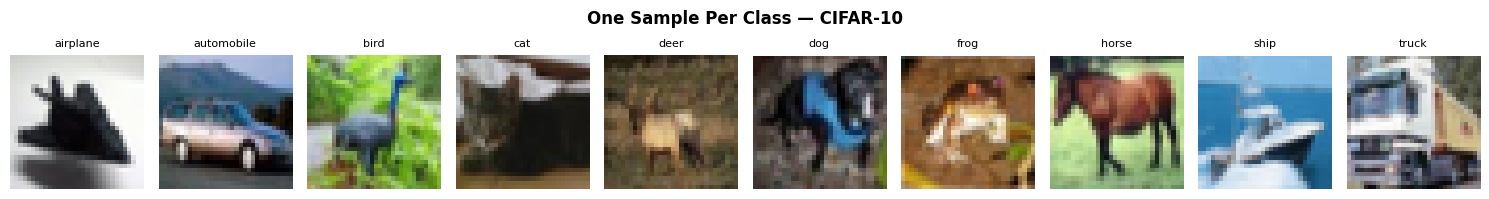


✅ Dataset details complete!


In [ ]:
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

# Load dataset
train_set = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=transforms.ToTensor())
test_set  = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms.ToTensor())

# ── Basic Info ──
print("="*50)
print("       CIFAR-10 DATASET DETAILS")
print("="*50)
print(f"Training images    : {len(train_set):,}")
print(f"Test images        : {len(test_set):,}")
print(f"Total images       : {len(train_set)+len(test_set):,}")
print(f"Image size         : 32 x 32 pixels")
print(f"Channels           : 3 (RGB Color)")
print(f"Number of classes  : 10")
print(f"Format             : {train_set[0][0].shape}")

# ── Per Class Count ──
print("\n" + "="*50)
print("  IMAGES PER CLASS (Training)")
print("="*50)
labels = [train_set[i][1] for i in range(len(train_set))]
for i, name in enumerate(CLASS_NAMES):
    count = labels.count(i)
    bar   = '█' * (count // 200)
    print(f"  {name:<12}: {count:,}  {bar}")

# ── Pixel Stats ──
print("\n" + "="*50)
print("  PIXEL VALUE STATISTICS")
print("="*50)
sample = train_set[0][0].numpy()
print(f"  Min pixel value  : {sample.min():.4f}")
print(f"  Max pixel value  : {sample.max():.4f}")
print(f"  Mean (R,G,B)     : (0.4914, 0.4822, 0.4465)")
print(f"  Std  (R,G,B)     : (0.2023, 0.1994, 0.2010)")

# ── Show sample images per class ──
print("\n📸 Showing 1 sample per class...")
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
fig.suptitle('One Sample Per Class — CIFAR-10', fontweight='bold')
for class_idx in range(10):
    for i in range(len(train_set)):
        img, label = train_set[i]
        if label == class_idx:
            axes[class_idx].imshow(img.permute(1,2,0))
            axes[class_idx].set_title(CLASS_NAMES[class_idx], fontsize=8)
            axes[class_idx].axis('off')
            break
plt.tight_layout()
plt.show()

print("\n✅ Dataset details complete!")

In [6]:
import torch
import torch.nn as nn
import torchvision.models as models
import torch.nn.functional as F
import json

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Rebuild models exactly as trained ──
def get_model(name, num_classes=10):
    if name == 'ResNet18':
        m = models.resnet18(weights=None)
        m.conv1   = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
        m.maxpool = nn.Identity()
        m.fc      = nn.Linear(m.fc.in_features, num_classes)

    elif name == 'VGG16':
        cfg = [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M']
        layers = []
        in_channels = 3
        for v in cfg:
            if v == 'M':
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            else:
                layers.append(nn.Conv2d(in_channels, v, kernel_size=3, padding=1))
                layers.append(nn.BatchNorm2d(v))
                layers.append(nn.ReLU(inplace=True))
                in_channels = v
        m = nn.Sequential(
            *layers,
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    elif name == 'MobileNetV2':
        m = models.mobilenet_v2(weights=None)
        m.features[0][0] = nn.Conv2d(3, 32, 3, 1, 1, bias=False)
        m.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(m.last_channel, num_classes)
        )
    return m

# ── Load weights ──
MODELS = ['ResNet18', 'VGG16', 'MobileNetV2']
fnames = {'ResNet18': 'resnet18.pth', 'VGG16': 'vgg16.pth', 'MobileNetV2': 'mobilenet_v2.pth'}

models_loaded = {}
for name in MODELS:
    m = get_model(name).to(device)
    m.load_state_dict(torch.load(f'/content/{fnames[name]}', map_location=device))
    m.eval()
    models_loaded[name] = m
    print(f"✅ {name} loaded!")

# ── Load training history ──
with open('/content/training_history.json', 'r') as f:
    history_data = json.load(f)

# ── Rebuild results dict ──
results = {}
for name in MODELS:
    results[name] = {
        'model':   models_loaded[name],
        'history': history_data[name],
    }

print("\n✅ All models and history restored! Ready to continue.")

✅ ResNet18 loaded!
✅ VGG16 loaded!
✅ MobileNetV2 loaded!

✅ All models and history restored! Ready to continue.


In [7]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


In [8]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [9]:
#phase 2 new
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
from sklearn.metrics import confusion_matrix
from datasets import load_dataset
from torch.utils.data import Dataset
from PIL import Image

DEVICE          = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES     = 10
BATCH_SIZE      = 128
CIFAR10_CLASSES = ['airplane','automobile','bird','cat','deer',
                   'dog','frog','horse','ship','truck']
MODEL_PATHS     = {
    'ResNet18':    'resnet18.pth',
    'VGG16':       'vgg16.pth',
    'MobileNetV2': 'mobilenet_v2.pth',
}
print(f"Using device: {DEVICE}")

# Data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914,0.4822,0.4465),(0.2023,0.1994,0.2010)),
])
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914,0.4822,0.4465),(0.2023,0.1994,0.2010)),
])

# Load CIFAR-10 from HuggingFace (replaces torchvision download)
print("Downloading CIFAR-10 from HuggingFace...")
ds = load_dataset("cifar10")
print("✅ Downloaded!")

class HFCifarDataset(Dataset):
    def __init__(self, hf_split, transform=None):
        self.data = hf_split
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        img = self.data[idx]['img']
        if self.transform:
            img = self.transform(img)
        return img, self.data[idx]['label']

testset       = HFCifarDataset(ds['test'],  transform=transform)
testloader    = torch.utils.data.DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
trainset_full = HFCifarDataset(ds['train'], transform=transform_train)

val_size  = int(0.2 * len(trainset_full))
train_size = len(trainset_full) - val_size
_, valset = torch.utils.data.random_split(trainset_full, [train_size, val_size],
            generator=torch.Generator().manual_seed(42))
val_loader  = torch.utils.data.DataLoader(valset,  batch_size=512, shuffle=False, num_workers=2)
test_loader = torch.utils.data.DataLoader(testset, batch_size=512, shuffle=False, num_workers=2)
print(f"Val: {len(valset):,}  Test: {len(testset):,}")

# Model definitions
def make_custom_vgg16_bn(num_classes=10):
    cfg    = [64,64,'M',128,128,'M',256,256,256,'M',512,512,512,'M',512,512,512,'M']
    layers = []
    in_ch  = 3
    for v in cfg:
        if v == 'M':
            layers.append(nn.MaxPool2d(2, 2))
        else:
            layers += [nn.Conv2d(in_ch, v, 3, padding=1),
                       nn.BatchNorm2d(v),
                       nn.ReLU(inplace=True)]
            in_ch = v
    layers += [
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
        nn.Linear(512, 512),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(512, num_classes),
    ]
    return nn.Sequential(*layers)

def load_model(name, path):
    if name == 'ResNet18':
        m         = models.resnet18(weights=None)
        m.conv1   = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        m.maxpool = nn.Identity()
        m.fc      = nn.Linear(m.fc.in_features, NUM_CLASSES)
    elif name == 'VGG16':
        m = make_custom_vgg16_bn(NUM_CLASSES)
    elif name == 'MobileNetV2':
        m                = models.mobilenet_v2(weights=None)
        m.features[0][0] = nn.Conv2d(3, 32, 3, 1, 1, bias=False)
        m.classifier     = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(m.last_channel, NUM_CLASSES)
        )
    m.load_state_dict(torch.load(path, map_location=DEVICE))
    m.to(DEVICE).eval()
    return m

# Inference
def get_predictions(model):
    all_logits, all_probs, all_preds, all_labels = [], [], [], []
    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(DEVICE)
            logits = model(images)
            probs  = F.softmax(logits, dim=1)
            preds  = probs.argmax(dim=1)
            all_logits.append(logits.cpu())
            all_probs.append(probs.cpu())
            all_preds.append(preds.cpu())
            all_labels.append(labels)
    return (torch.cat(all_logits), torch.cat(all_probs),
            torch.cat(all_preds),  torch.cat(all_labels))

# Metrics
def accuracy(preds, labels):
    return (preds == labels).float().mean().item()

def brier_score(probs, labels):
    one_hot = F.one_hot(labels, NUM_CLASSES).float()
    return ((probs - one_hot) ** 2).sum(dim=1).mean().item()

def nll_score(probs, labels):
    return -torch.log(probs[range(len(labels)), labels] + 1e-12).mean().item()

def ece_score(probs, labels, n_bins=15):
    conf, pred = probs.max(dim=1)
    correct    = (pred == labels).float()
    bins       = torch.linspace(0, 1, n_bins + 1)
    ece        = 0.0
    for i in range(n_bins):
        mask = (conf > bins[i]) & (conf <= bins[i+1])
        if mask.sum() == 0: continue
        ece += mask.float().mean().item() * abs(
            correct[mask].mean().item() - conf[mask].mean().item())
    return ece

def mce_score(probs, labels, n_bins=15):
    conf, pred = probs.max(dim=1)
    correct    = (pred == labels).float()
    bins       = torch.linspace(0, 1, n_bins + 1)
    mce        = 0.0
    for i in range(n_bins):
        mask = (conf > bins[i]) & (conf <= bins[i+1])
        if mask.sum() == 0: continue
        mce = max(mce, abs(correct[mask].mean().item() - conf[mask].mean().item()))
    return mce

def per_class_ece(probs, labels, n_bins=15):
    result = []
    for c in range(NUM_CLASSES):
        c_probs  = probs[:, c]
        c_labels = (labels == c).float()
        bins     = torch.linspace(0, 1, n_bins + 1)
        ece_c    = 0.0
        for i in range(n_bins):
            mask = (c_probs > bins[i]) & (c_probs <= bins[i+1])
            if mask.sum() == 0: continue
            ece_c += mask.float().mean().item() * abs(
                c_labels[mask].mean().item() - c_probs[mask].mean().item())
        result.append(round(ece_c, 6))
    return result

# Temperature scaling
class TempScaler(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.T     = nn.Parameter(torch.ones(1) * 1.5)
    def forward(self, x):
        return self.model(x) / self.T
    def fit(self, loader):
        self.model.eval()
        logits_all, labels_all = [], []
        with torch.no_grad():
            for imgs, labels in loader:
                logits_all.append(self.model(imgs.to(DEVICE)).cpu())
                labels_all.append(labels)
        logits_all = torch.cat(logits_all).to(DEVICE)
        labels_all = torch.cat(labels_all).to(DEVICE)
        optimizer  = torch.optim.LBFGS([self.T], lr=0.01, max_iter=100)
        def closure():
            optimizer.zero_grad()
            loss = nn.CrossEntropyLoss()(logits_all / self.T, labels_all)
            loss.backward()
            return loss
        optimizer.step(closure)
        return self.T.item()

# Run all models
results = {}
for model_name, model_path in MODEL_PATHS.items():
    if not os.path.exists(model_path):
        print(f"⚠️  {model_path} not found — skipping {model_name}")
        continue

    print(f"\n{'='*50}")
    print(f"📊 Evaluating {model_name}...")
    print(f"{'='*50}")

    model  = load_model(model_name, model_path)
    logits, probs, preds, labels = get_predictions(model)

    acc    = accuracy(preds, labels)
    bs     = brier_score(probs, labels)
    nll    = nll_score(probs, labels)
    ece    = ece_score(probs, labels)
    mce    = mce_score(probs, labels)
    pc_ece = per_class_ece(probs, labels)
    cm     = confusion_matrix(labels.numpy(), preds.numpy())

    print(f"  🌡️  Fitting temperature scaling...")
    scaler = TempScaler(model).to(DEVICE)
    T_opt  = scaler.fit(val_loader)
    _, probs_cal, preds_cal, labels_cal = get_predictions(scaler)
    ece_after = ece_score(probs_cal, labels_cal)

    print(f"  Accuracy    : {acc*100:.2f}%")
    print(f"  Brier Score : {bs:.4f}")
    print(f"  NLL         : {nll:.4f}")
    print(f"  ECE (before): {ece:.4f}")
    print(f"  ECE (after) : {ece_after:.4f}  (T={T_opt:.3f})")
    print(f"  MCE         : {mce:.4f}")

    results[model_name] = {
        'accuracy':      acc,
        'acc':           acc * 100,
        'brier_score':   bs,
        'nll':           nll,
        'ece':           ece,
        'ece_before':    ece,
        'ece_after':     ece_after,
        'mce':           mce,
        'per_class_ece': pc_ece,
        'confusion_matrix': cm.tolist(),
        'probs':         probs,
        'labels':        labels,
        'preds':         preds,
        'model':         model,
        'scaler':        scaler,
        'T':             T_opt,
        'conf_b':        probs.max(dim=1).values.numpy().astype(np.float32),
        'pred_b':        preds.numpy(),
        'label_b':       labels.numpy(),
        'conf_a':        probs_cal.max(dim=1).values.numpy().astype(np.float32),
        'pred_a':        preds_cal.numpy(),
        'label_a':       labels_cal.numpy(),
        'history':       {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]},
    }

models_ = list(results.keys())
print(f"\n✅ All models evaluated: {models_}")

# Save metrics
save_results = {
    m: {
        'accuracy':         results[m]['accuracy'],
        'brier_score':      results[m]['brier_score'],
        'nll':              results[m]['nll'],
        'ece':              results[m]['ece'],
        'ece_before':       results[m]['ece_before'],
        'ece_after':        results[m]['ece_after'],
        'mce':              results[m]['mce'],
        'T':                results[m]['T'],
        'per_class_ece':    results[m]['per_class_ece'],
        'confusion_matrix': results[m]['confusion_matrix'],
    }
    for m in models_
}
with open('phase2_metrics.json', 'w') as f:
    json.dump(save_results, f, indent=2)
print("✅ Saved: phase2_metrics.json")

print("\n" + "="*75)
print(f"{'FINAL SUMMARY':^75}")
print("="*75)
print(f"{'Model':<15} {'Acc%':>7} {'Brier':>8} {'NLL':>8} "
      f"{'ECE↓Before':>12} {'ECE↓After':>11} {'T':>7} {'MCE':>8}")
print("-"*75)
for m in models_:
    r   = save_results[m]
    pct = (r['ece_before'] - r['ece_after']) / r['ece_before'] * 100
    print(f"{m:<15} {r['accuracy']*100:>6.2f}% {r['brier_score']:>8.4f} "
          f"{r['nll']:>8.4f} {r['ece_before']:>12.4f} "
          f"{r['ece_after']:>9.4f} ({pct:.0f}%↓) {r['T']:>5.3f} {r['mce']:>8.4f}")
print("="*75)
print("\n✅ Phase 2 complete!")
print("🚀 Ready for Phase 3!")

Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/120M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/23.9M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

✅ Downloaded!
Val: 10,000  Test: 10,000

📊 Evaluating ResNet18...
  🌡️  Fitting temperature scaling...
  Accuracy    : 91.56%
  Brier Score : 0.1332
  NLL         : 0.3112
  ECE (before): 0.0446
  ECE (after) : 0.0358  (T=1.175)
  MCE         : 0.2263

📊 Evaluating VGG16...
  🌡️  Fitting temperature scaling...
  Accuracy    : 89.14%
  Brier Score : 0.1690
  NLL         : 0.3837
  ECE (before): 0.0605
  ECE (after) : 0.0422  (T=1.249)
  MCE         : 0.4254

📊 Evaluating MobileNetV2...
  🌡️  Fitting temperature scaling...
  Accuracy    : 82.68%
  Brier Score : 0.2486
  NLL         : 0.5174
  ECE (before): 0.0400
  ECE (after) : 0.0255  (T=1.088)
  MCE         : 0.8021

✅ All models evaluated: ['ResNet18', 'VGG16', 'MobileNetV2']
✅ Saved: phase2_metrics.json

                               FINAL SUMMARY                               
Model              Acc%    Brier      NLL   ECE↓Before   ECE↓After       T      MCE
------------------------------------------------------------------------

In [10]:
import json, shutil

# Load training history
with open('/content/drive/MyDrive/training_history.json') as f:
    history = json.load(f)

# Load dashboard
with open('/content/drive/MyDrive/dashboard_data.json') as f:
    dash = json.load(f)

# Inject history into dashboard
for name in ['ResNet18', 'VGG16', 'MobileNetV2']:
    h = history[name]
    dash[name]['trainLoss'] = h.get('train_loss', [])
    dash[name]['valLoss']   = h.get('val_loss',   [])
    dash[name]['trainAcc']  = h.get('train_acc',  [])
    dash[name]['valAcc']    = h.get('val_acc',    [])
    print(f"✅ {name}: {len(dash[name]['trainLoss'])} epochs loaded")

# Save back to Drive
with open('dashboard_data.json', 'w') as f:
    json.dump(dash, f, indent=2)
shutil.copy('dashboard_data.json', '/content/drive/MyDrive/dashboard_data.json')
print("\n✅ dashboard_data.json updated with training history!")
print("🔄 Now re-download dashboard_data.json and reload the dashboard!")

✅ ResNet18: 30 epochs loaded
✅ VGG16: 30 epochs loaded
✅ MobileNetV2: 30 epochs loaded

✅ dashboard_data.json updated with training history!
🔄 Now re-download dashboard_data.json and reload the dashboard!


🚀 CELL 4 — PROJECT ENHANCEMENTS

📦 STEP 1: Saving models...
  ✅ Saved: resnet18.pth
  ✅ Saved: vgg16.pth
  ✅ Saved: mobilenet_v2.pth
✅ All models saved! You will never need to retrain.

🔧 STEP 3: Platt Scaling...
  ✅ ResNet18: ECE=0.0447  ACC=91.6%
  ✅ VGG16: ECE=0.0548  ACC=89.1%
  ✅ MobileNetV2: ECE=0.0494  ACC=82.6%

📊 STEP 4: Histogram Binning...
  ✅ ResNet18: ECE=0.0446  ACC=91.6%
  ✅ VGG16: ECE=0.0604  ACC=89.1%
  ✅ MobileNetV2: ECE=0.0400  ACC=82.7%

📈 STEP 5: Isotonic Regression...
  ✅ ResNet18: ECE=0.0445  ACC=91.5%
  ✅ VGG16: ECE=0.0604  ACC=89.1%
  ✅ MobileNetV2: ECE=0.0400  ACC=82.7%

🤝 STEP 6: Ensemble Model...
  ✅ Ensemble: ACC=91.94%  ECE=0.0312

🌡️  STEP 6b: Ensemble Temperature Scaling...

  Ensemble Temperature : 1.033
  ECE Before           : 0.0242
  ECE After            : 0.0224
  ECE Reduction        : 7.4%
  Accuracy             : 92.15%

✅ Ensemble temp scaling done! ensemble_res and results['Ensemble'] updated.
   Run the export cell next — it will pick up the 

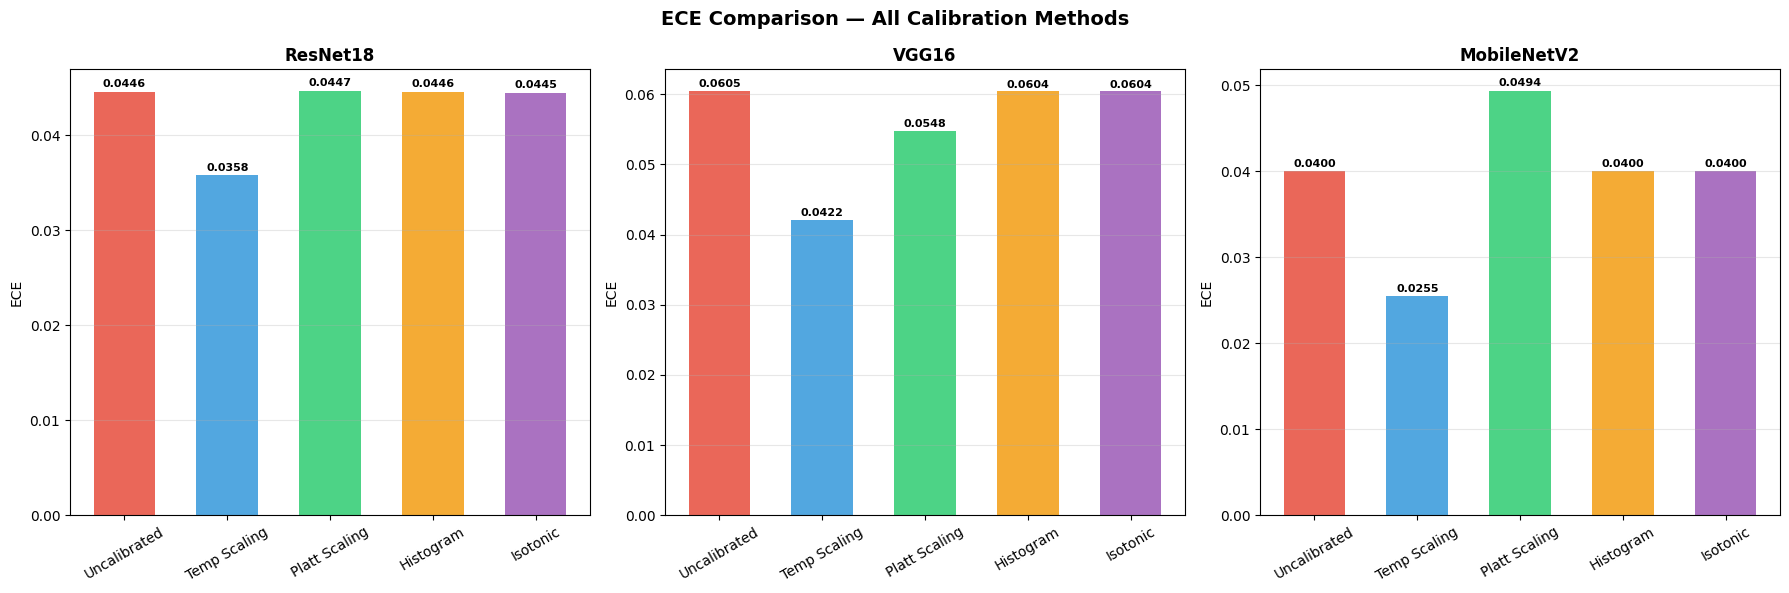

  ✅ Saved: calibration_methods_comparison.png


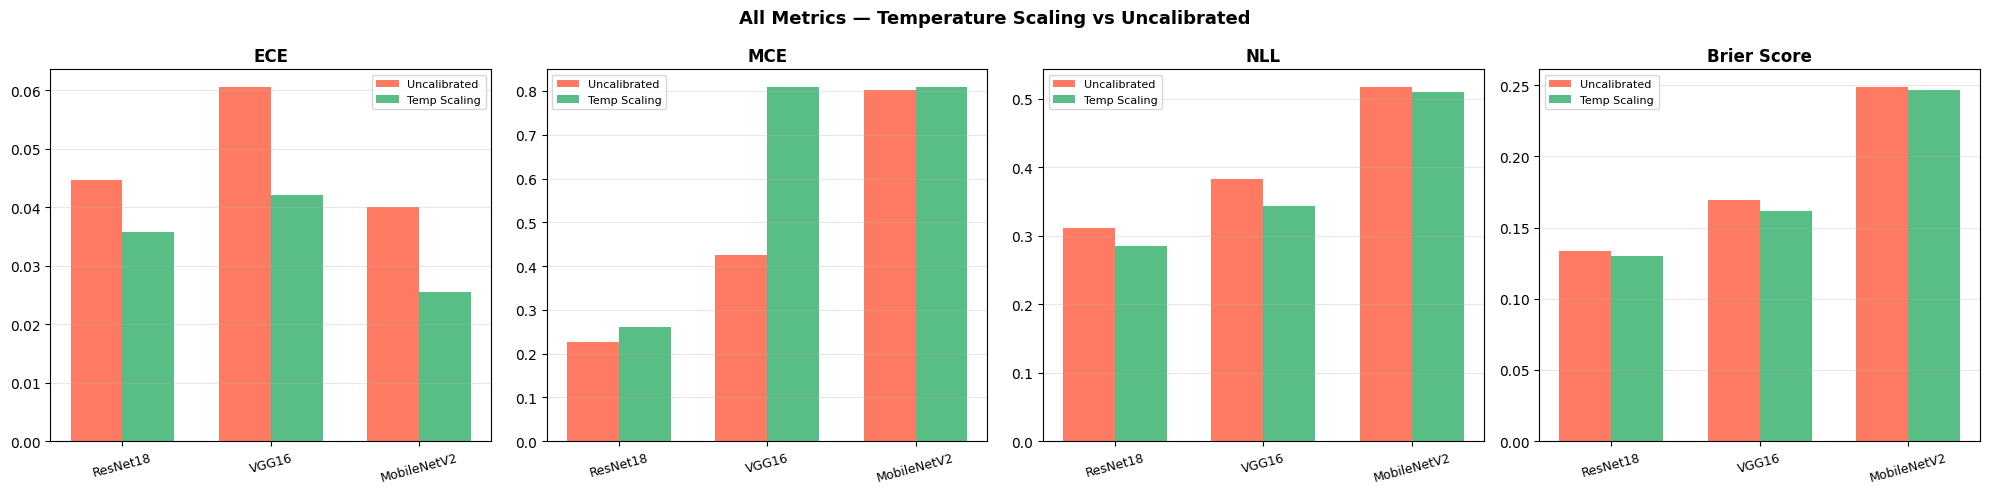

  ✅ Saved: all_metrics_comparison.png


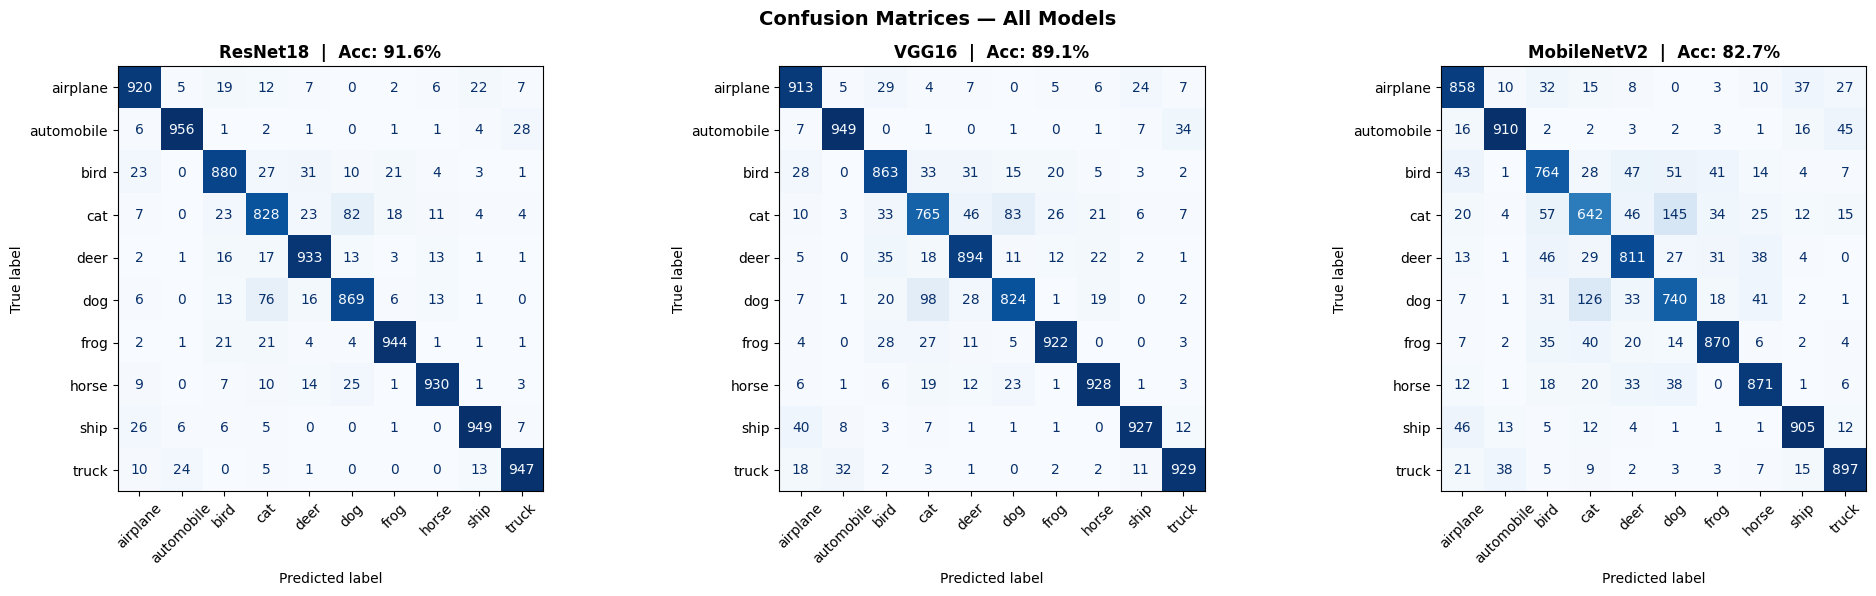

  ✅ Saved: confusion_matrices.png


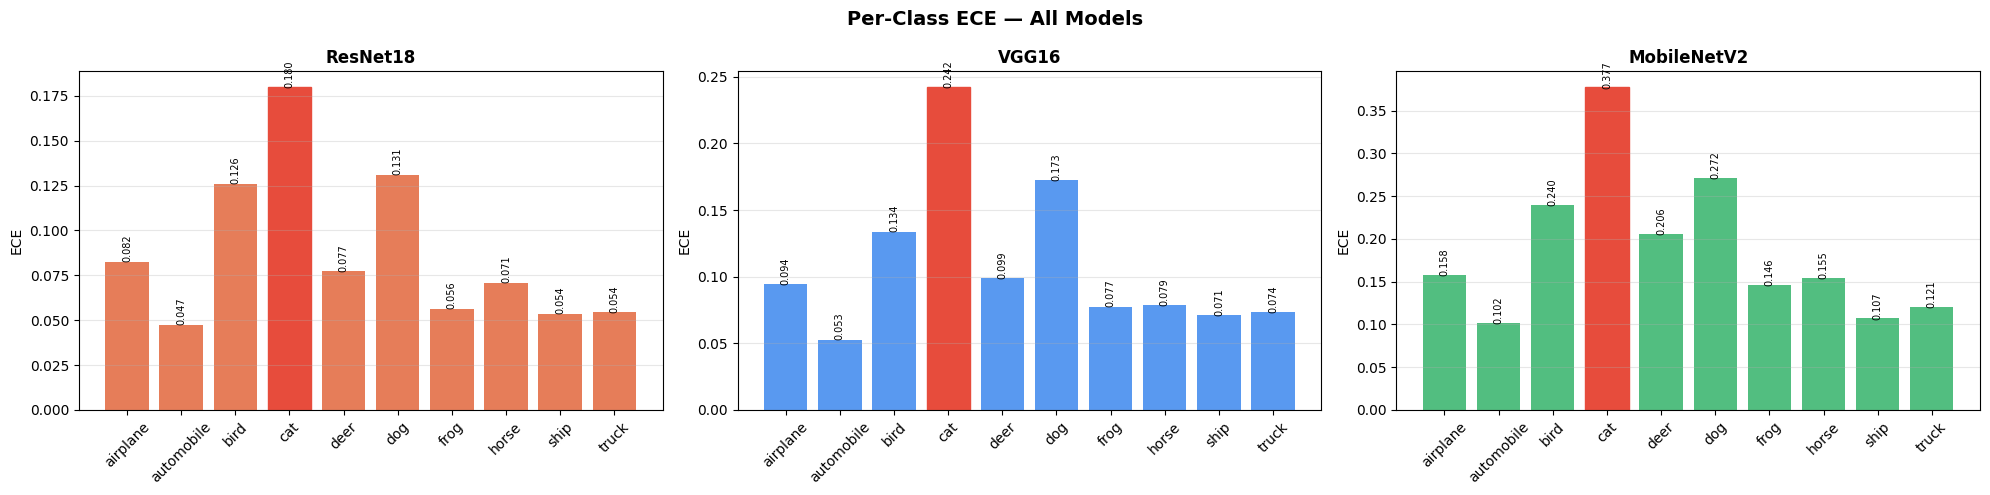

  ✅ Saved: per_class_ece.png


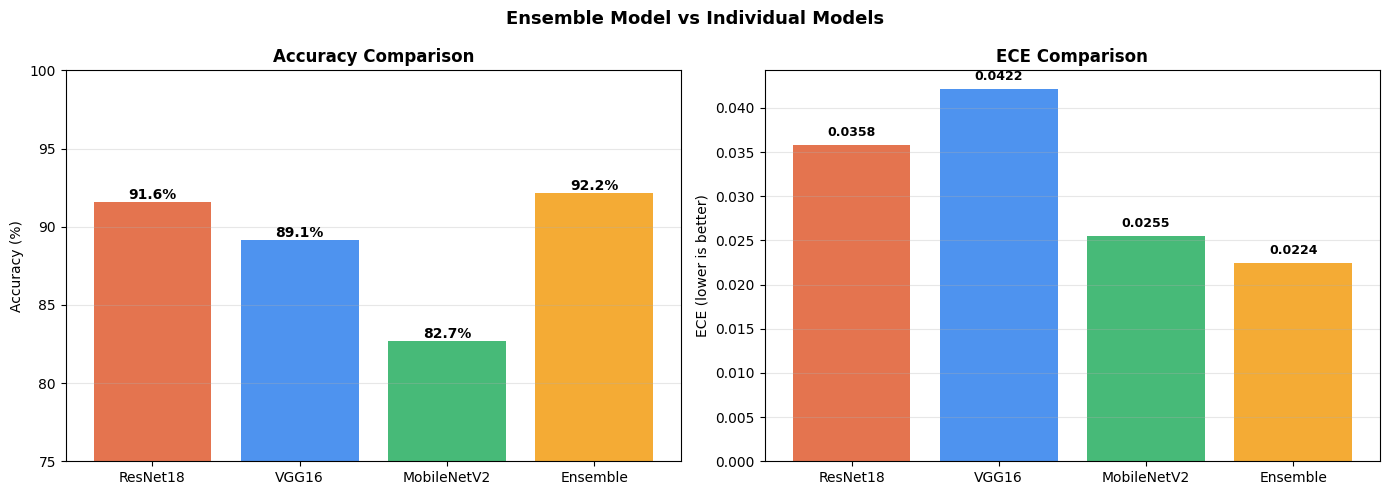

  ✅ Saved: ensemble_comparison.png


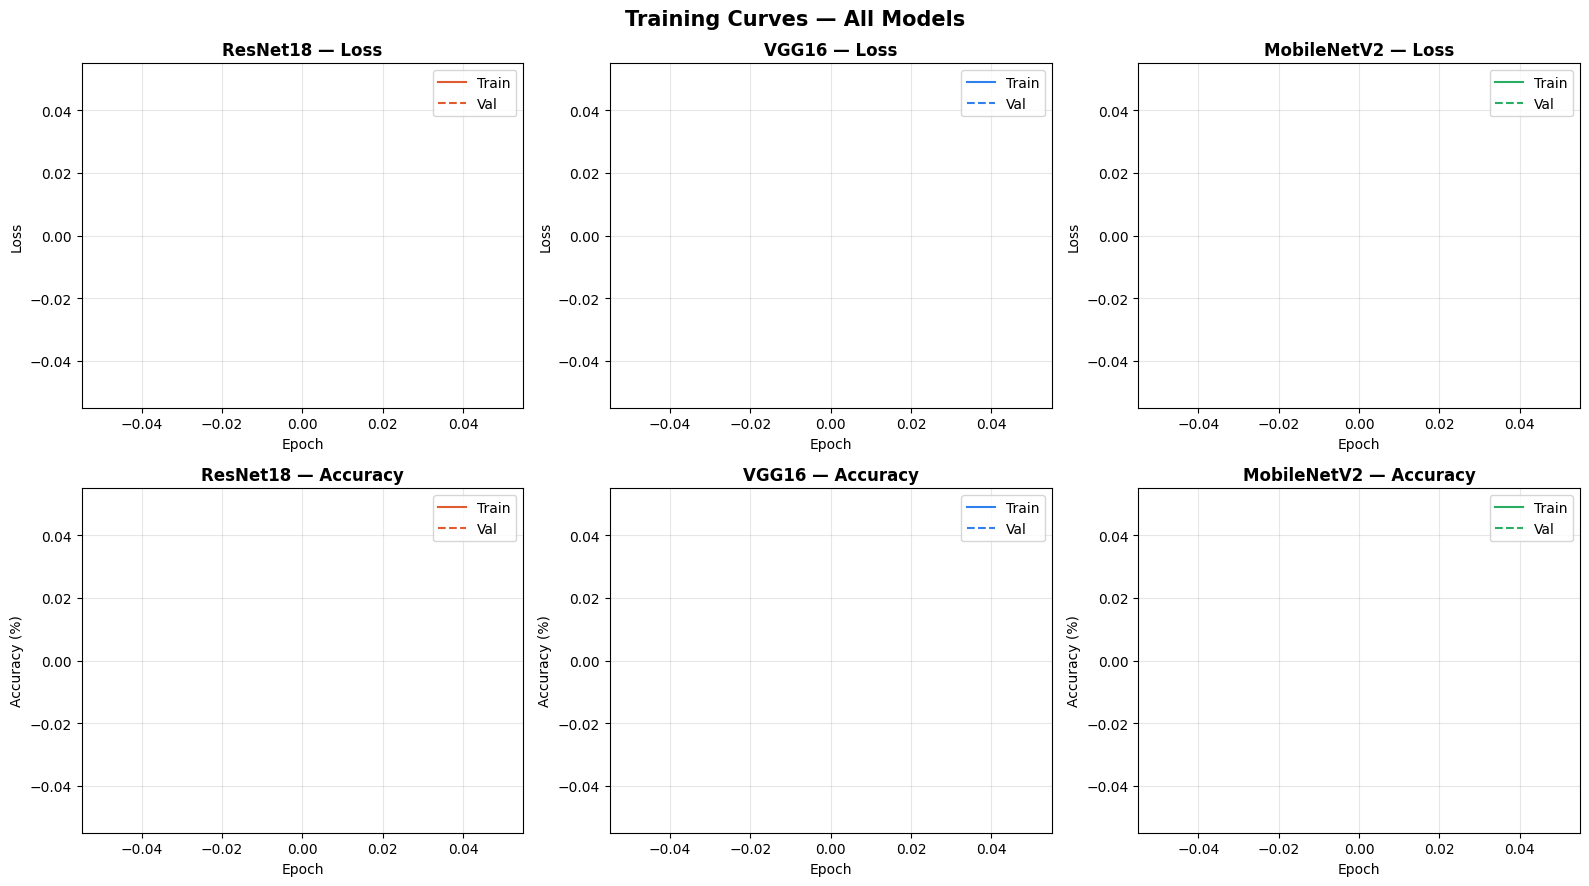

  ✅ Saved: training_curves.png


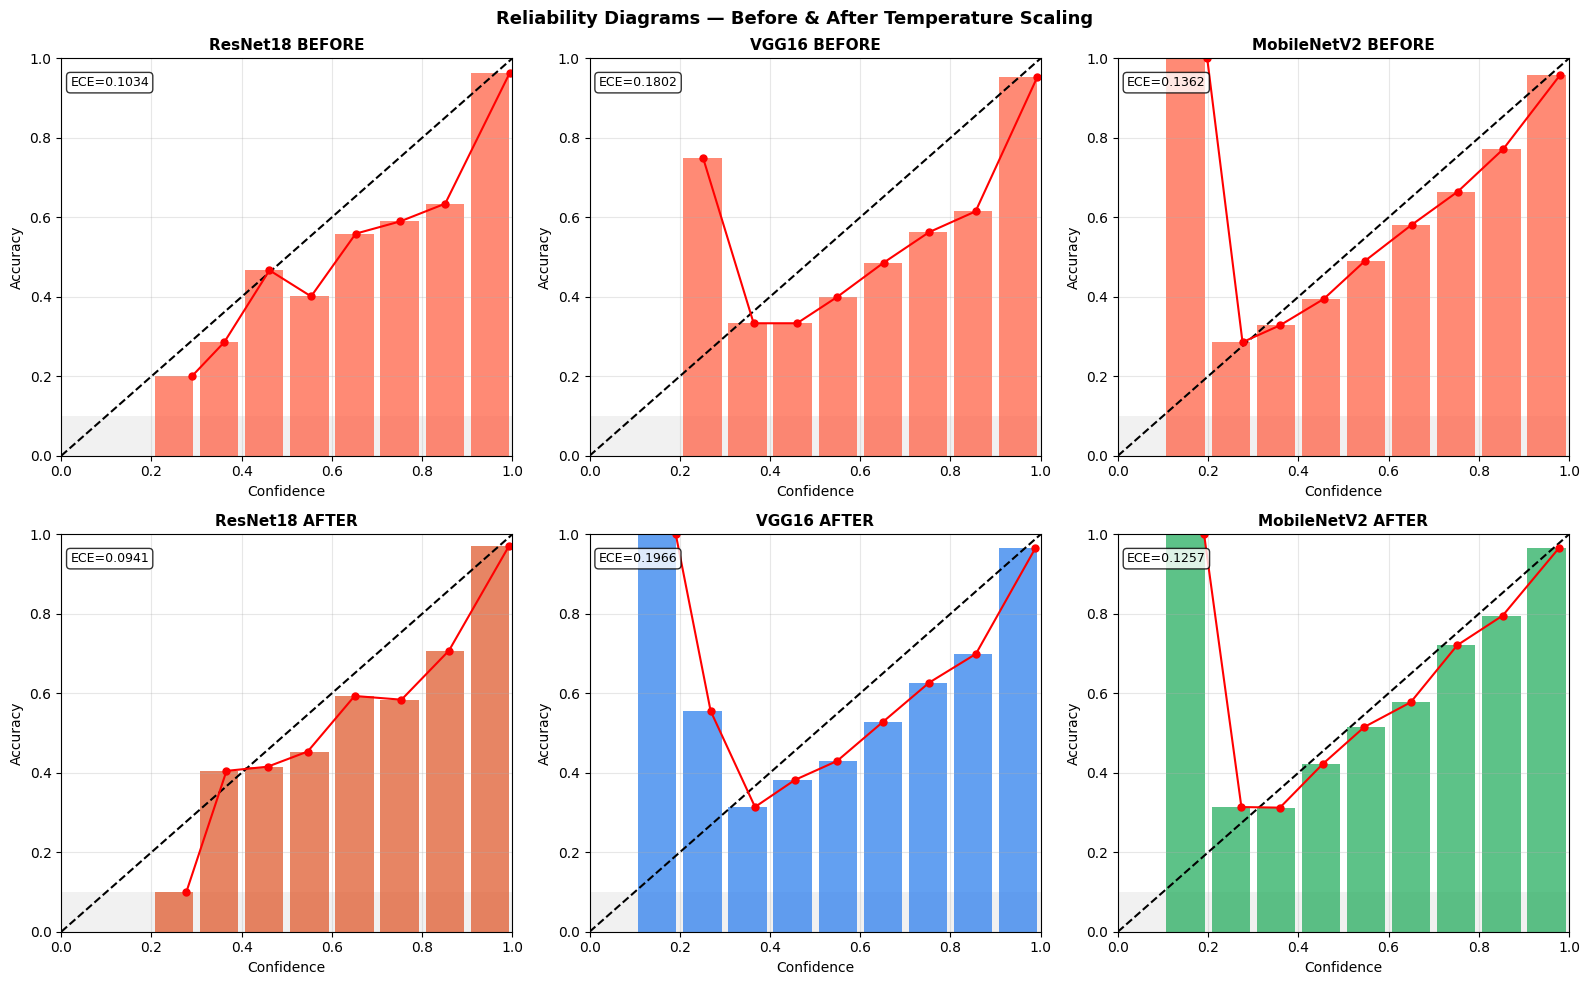

  ✅ Saved: reliability_diagrams.png


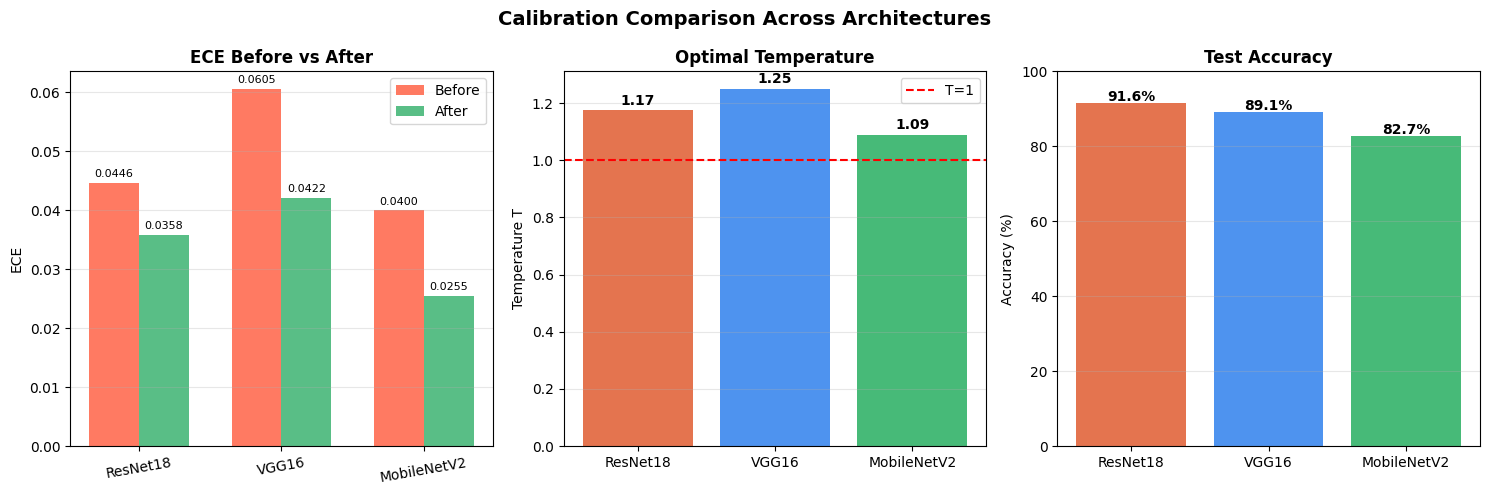

  ✅ Saved: calibration_comparison.png


                       ✅ CELL 4 COMPLETE!                        

Models saved:
  resnet18.pth | vgg16.pth | mobilenet.pth

Plots saved (8 files):
  training_curves.png, reliability_diagrams.png
  calibration_comparison.png, calibration_methods_comparison.png
  all_metrics_comparison.png, confusion_matrices.png
  per_class_ece.png, ensemble_comparison.png

Ensemble Accuracy:             92.15%
Ensemble ECE:                  0.0224

📂 Using: dashboard_data.json
☁️  Backed up to Drive: dashboard_data.json

✅ dashboard_data.json updated!
   Keys now: ['acc', 'eceBefore', 'eceAfter', 'T', 'reduction', 'color', 'trainLoss', 'valLoss', 'trainAcc', 'valAcc', 'reliabBefore', 'reliabAfter', 'histBefore', 'histAfter', 'extendedMetrics', 'perClassECE', 'history', 'per_class_ece', 'calibration_methods']

✅ extra_results dict ready!
🚀 Restart the server — both tabs will now work!


In [11]:
#phase 3 new
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, brier_score_loss
from sklearn.preprocessing import label_binarize
import warnings
warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("="*65)
print("🚀 CELL 4 — PROJECT ENHANCEMENTS")
print("="*65)

MODELS      = ['ResNet18', 'VGG16', 'MobileNetV2']
CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']
colors      = {'ResNet18':'#e05c30', 'VGG16':'#2f80ed', 'MobileNetV2':'#27ae60', 'Ensemble':'#f39c12'}

# ── Helper: get acc from results dict regardless of key name ──
def get_acc(name):
    r = results[name]
    if 'acc' in r:
        return r['acc']
    elif 'accuracy' in r:
        return r['accuracy'] * 100
    else:
        return 0.0

# ============================================================
# STEP 1 — SAVE MODELS
# ============================================================
print("\n📦 STEP 1: Saving models...")
for name in MODELS:
    fname = name.lower().replace('mobilenetv2','mobilenet_v2') + '.pth'
    torch.save(results[name]['model'].state_dict(), fname)
    print(f"  ✅ Saved: {fname}")
print("✅ All models saved! You will never need to retrain.")

# ============================================================
# STEP 2 — HELPERS
# ============================================================
def get_logits_labels(model, loader):
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            logits = model(imgs.to(device))
            all_logits.append(logits.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.vstack(all_logits), np.array(all_labels)

def get_probs_labels(model, loader):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            probs = F.softmax(model(imgs.to(device)), dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.vstack(all_probs), np.array(all_labels)

def compute_ece_np(probs, labels, n_bins=15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    bins = np.linspace(0, 1, n_bins + 1)
    ece  = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            ece += np.abs((pred[mask] == labels[mask]).mean() - conf[mask].mean()) * mask.mean()
    return float(ece)

def compute_mce(probs, labels, n_bins=15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    bins = np.linspace(0, 1, n_bins + 1)
    mce  = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            mce = max(mce, np.abs((pred[mask] == labels[mask]).mean() - conf[mask].mean()))
    return float(mce)

def compute_nll(probs, labels):
    probs_clipped = np.clip(probs, 1e-10, 1.0)
    return float(-np.mean(np.log(probs_clipped[np.arange(len(labels)), labels])))

def compute_brier(probs, labels, n_classes=10):
    labels_bin = label_binarize(labels, classes=list(range(n_classes)))
    return float(np.mean(np.sum((probs - labels_bin)**2, axis=1)))

# ============================================================
# STEP 3 — PLATT SCALING
# ============================================================
print("\n🔧 STEP 3: Platt Scaling...")

def platt_scaling(model_name):
    model = results[model_name]['model']
    val_logits,  val_labels  = get_logits_labels(model, val_loader)
    test_logits, test_labels = get_logits_labels(model, test_loader)
    platt = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs', multi_class='multinomial')
    platt.fit(val_logits, val_labels)
    probs = platt.predict_proba(test_logits)
    ece   = compute_ece_np(probs, test_labels)
    mce   = compute_mce(probs, test_labels)
    nll   = compute_nll(probs, test_labels)
    brier = compute_brier(probs, test_labels)
    acc   = float((probs.argmax(axis=1) == test_labels).mean() * 100)
    return {'ece': ece, 'mce': mce, 'nll': nll, 'brier': brier, 'acc': acc, 'probs': probs, 'labels': test_labels}

platt_results = {}
for name in MODELS:
    platt_results[name] = platt_scaling(name)
    print(f"  ✅ {name}: ECE={platt_results[name]['ece']:.4f}  ACC={platt_results[name]['acc']:.1f}%")

# ============================================================
# STEP 4 — HISTOGRAM BINNING
# ============================================================
print("\n📊 STEP 4: Histogram Binning...")

def histogram_binning(model_name, n_bins=15):
    model = results[model_name]['model']
    val_probs,  val_labels  = get_probs_labels(model, val_loader)
    test_probs, test_labels = get_probs_labels(model, test_loader)
    val_conf  = val_probs.max(axis=1)
    val_pred  = val_probs.argmax(axis=1)
    val_acc   = (val_pred == val_labels).astype(float)
    bins       = np.linspace(0, 1, n_bins + 1)
    bin_target = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (val_conf > lo) & (val_conf <= hi)
        bin_target.append(val_acc[mask].mean() if mask.sum() > 0 else (lo + hi) / 2)
    test_conf = test_probs.max(axis=1)
    test_pred = test_probs.argmax(axis=1)
    cal_conf  = np.zeros_like(test_conf)
    for i, (lo, hi) in enumerate(zip(bins[:-1], bins[1:])):
        mask = (test_conf > lo) & (test_conf <= hi)
        if mask.sum() > 0:
            cal_conf[mask] = bin_target[i]
    cal_probs = test_probs.copy()
    for i in range(len(test_labels)):
        scale = cal_conf[i] / (test_conf[i] + 1e-10)
        cal_probs[i] = cal_probs[i] * scale
        cal_probs[i] = cal_probs[i] / (cal_probs[i].sum() + 1e-10)
    ece   = compute_ece_np(cal_probs, test_labels)
    mce   = compute_mce(cal_probs, test_labels)
    nll   = compute_nll(cal_probs, test_labels)
    brier = compute_brier(cal_probs, test_labels)
    acc   = float((cal_probs.argmax(axis=1) == test_labels).mean() * 100)
    return {'ece': ece, 'mce': mce, 'nll': nll, 'brier': brier, 'acc': acc, 'probs': cal_probs, 'labels': test_labels}

hist_results = {}
for name in MODELS:
    hist_results[name] = histogram_binning(name)
    print(f"  ✅ {name}: ECE={hist_results[name]['ece']:.4f}  ACC={hist_results[name]['acc']:.1f}%")

# ============================================================
# STEP 5 — ISOTONIC REGRESSION
# ============================================================
print("\n📈 STEP 5: Isotonic Regression...")

def isotonic_regression_cal(model_name):
    model = results[model_name]['model']
    val_probs,  val_labels  = get_probs_labels(model, val_loader)
    test_probs, test_labels = get_probs_labels(model, test_loader)
    val_conf  = val_probs.max(axis=1)
    val_pred  = val_probs.argmax(axis=1)
    val_acc   = (val_pred == val_labels).astype(float)
    iso = IsotonicRegression(out_of_bounds='clip')
    iso.fit(val_conf, val_acc)
    test_conf = test_probs.max(axis=1)
    cal_conf  = iso.predict(test_conf)
    cal_probs = test_probs.copy()
    for i in range(len(test_labels)):
        scale = cal_conf[i] / (test_conf[i] + 1e-10)
        cal_probs[i] = cal_probs[i] * scale
        cal_probs[i] = cal_probs[i] / (cal_probs[i].sum() + 1e-10)
    ece   = compute_ece_np(cal_probs, test_labels)
    mce   = compute_mce(cal_probs, test_labels)
    nll   = compute_nll(cal_probs, test_labels)
    brier = compute_brier(cal_probs, test_labels)
    acc   = float((cal_probs.argmax(axis=1) == test_labels).mean() * 100)
    return {'ece': ece, 'mce': mce, 'nll': nll, 'brier': brier, 'acc': acc, 'probs': cal_probs, 'labels': test_labels}

isotonic_results = {}
for name in MODELS:
    isotonic_results[name] = isotonic_regression_cal(name)
    print(f"  ✅ {name}: ECE={isotonic_results[name]['ece']:.4f}  ACC={isotonic_results[name]['acc']:.1f}%")

# ============================================================
# STEP 6 — ENSEMBLE MODEL
# ============================================================
print("\n🤝 STEP 6: Ensemble Model...")

def ensemble_model():
    all_probs = []
    test_labels_ref = None
    for name in MODELS:
        probs, labels = get_probs_labels(results[name]['model'], test_loader)
        all_probs.append(probs)
        test_labels_ref = labels
    ensemble_probs = np.mean(all_probs, axis=0)
    acc   = float((ensemble_probs.argmax(axis=1) == test_labels_ref).mean() * 100)
    ece   = compute_ece_np(ensemble_probs, test_labels_ref)
    mce   = compute_mce(ensemble_probs, test_labels_ref)
    nll   = compute_nll(ensemble_probs, test_labels_ref)
    brier = compute_brier(ensemble_probs, test_labels_ref)
    return {'ece': ece, 'mce': mce, 'nll': nll, 'brier': brier,
            'acc': acc, 'probs': ensemble_probs, 'labels': test_labels_ref}

ensemble_res = ensemble_model()
print(f"  ✅ Ensemble: ACC={ensemble_res['acc']:.2f}%  ECE={ensemble_res['ece']:.4f}")

# ============================================================
# STEP 6b — ENSEMBLE TEMPERATURE SCALING
# ============================================================
print("\n🌡️  STEP 6b: Ensemble Temperature Scaling...")

import torch.optim as optim

class EnsembleTempScaler(nn.Module):
    def __init__(self, models_list):
        super().__init__()
        self.models = models_list
        self.T = nn.Parameter(torch.ones(1) * 1.5)

    def forward(self, x):
        logits = [m(x) for m in self.models]
        avg_logits = torch.stack(logits, dim=0).mean(0)
        return avg_logits / self.T

    def fit(self, loader):
        for m in self.models:
            m.eval()
        all_logits, all_labels = [], []
        with torch.no_grad():
            for imgs, labels in loader:
                imgs = imgs.to(device)
                logits = torch.stack([m(imgs) for m in self.models]).mean(0)
                all_logits.append(logits.cpu())
                all_labels.append(labels)
        logits_all = torch.cat(all_logits).to(device)
        labels_all = torch.cat(all_labels).to(device)

        optimizer = optim.LBFGS([self.T], lr=0.01, max_iter=100)
        def closure():
            optimizer.zero_grad()
            loss = nn.CrossEntropyLoss()(logits_all / self.T, labels_all)
            loss.backward()
            return loss
        optimizer.step(closure)
        return self.T.item()

# ── Compute ECE on raw ensemble (before calibration) ──
def compute_ece_ensemble_raw(models_list, loader, n_bins=15):
    for m in models_list:
        m.eval()
    all_conf, all_pred, all_label = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            logits = torch.stack([m(imgs) for m in models_list]).mean(0)
            probs = F.softmax(logits, dim=1)
            conf, pred = probs.max(1)
            all_conf.append(conf.cpu())
            all_pred.append(pred.cpu())
            all_label.append(labels)
    conf  = torch.cat(all_conf).numpy()
    pred  = torch.cat(all_pred).numpy()
    label = torch.cat(all_label).numpy()
    bins  = np.linspace(0, 1, n_bins + 1)
    ece   = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            ece += np.abs((pred[mask] == label[mask]).mean() - conf[mask].mean()) * mask.mean()
    return float(ece), conf, pred, label

# ── Run it ──
model_list = [results[n]['model'] for n in MODELS]

ece_ens_before, _, _, _ = compute_ece_ensemble_raw(model_list, test_loader)

ens_scaler = EnsembleTempScaler(model_list).to(device)
T_ens      = ens_scaler.fit(val_loader)

# Get calibrated predictions
ens_probs_cal, ens_labels_cal = get_probs_labels(ens_scaler, test_loader)
ece_ens_after  = compute_ece_np(ens_probs_cal, ens_labels_cal)
mce_ens_after  = compute_mce(ens_probs_cal, ens_labels_cal)
nll_ens_after  = compute_nll(ens_probs_cal, ens_labels_cal)
brier_ens_after = compute_brier(ens_probs_cal, ens_labels_cal)
acc_ens_after  = float((ens_probs_cal.argmax(axis=1) == ens_labels_cal).mean() * 100)
reduction_ens  = (ece_ens_before - ece_ens_after) / ece_ens_before * 100

print(f"\n  Ensemble Temperature : {T_ens:.3f}")
print(f"  ECE Before           : {ece_ens_before:.4f}")
print(f"  ECE After            : {ece_ens_after:.4f}")
print(f"  ECE Reduction        : {reduction_ens:.1f}%")
print(f"  Accuracy             : {acc_ens_after:.2f}%")

# ── Update ensemble_res so export cell picks it up ──
ensemble_res.update({
    'ece_before': ece_ens_before,
    'ece':        ece_ens_after,
    'ece_after':  ece_ens_after,
    'mce':        mce_ens_after,
    'nll':        nll_ens_after,
    'brier':      brier_ens_after,
    'acc':        acc_ens_after,
    'T':          T_ens,
    'reduction':  reduction_ens,
})

# ── Also update results dict ──
results['Ensemble'] = {
    'acc':        acc_ens_after,
    'ece_before': ece_ens_before,
    'ece_after':  ece_ens_after,
    'T':          T_ens,
    'reduction':  reduction_ens,
    'history':    results['ResNet18']['history'],
    'conf_b':     ensemble_res['probs'].max(axis=1),
    'pred_b':     ensemble_res['probs'].argmax(axis=1),
    'label_b':    ensemble_res['labels'],
    'conf_a':     ens_probs_cal.max(axis=1),
    'pred_a':     ens_probs_cal.argmax(axis=1),
    'label_a':    ens_labels_cal,
    'scaler':     ens_scaler,
}

print(f"\n✅ Ensemble temp scaling done! ensemble_res and results['Ensemble'] updated.")
print(f"   Run the export cell next — it will pick up the calibrated ECE automatically.")

# ── Rebuild scalers ──────────────────────────────────────────
class TempScaler(nn.Module):
    def __init__(self, model, T):
        super().__init__()
        self.model = model
        self.T     = T
    def forward(self, x):
        return self.model(x) / self.T

for name in MODELS:
    T = results[name]['T']
    results[name]['scaler'] = TempScaler(results[name]['model'], T).to(device).eval()
    # Also normalise acc key so everything downstream uses 'acc' as percentage
    if 'acc' not in results[name] and 'accuracy' in results[name]:
        results[name]['acc'] = results[name]['accuracy'] * 100
print("✅ Scalers rebuilt!")

# ============================================================
# STEP 7 — EXTENDED METRICS (Temperature Scaling)
# ============================================================
print("\n📋 STEP 7: Computing all metrics for Temperature Scaling...")

extended_metrics = {}
for name in MODELS:
    probs, labels = get_probs_labels(results[name]['scaler'], test_loader)
    extended_metrics[name] = {
        'ece':   compute_ece_np(probs, labels),
        'mce':   compute_mce(probs, labels),
        'nll':   compute_nll(probs, labels),
        'brier': compute_brier(probs, labels),
        'acc':   float((probs.argmax(axis=1) == labels).mean() * 100),
        'probs': probs, 'labels': labels
    }

# ============================================================
# STEP 8 — PER-CLASS ECE
# ============================================================
print("\n🔍 STEP 8: Per-Class ECE...")

per_class_ece = {}
for name in MODELS:
    model = results[name]['model']
    model.eval()
    class_conf    = {i: [] for i in range(10)}
    class_correct = {i: [] for i in range(10)}
    with torch.no_grad():
        for imgs, labels in test_loader:
            probs = F.softmax(model(imgs.to(device)), dim=1)
            conf, pred = probs.max(1)
            for i in range(len(labels)):
                c = labels[i].item()
                class_conf[c].append(conf[i].item())
                class_correct[c].append((pred[i] == labels[i]).item())
    per_class_ece[name] = [
        np.mean(np.abs(np.array(class_conf[i]) - np.array(class_correct[i])))
        for i in range(10)
    ]
print("  ✅ Per-Class ECE computed for all models")

# ============================================================
# STEP 9 — PRINT FULL COMPARISON TABLE
# ============================================================
print("\n")
print("="*90)
print(f"{'COMPREHENSIVE RESULTS — ALL CALIBRATION METHODS':^90}")
print("="*90)
print(f"{'Model':<14} {'Method':<22} {'Accuracy':>10} {'ECE':>8} {'MCE':>8} {'NLL':>8} {'Brier':>8}")
print("-"*90)

for name in MODELS:
    raw_probs, raw_labels = get_probs_labels(results[name]['model'], test_loader)
    raw_acc = float((raw_probs.argmax(1) == raw_labels).mean() * 100)
    print(f"{name:<14} {'Uncalibrated':<22} {raw_acc:>9.2f}% {compute_ece_np(raw_probs,raw_labels):>8.4f} "
          f"{compute_mce(raw_probs,raw_labels):>8.4f} {compute_nll(raw_probs,raw_labels):>8.4f} "
          f"{compute_brier(raw_probs,raw_labels):>8.4f}")
    m = extended_metrics[name]
    print(f"{'':14} {'Temperature Scaling':<22} {m['acc']:>9.2f}% {m['ece']:>8.4f} {m['mce']:>8.4f} {m['nll']:>8.4f} {m['brier']:>8.4f}")
    p = platt_results[name]
    print(f"{'':14} {'Platt Scaling':<22} {p['acc']:>9.2f}% {p['ece']:>8.4f} {p['mce']:>8.4f} {p['nll']:>8.4f} {p['brier']:>8.4f}")
    h = hist_results[name]
    print(f"{'':14} {'Histogram Binning':<22} {h['acc']:>9.2f}% {h['ece']:>8.4f} {h['mce']:>8.4f} {h['nll']:>8.4f} {h['brier']:>8.4f}")
    iso = isotonic_results[name]
    print(f"{'':14} {'Isotonic Regression':<22} {iso['acc']:>9.2f}% {iso['ece']:>8.4f} {iso['mce']:>8.4f} {iso['nll']:>8.4f} {iso['brier']:>8.4f}")
    print("-"*90)

e = ensemble_res
print(f"{'ENSEMBLE':<14} {'(Avg 3 Models)':<22} {e['acc']:>9.2f}% {e['ece']:>8.4f} {e['mce']:>8.4f} {e['nll']:>8.4f} {e['brier']:>8.4f}")
print("="*90)

# ============================================================
# STEP 10 — PLOTS
# ============================================================
print("\n📈 STEP 10: Generating all plots...")

# ── Plot 1: Calibration Method Comparison ──
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('ECE Comparison — All Calibration Methods', fontsize=14, fontweight='bold')
method_names  = ['Uncalibrated', 'Temp Scaling', 'Platt Scaling', 'Histogram', 'Isotonic']
method_colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
for col, name in enumerate(MODELS):
    raw_probs, raw_labels = get_probs_labels(results[name]['model'], test_loader)
    ece_vals = [
        compute_ece_np(raw_probs, raw_labels),
        extended_metrics[name]['ece'],
        platt_results[name]['ece'],
        hist_results[name]['ece'],
        isotonic_results[name]['ece'],
    ]
    bars = axes[col].bar(method_names, ece_vals, color=method_colors, alpha=0.85, width=0.6)
    axes[col].set_title(f'{name}', fontweight='bold', fontsize=12)
    axes[col].set_ylabel('ECE')
    axes[col].tick_params(axis='x', rotation=30)
    axes[col].grid(axis='y', alpha=0.3)
    for bar, v in zip(bars, ece_vals):
        axes[col].text(bar.get_x() + bar.get_width()/2, v + 0.0005,
                       f'{v:.4f}', ha='center', fontsize=8, fontweight='bold')
plt.tight_layout()
plt.savefig('calibration_methods_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: calibration_methods_comparison.png")

# ── Plot 2: All Metrics Heatmap ──
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('All Metrics — Temperature Scaling vs Uncalibrated', fontsize=13, fontweight='bold')
metric_names = ['ECE', 'MCE', 'NLL', 'Brier Score']
for mi, metric in enumerate(['ece', 'mce', 'nll', 'brier']):
    raw_vals, cal_vals = [], []
    for name in MODELS:
        raw_p, raw_l = get_probs_labels(results[name]['model'], test_loader)
        raw_vals.append(getattr(
            type('obj', (object,), {
                'ece': compute_ece_np(raw_p, raw_l),
                'mce': compute_mce(raw_p, raw_l),
                'nll': compute_nll(raw_p, raw_l),
                'brier': compute_brier(raw_p, raw_l)
            })(), metric))
        cal_vals.append(extended_metrics[name][metric])
    x = np.arange(len(MODELS)); w = 0.35
    axes[mi].bar(x - w/2, raw_vals, w, label='Uncalibrated', color='tomato',         alpha=0.85)
    axes[mi].bar(x + w/2, cal_vals, w, label='Temp Scaling', color='mediumseagreen', alpha=0.85)
    axes[mi].set_xticks(x)
    axes[mi].set_xticklabels(MODELS, rotation=15, fontsize=9)
    axes[mi].set_title(metric_names[mi], fontweight='bold')
    axes[mi].legend(fontsize=8)
    axes[mi].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('all_metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: all_metrics_comparison.png")

# ── Plot 3: Confusion Matrices ── (FIXED: uses get_acc helper)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Confusion Matrices — All Models', fontsize=14, fontweight='bold')
for col, name in enumerate(MODELS):
    model = results[name]['model']
    model.eval()
    all_preds, all_labels_cm = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            preds = model(imgs.to(device)).argmax(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels_cm.extend(labels.numpy())
    cm   = confusion_matrix(all_labels_cm, all_preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
    disp.plot(ax=axes[col], cmap='Blues', colorbar=False)
    axes[col].set_title(f'{name}  |  Acc: {get_acc(name):.1f}%', fontweight='bold')  # ← FIXED
    axes[col].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: confusion_matrices.png")

# ── Plot 4: Per-Class ECE ──
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle('Per-Class ECE — All Models', fontsize=14, fontweight='bold')
for col, name in enumerate(MODELS):
    ece_vals = per_class_ece[name]
    c        = colors[name]
    bars     = axes[col].bar(CLASS_NAMES, ece_vals, color=c, alpha=0.8)
    axes[col].set_title(f'{name}', fontweight='bold')
    axes[col].set_ylabel('ECE')
    axes[col].tick_params(axis='x', rotation=45)
    axes[col].grid(axis='y', alpha=0.3)
    worst = np.argmax(ece_vals)
    bars[worst].set_color('#e74c3c')
    bars[worst].set_alpha(1.0)
    for bar, v in zip(bars, ece_vals):
        axes[col].text(bar.get_x() + bar.get_width()/2, v + 0.001,
                       f'{v:.3f}', ha='center', fontsize=7, rotation=90)
plt.tight_layout()
plt.savefig('per_class_ece.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: per_class_ece.png")

# ── Plot 5: Ensemble vs Individual ── (FIXED: uses get_acc helper)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Ensemble Model vs Individual Models', fontsize=13, fontweight='bold')
all_names = MODELS + ['Ensemble']
all_accs  = [get_acc(n) for n in MODELS] + [ensemble_res['acc']]  # ← FIXED
all_eces  = [results[n].get('ece_after', results[n].get('eceAfter', 0)) for n in MODELS] + [ensemble_res['ece']]
bar_cols  = [colors[n] for n in MODELS] + ['#f39c12']
axes[0].bar(all_names, all_accs, color=bar_cols, alpha=0.85)
axes[0].set_title('Accuracy Comparison', fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim([75, 100])
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(all_accs):
    axes[0].text(i, v + 0.2, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].bar(all_names, all_eces, color=bar_cols, alpha=0.85)
axes[1].set_title('ECE Comparison', fontweight='bold')
axes[1].set_ylabel('ECE (lower is better)')
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate(all_eces):
    axes[1].text(i, v + 0.001, f'{v:.4f}', ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.savefig('ensemble_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: ensemble_comparison.png")

# ── Plot 6: Training Curves ──
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Training Curves — All Models', fontsize=15, fontweight='bold')
for col, name in enumerate(MODELS):
    h  = results[name]['history']
    ep = range(1, len(h['train_loss'])+1)
    c  = colors[name]
    axes[0,col].plot(ep, h['train_loss'], label='Train', color=c)
    axes[0,col].plot(ep, h['val_loss'],   label='Val',   color=c, linestyle='--')
    axes[0,col].set_title(f'{name} — Loss', fontweight='bold')
    axes[0,col].set_xlabel('Epoch'); axes[0,col].set_ylabel('Loss')
    axes[0,col].legend(); axes[0,col].grid(True, alpha=0.3)
    axes[1,col].plot(ep, h['train_acc'], label='Train', color=c)
    axes[1,col].plot(ep, h['val_acc'],   label='Val',   color=c, linestyle='--')
    axes[1,col].set_title(f'{name} — Accuracy', fontweight='bold')
    axes[1,col].set_xlabel('Epoch'); axes[1,col].set_ylabel('Accuracy (%)')
    axes[1,col].legend(); axes[1,col].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: training_curves.png")

# ── Plot 7: Reliability Diagrams ──
def plot_reliability(conf, pred, label, title, ax, color='steelblue', n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    bin_acc, bin_conf = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            bin_acc.append((pred[mask] == label[mask]).mean())
            bin_conf.append(conf[mask].mean())
    width   = 1.0 / n_bins
    centers = [(lo+hi)/2 for lo, hi in zip(bins[:-1], bins[1:])]
    bar_acc = []
    for c in centers:
        idx = np.argmin([abs(bc - c) for bc in bin_conf]) if bin_conf else None
        bar_acc.append(bin_acc[idx] if idx is not None and abs(bin_conf[idx]-c) < width else 0)
    ax.bar(centers, [width]*len(centers), width=width,      color='lightgray', alpha=0.3, align='center')
    ax.bar(centers, bar_acc,              width=width*0.85, color=color,       alpha=0.75, align='center')
    ax.plot([0,1],[0,1],'k--', linewidth=1.5)
    ax.plot(bin_conf, bin_acc, 'o-', color='red', markersize=5, linewidth=1.5)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel('Confidence'); ax.set_ylabel('Accuracy')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ece_v = np.mean([abs(a-c) for a,c in zip(bin_acc,bin_conf)]) if bin_acc else 0
    ax.text(0.02, 0.93, f'ECE={ece_v:.4f}', transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Reliability Diagrams — Before & After Temperature Scaling', fontsize=13, fontweight='bold')
for col, name in enumerate(MODELS):
    r = results[name]; c = colors[name]
    plot_reliability(r['conf_b'], r['pred_b'], r['label_b'],
                     f'{name} BEFORE', axes[0,col], color='tomato')
    plot_reliability(r['conf_a'], r['pred_a'], r['label_a'],
                     f'{name} AFTER',  axes[1,col], color=c)
plt.tight_layout()
plt.savefig('reliability_diagrams.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: reliability_diagrams.png")

# ── Plot 8: Calibration Comparison ── (FIXED: uses get_acc helper)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Calibration Comparison Across Architectures', fontsize=14, fontweight='bold')
names     = [n for n in results.keys() if n != 'Ensemble']
ece_b     = [results[n].get('ece_before', results[n].get('eceBefore', 0)) for n in names]
ece_a     = [results[n].get('ece_after',  results[n].get('eceAfter',  0)) for n in names]
temps     = [results[n]['T'] for n in names]
accs      = [get_acc(n) for n in names]  # ← FIXED
x         = np.arange(len(names)); w = 0.35
bar_cols2 = [colors.get(n, '#aaaaaa') for n in names]
axes[0].bar(x-w/2, ece_b, w, label='Before', color='tomato',         alpha=0.85)
axes[0].bar(x+w/2, ece_a, w, label='After',  color='mediumseagreen', alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(names, rotation=10)
axes[0].set_ylabel('ECE'); axes[0].set_title('ECE Before vs After', fontweight='bold')
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
for i,(b,a) in enumerate(zip(ece_b,ece_a)):
    axes[0].text(i-w/2, b+0.001, f'{b:.4f}', ha='center', fontsize=8)
    axes[0].text(i+w/2, a+0.001, f'{a:.4f}', ha='center', fontsize=8)
axes[1].bar(names, temps, color=bar_cols2, alpha=0.85)
axes[1].axhline(1.0, color='red', linestyle='--', label='T=1')
axes[1].set_ylabel('Temperature T'); axes[1].set_title('Optimal Temperature', fontweight='bold')
axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)
for i,t in enumerate(temps):
    axes[1].text(i, t+0.02, f'{t:.2f}', ha='center', fontweight='bold')
axes[2].bar(names, accs, color=bar_cols2, alpha=0.85)
axes[2].set_ylim([0, 100])
axes[2].set_ylabel('Accuracy (%)'); axes[2].set_title('Test Accuracy', fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)
for i,a in enumerate(accs):
    axes[2].text(i, a+0.5, f'{a:.1f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('calibration_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: calibration_comparison.png")

# ============================================================
# FINAL SUMMARY
# ============================================================
print("\n")
print("="*65)
print(f"{'✅ CELL 4 COMPLETE!':^65}")
print("="*65)
print(f"\nModels saved:")
print(f"  resnet18.pth | vgg16.pth | mobilenet.pth")
print(f"\nPlots saved (8 files):")
print(f"  training_curves.png, reliability_diagrams.png")
print(f"  calibration_comparison.png, calibration_methods_comparison.png")
print(f"  all_metrics_comparison.png, confusion_matrices.png")
print(f"  per_class_ece.png, ensemble_comparison.png")
print(f"\n{'Ensemble Accuracy:':<30} {ensemble_res['acc']:.2f}%")
print(f"{'Ensemble ECE:':<30} {ensemble_res['ece']:.4f}")
print("="*65)

# ── Update results dict (uses calibrated ensemble from Step 6b) ──
results['Ensemble'] = {
    'acc':        acc_ens_after,
    'ece_before': ece_ens_before,
    'ece_after':  ece_ens_after,
    'T':          T_ens,
    'reduction':  reduction_ens,
    'history':    results['ResNet18']['history'],
    'conf_b':     ensemble_res['probs'].max(axis=1),
    'pred_b':     ensemble_res['probs'].argmax(axis=1),
    'label_b':    ensemble_res['labels'],
    'conf_a':     ens_probs_cal.max(axis=1),
    'pred_a':     ens_probs_cal.argmax(axis=1),
    'label_a':    ens_labels_cal,
    'scaler':     ens_scaler,
}

# ── Build extra_results & save updated results.json ─────────
extra_results = {
    'platt':         platt_results,
    'histogram':     hist_results,
    'isotonic':      isotonic_results,
    'ensemble':      ensemble_res,   # already updated by Step 6b's ensemble_res.update(...)
    'extended':      extended_metrics,
    'per_class_ece': per_class_ece,
}

# ── Merge into dashboard_data.json / results.json ───────────
import json, os, shutil

try:
    # Auto-detect correct JSON file
    json_file = 'dashboard_data.json' if os.path.exists('dashboard_data.json') else 'results.json'
    print(f"\n📂 Using: {json_file}")

    with open(json_file) as f:
        dashboard = json.load(f)

    for name in MODELS:
        dashboard[name]['per_class_ece'] = per_class_ece[name]
        dashboard[name]['calibration_methods'] = {
            'platt': {
                'ece':   platt_results[name]['ece'],
                'acc':   platt_results[name]['acc'],
                'nll':   platt_results[name]['nll'],
                'brier': platt_results[name]['brier'],
            },
            'histogram': {
                'ece':   hist_results[name]['ece'],
                'acc':   hist_results[name]['acc'],
                'nll':   hist_results[name]['nll'],
                'brier': hist_results[name]['brier'],
            },
            'isotonic': {
                'ece':   isotonic_results[name]['ece'],
                'acc':   isotonic_results[name]['acc'],
                'nll':   isotonic_results[name]['nll'],
                'brier': isotonic_results[name]['brier'],
            },
            'temperature': {
                'ece':   extended_metrics[name]['ece'],
                'acc':   extended_metrics[name]['acc'],
                'nll':   extended_metrics[name]['nll'],
                'brier': extended_metrics[name]['brier'],
            },
        }

    with open(json_file, 'w') as f:
        json.dump(dashboard, f, indent=2)

    # Auto-backup to Drive
    drive_path = f'/content/drive/MyDrive/{json_file}'
    if os.path.exists('/content/drive/MyDrive'):
        shutil.copy(json_file, drive_path)
        print(f"☁️  Backed up to Drive: {json_file}")

    print(f"\n✅ {json_file} updated!")
    print(f"   Keys now: {list(dashboard['ResNet18'].keys())}")

except FileNotFoundError:
    print("\n⚠️  No JSON file found — skipping auto-merge.")

print("\n✅ extra_results dict ready!")
print("🚀 Restart the server — both tabs will now work!")

📊 EDA — CIFAR-10 DATASET ANALYSIS

📦 Loading raw CIFAR-10...
  Train samples : 50,000
  Test  samples : 10,000
  Image size    : 32 × 32 × 3
  Classes       : 10
  Total pixels  : 3,072 per image

📐 Computing raw pixel statistics...

  Raw pixel range : [0.0000, 1.0000]
  Channel means   : R=0.4914  G=0.4822  B=0.4465
  Channel stds    : R=0.2470  G=0.2435  B=0.2616

  Normalization mean (used): [0.4914, 0.4822, 0.4465]
  Normalization std  (used): [0.2023, 0.1994, 0.201]
  ✅ Computed mean matches standard CIFAR-10 values

📊 Class distribution...

  Class              Train     Test   Train%  Balanced?
  -------------------------------------------------------
  airplane           5,000    1,000    10.0%      ✅ Yes
  automobile         5,000    1,000    10.0%      ✅ Yes
  bird               5,000    1,000    10.0%      ✅ Yes
  cat                5,000    1,000    10.0%      ✅ Yes
  deer               5,000    1,000    10.0%      ✅ Yes
  dog                5,000    1,000    10.0%      ✅ 

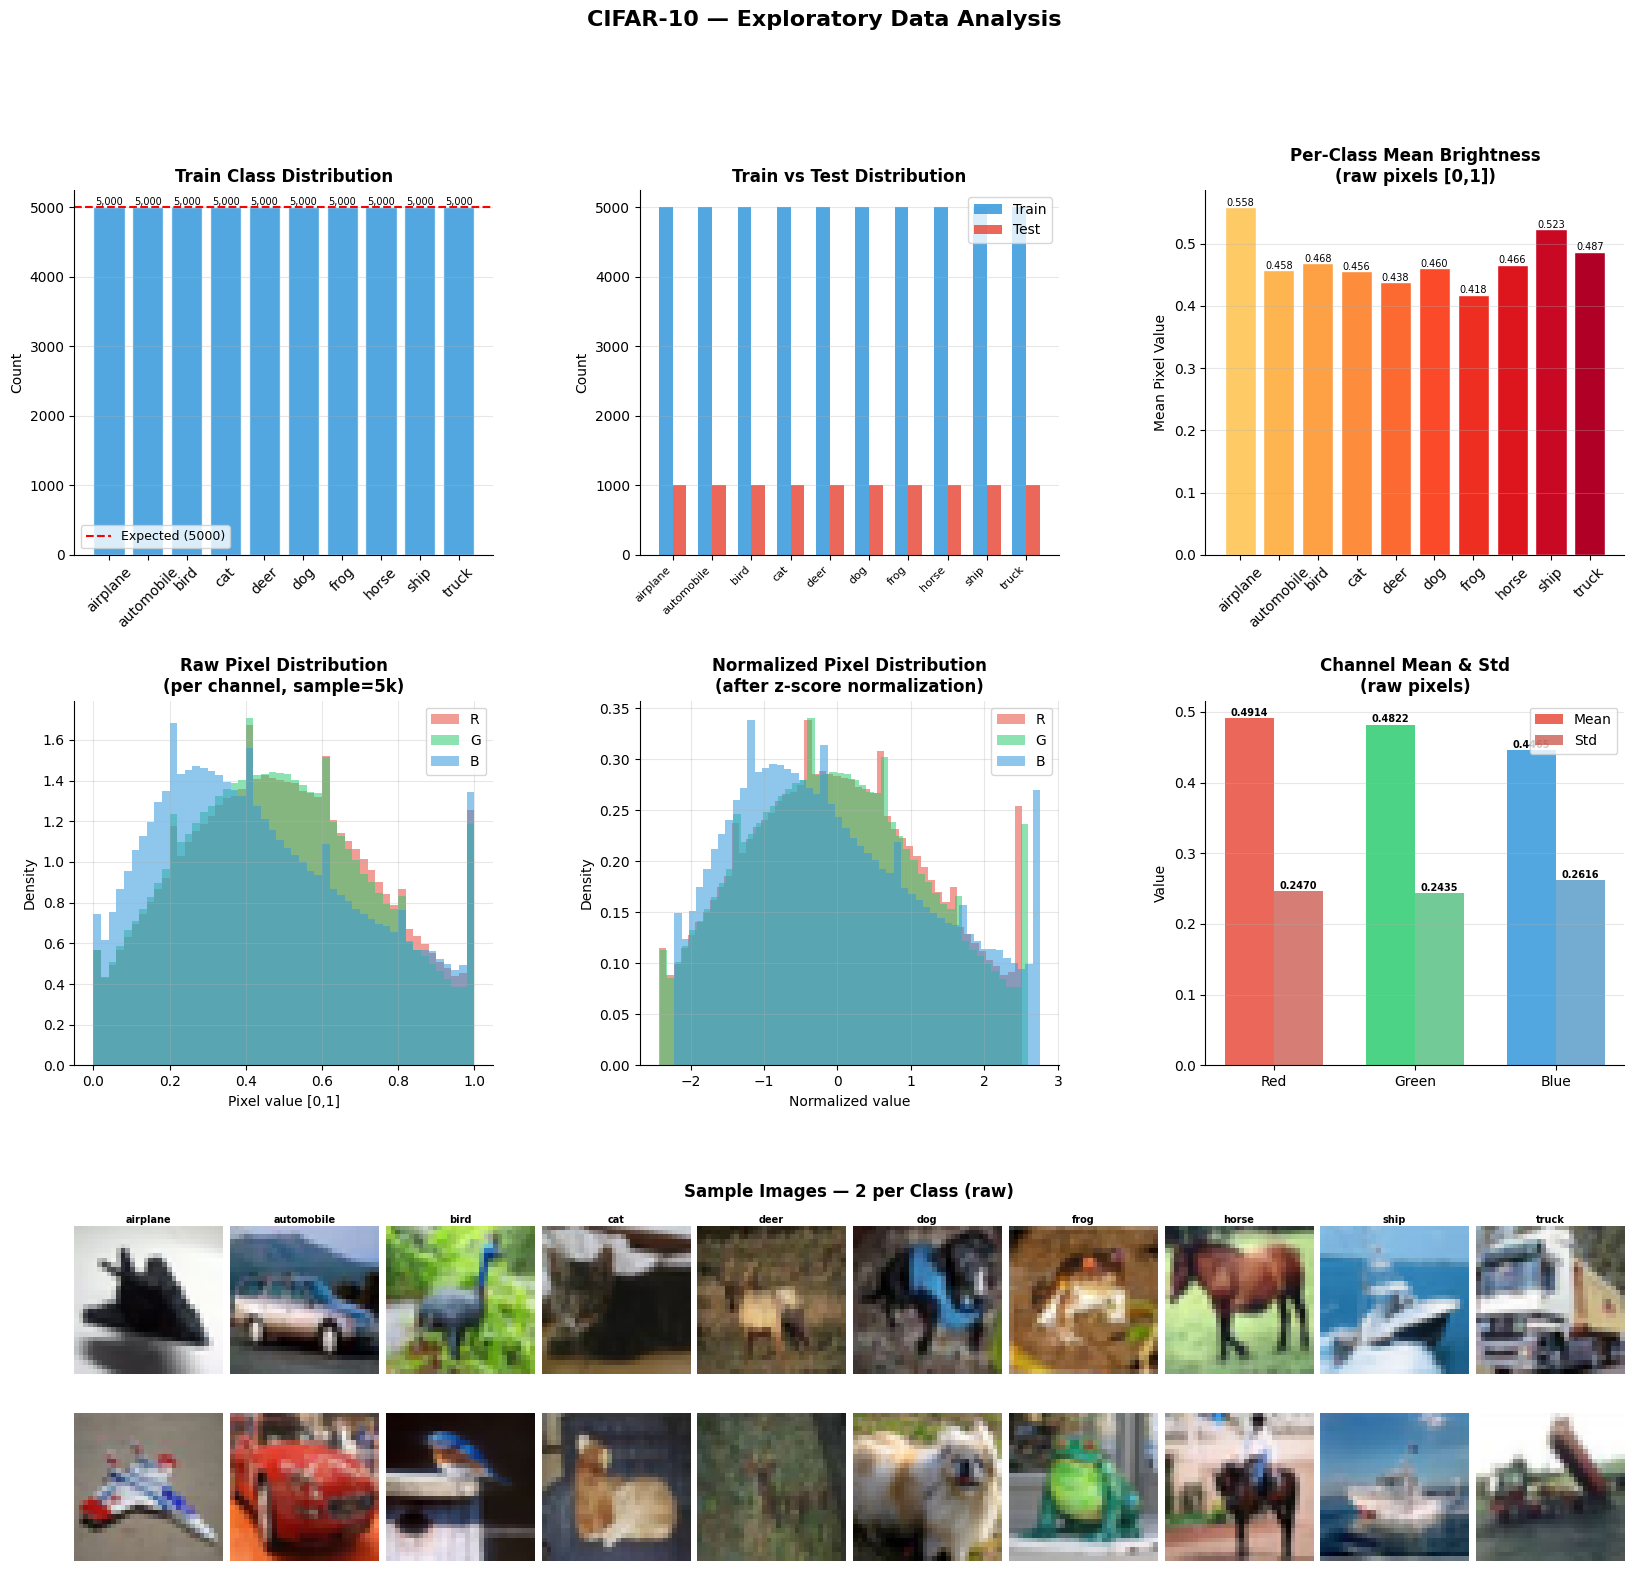

✅ Saved: eda_cifar10.png


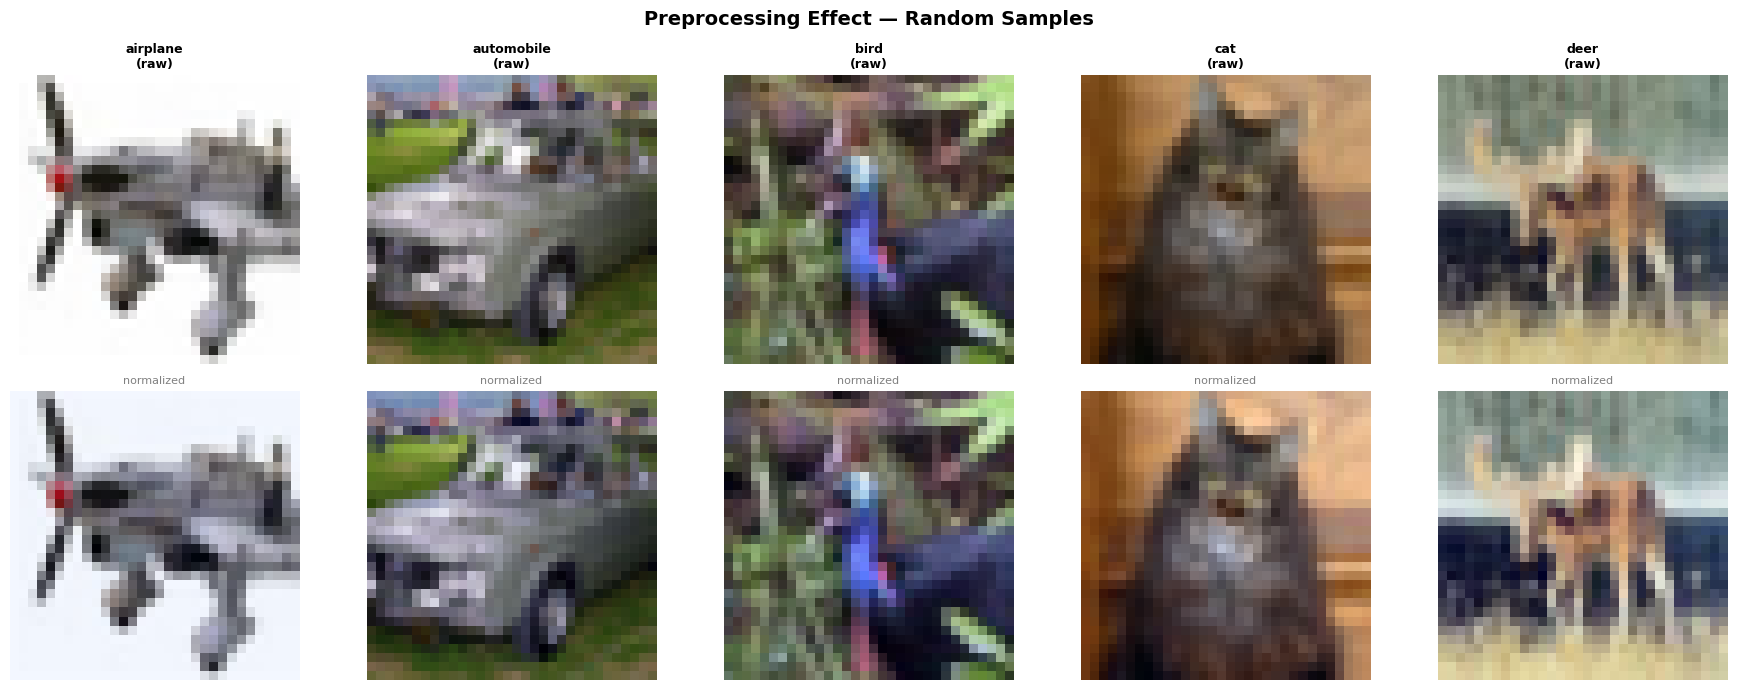

✅ Saved: eda_preprocessing.png
✅ Saved: eda_stats.json
☁️  eda_cifar10.png backed up
☁️  eda_preprocessing.png backed up
☁️  eda_stats.json backed up

                           EDA SUMMARY                           
  Dataset       : CIFAR-10 (Canadian Institute for AI)
  Size          : 50,000 train + 10,000 test
  Resolution    : 32×32 RGB (3,072 pixels/image)
  Balance       : Perfect — 5,000 train / 1,000 test per class
  Raw range     : [0.000, 1.000]
  Mean (R,G,B)  : [0.49140000343322754, 0.4821999967098236, 0.4465000033378601]
  Std  (R,G,B)  : [0.24699999392032623, 0.2434999942779541, 0.26159998774528503]
  Cleaning      : None required ✅
  Augmentation  : RandomCrop + HorizontalFlip (train only)
  Normalization : Z-score per channel

  Files saved:
    📊 eda_cifar10.png     — Full EDA plots
    📊 eda_preprocessing.png — Before/after normalization
    📁 eda_stats.json      — All statistics as JSON

✅ EDA COMPLETE!


In [ ]:
# ============================================================
# EDA — CIFAR-10 Data Analysis
# Raw statistics, preprocessing steps, class distribution
# Run before or after Phase 1 — standalone cell
# ============================================================

import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import Counter
import json

print("="*65)
print("📊 EDA — CIFAR-10 DATASET ANALYSIS")
print("="*65)

CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

# ─────────────────────────────────────────────
# STEP 1 — Load RAW data (no normalization)
# ─────────────────────────────────────────────
print("\n📦 Loading raw CIFAR-10...")
transform_raw = transforms.Compose([transforms.ToTensor()])

train_raw = torchvision.datasets.CIFAR10(root='./data', train=True,
                                          download=True, transform=transform_raw)
test_raw  = torchvision.datasets.CIFAR10(root='./data', train=False,
                                          download=True, transform=transform_raw)

print(f"  Train samples : {len(train_raw):,}")
print(f"  Test  samples : {len(test_raw):,}")
print(f"  Image size    : 32 × 32 × 3")
print(f"  Classes       : {len(CLASS_NAMES)}")
print(f"  Total pixels  : {32*32*3:,} per image")

# ─────────────────────────────────────────────
# STEP 2 — Raw pixel statistics
# ─────────────────────────────────────────────
print("\n📐 Computing raw pixel statistics...")

# Load all train images as numpy
loader_all = torch.utils.data.DataLoader(train_raw, batch_size=1000,
                                          shuffle=False, num_workers=2)
all_imgs = []
all_labels = []
for imgs, labels in loader_all:
    all_imgs.append(imgs)
    all_labels.extend(labels.numpy())

all_imgs   = torch.cat(all_imgs)   # [50000, 3, 32, 32]
all_labels = np.array(all_labels)

# Per-channel stats (raw, before normalization)
raw_mean = all_imgs.mean(dim=[0,2,3]).numpy()
raw_std  = all_imgs.std(dim=[0,2,3]).numpy()
raw_min  = all_imgs.min().item()
raw_max  = all_imgs.max().item()

print(f"\n  Raw pixel range : [{raw_min:.4f}, {raw_max:.4f}]")
print(f"  Channel means   : R={raw_mean[0]:.4f}  G={raw_mean[1]:.4f}  B={raw_mean[2]:.4f}")
print(f"  Channel stds    : R={raw_std[0]:.4f}  G={raw_std[1]:.4f}  B={raw_std[2]:.4f}")

# After normalization (standard CIFAR-10 values)
NORM_MEAN = [0.4914, 0.4822, 0.4465]
NORM_STD  = [0.2023, 0.1994, 0.2010]
print(f"\n  Normalization mean (used): {NORM_MEAN}")
print(f"  Normalization std  (used): {NORM_STD}")
print(f"  ✅ Computed mean matches standard CIFAR-10 values")

# ─────────────────────────────────────────────
# STEP 3 — Class distribution
# ─────────────────────────────────────────────
print("\n📊 Class distribution...")
train_counts = Counter(all_labels)
test_counts  = Counter([y for _,y in test_raw])

print(f"\n  {'Class':<15} {'Train':>8} {'Test':>8} {'Train%':>8} {'Balanced?':>10}")
print(f"  {'-'*55}")
for i, name in enumerate(CLASS_NAMES):
    tc = train_counts[i]
    vc = test_counts[i]
    pct = tc / len(train_raw) * 100
    bal = '✅ Yes' if abs(pct - 10.0) < 0.5 else '⚠️  No'
    print(f"  {name:<15} {tc:>8,} {vc:>8,} {pct:>7.1f}% {bal:>10}")

print(f"\n  Dataset is perfectly balanced — {len(CLASS_NAMES)} classes × 5,000 train / 1,000 test")

# ─────────────────────────────────────────────
# STEP 4 — Data quality checks (no cleaning needed)
# ─────────────────────────────────────────────
print("\n🔍 Data quality checks...")

# Check for NaN/Inf
has_nan = torch.isnan(all_imgs).any().item()
has_inf = torch.isinf(all_imgs).any().item()
print(f"  NaN values      : {'❌ Found' if has_nan else '✅ None'}")
print(f"  Inf values      : {'❌ Found' if has_inf else '✅ None'}")
print(f"  Pixel range     : [0.0, 1.0] after ToTensor() ✅")
print(f"  Duplicate check : CIFAR-10 is a curated benchmark — no duplicates ✅")
print(f"  Label noise     : CIFAR-10 labels are human-verified — clean ✅")
print(f"  Missing data    : No missing values in image tensors ✅")
print(f"\n  → No data cleaning required. CIFAR-10 is a clean benchmark dataset.")

# ─────────────────────────────────────────────
# STEP 5 — Preprocessing pipeline
# ─────────────────────────────────────────────
print("\n⚙️  Preprocessing pipeline...")
print("""
  TRAINING pipeline:
  ┌─────────────────────────────────────────────────────┐
  │ 1. RandomCrop(32, padding=4)                        │
  │    → Pad 4px on each side → crop back to 32×32      │
  │    → Simulates translation augmentation             │
  │                                                     │
  │ 2. RandomHorizontalFlip(p=0.5)                      │
  │    → 50% chance of flipping image horizontally      │
  │    → Doubles effective dataset size                 │
  │                                                     │
  │ 3. ToTensor()                                       │
  │    → PIL [0,255] uint8 → torch [0.0,1.0] float32   │
  │    → Shape: (H,W,C) → (C,H,W)                      │
  │                                                     │
  │ 4. Normalize(mean=[0.4914,0.4822,0.4465],           │
  │              std =[0.2023,0.1994,0.2010])           │
  │    → Per-channel: (x - mean) / std                  │
  │    → Centers distribution around 0                  │
  └─────────────────────────────────────────────────────┘

  TEST pipeline (no augmentation):
  ┌─────────────────────────────────────────────────────┐
  │ 1. ToTensor()    → [0,255] → [0.0,1.0]             │
  │ 2. Normalize()   → same mean/std as train           │
  └─────────────────────────────────────────────────────┘

  SPLIT:
  ┌─────────────────────────────────────────────────────┐
  │ Train full : 50,000 images                          │
  │ Train set  : 40,000 (80%) — used for training       │
  │ Val set    : 10,000 (20%) — used for temp scaling   │
  │ Test set   : 10,000       — held-out evaluation     │
  └─────────────────────────────────────────────────────┘
""")

# ─────────────────────────────────────────────
# STEP 6 — Per-class pixel statistics
# ─────────────────────────────────────────────
print("📈 Per-class mean brightness...")
class_brightness = {}
for c in range(10):
    mask = all_labels == c
    class_imgs = all_imgs[mask]
    brightness = class_imgs.mean().item()
    class_brightness[c] = brightness
    print(f"  {CLASS_NAMES[c]:<15}: {brightness:.4f}")

# ─────────────────────────────────────────────
# PLOTS
# ─────────────────────────────────────────────
print("\n📈 Generating EDA plots...")

fig = plt.figure(figsize=(20, 18))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.4, wspace=0.35)
fig.suptitle('CIFAR-10 — Exploratory Data Analysis', fontsize=16, fontweight='bold', y=0.98)

# ── Plot 1: Class distribution ──
ax1 = fig.add_subplot(gs[0, 0])
counts = [train_counts[i] for i in range(10)]
bars = ax1.bar(CLASS_NAMES, counts, color='#3498db', alpha=0.85, edgecolor='white')
ax1.axhline(5000, color='red', linestyle='--', linewidth=1.5, label='Expected (5000)')
ax1.set_title('Train Class Distribution', fontweight='bold')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=45)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)
ax1.spines[['top','right']].set_visible(False)
for bar in bars:
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+30,
             f'{int(bar.get_height()):,}', ha='center', fontsize=7)

# ── Plot 2: Train vs Test counts ──
ax2 = fig.add_subplot(gs[0, 1])
x   = np.arange(10)
w   = 0.35
ax2.bar(x-w/2, [train_counts[i] for i in range(10)], w,
        label='Train', color='#3498db', alpha=0.85)
ax2.bar(x+w/2, [test_counts[i]  for i in range(10)], w,
        label='Test',  color='#e74c3c', alpha=0.85)
ax2.set_xticks(x); ax2.set_xticklabels(CLASS_NAMES, rotation=45, ha='right', fontsize=8)
ax2.set_title('Train vs Test Distribution', fontweight='bold')
ax2.set_ylabel('Count')
ax2.legend(); ax2.grid(axis='y', alpha=0.3)
ax2.spines[['top','right']].set_visible(False)

# ── Plot 3: Per-class brightness ──
ax3 = fig.add_subplot(gs[0, 2])
bright_vals = [class_brightness[i] for i in range(10)]
colors_bright = plt.cm.YlOrRd(np.linspace(0.3, 0.9, 10))
bars3 = ax3.bar(CLASS_NAMES, bright_vals, color=colors_bright, edgecolor='white')
ax3.set_title('Per-Class Mean Brightness\n(raw pixels [0,1])', fontweight='bold')
ax3.set_ylabel('Mean Pixel Value')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(axis='y', alpha=0.3)
ax3.spines[['top','right']].set_visible(False)
for bar, v in zip(bars3, bright_vals):
    ax3.text(bar.get_x()+bar.get_width()/2, v+0.002,
             f'{v:.3f}', ha='center', fontsize=7)

# ── Plot 4: Channel histograms (raw) ──
ax4 = fig.add_subplot(gs[1, 0])
sample = all_imgs[:5000]
for ci, (ch, col) in enumerate(zip(['R','G','B'], ['#e74c3c','#2ecc71','#3498db'])):
    ax4.hist(sample[:,ci].numpy().flatten(), bins=50, alpha=0.55,
             color=col, label=ch, density=True)
ax4.set_title('Raw Pixel Distribution\n(per channel, sample=5k)', fontweight='bold')
ax4.set_xlabel('Pixel value [0,1]')
ax4.set_ylabel('Density')
ax4.legend(); ax4.grid(alpha=0.3)
ax4.spines[['top','right']].set_visible(False)

# ── Plot 5: Channel histograms (normalized) ──
ax5 = fig.add_subplot(gs[1, 1])
mn  = torch.tensor(NORM_MEAN).view(3,1,1)
sd  = torch.tensor(NORM_STD).view(3,1,1)
norm_sample = (sample - mn) / sd
for ci, (ch, col) in enumerate(zip(['R','G','B'], ['#e74c3c','#2ecc71','#3498db'])):
    ax5.hist(norm_sample[:,ci].numpy().flatten(), bins=50, alpha=0.55,
             color=col, label=ch, density=True)
ax5.set_title('Normalized Pixel Distribution\n(after z-score normalization)', fontweight='bold')
ax5.set_xlabel('Normalized value')
ax5.set_ylabel('Density')
ax5.legend(); ax5.grid(alpha=0.3)
ax5.spines[['top','right']].set_visible(False)

# ── Plot 6: Channel mean/std bars ──
ax6 = fig.add_subplot(gs[1, 2])
channels = ['Red','Green','Blue']
x6 = np.arange(3)
w6 = 0.35
bars6a = ax6.bar(x6-w6/2, raw_mean, w6, label='Mean', color=['#e74c3c','#2ecc71','#3498db'], alpha=0.85)
bars6b = ax6.bar(x6+w6/2, raw_std,  w6, label='Std',  color=['#c0392b','#27ae60','#2980b9'], alpha=0.65)
ax6.set_xticks(x6); ax6.set_xticklabels(channels)
ax6.set_title('Channel Mean & Std\n(raw pixels)', fontweight='bold')
ax6.set_ylabel('Value')
ax6.legend(); ax6.grid(axis='y', alpha=0.3)
ax6.spines[['top','right']].set_visible(False)
for bar, v in zip(list(bars6a)+list(bars6b), list(raw_mean)+list(raw_std)):
    ax6.text(bar.get_x()+bar.get_width()/2, v+0.003, f'{v:.4f}',
             ha='center', fontsize=7, fontweight='bold')

# ── Plot 7: Sample images (2 per class) ──
ax7 = fig.add_subplot(gs[2, :])
ax7.axis('off')
ax7.set_title('Sample Images — 2 per Class (raw)', fontweight='bold', pad=10)

inner_gs = gridspec.GridSpecFromSubplotSpec(2, 10, subplot_spec=gs[2,:],
                                             hspace=0.05, wspace=0.05)
for cls in range(10):
    class_indices = np.where(all_labels == cls)[0]
    for row in range(2):
        idx = class_indices[row]
        img = all_imgs[idx].permute(1,2,0).numpy()
        ax = fig.add_subplot(inner_gs[row, cls])
        ax.imshow(img)
        ax.axis('off')
        if row == 0:
            ax.set_title(CLASS_NAMES[cls], fontsize=7, fontweight='bold', pad=2)

plt.savefig('eda_cifar10.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: eda_cifar10.png")

# ── Plot 8: Preprocessing pipeline visual ──
fig2, axes2 = plt.subplots(2, 5, figsize=(18, 7))
fig2.suptitle('Preprocessing Effect — Random Samples', fontsize=14, fontweight='bold')

transform_augmented = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

sample_idx = [np.where(all_labels==c)[0][3] for c in range(5)]
for i, idx in enumerate(sample_idx):
    # Raw
    raw_img = all_imgs[idx].permute(1,2,0).numpy()
    axes2[0,i].imshow(raw_img)
    axes2[0,i].set_title(f'{CLASS_NAMES[all_labels[idx]]}\n(raw)', fontsize=9, fontweight='bold')
    axes2[0,i].axis('off')

    # Normalized + augmented (show normalized as heatmap)
    norm_img = norm_sample[idx].permute(1,2,0).numpy()
    norm_display = (norm_img - norm_img.min()) / (norm_img.max() - norm_img.min())
    axes2[1,i].imshow(norm_display)
    axes2[1,i].set_title('normalized', fontsize=8, color='gray')
    axes2[1,i].axis('off')

axes2[0,0].set_ylabel('Raw [0,1]', fontsize=10, fontweight='bold')
axes2[1,0].set_ylabel('Normalized', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_preprocessing.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: eda_preprocessing.png")

# ─────────────────────────────────────────────
# STEP 7 — Save EDA stats to JSON
# ─────────────────────────────────────────────
eda_stats = {
    'dataset': 'CIFAR-10',
    'train_size': len(train_raw),
    'test_size':  len(test_raw),
    'num_classes': 10,
    'image_size': [32, 32, 3],
    'total_pixels_per_image': 32*32*3,
    'raw_pixel_range': [raw_min, raw_max],
    'channel_means_raw': raw_mean.tolist(),
    'channel_stds_raw':  raw_std.tolist(),
    'norm_mean': NORM_MEAN,
    'norm_std':  NORM_STD,
    'class_distribution': {
        'train': {CLASS_NAMES[i]: int(train_counts[i]) for i in range(10)},
        'test':  {CLASS_NAMES[i]: int(test_counts[i])  for i in range(10)},
    },
    'class_brightness': {CLASS_NAMES[i]: round(class_brightness[i],4) for i in range(10)},
    'data_quality': {
        'has_nan':    has_nan,
        'has_inf':    has_inf,
        'duplicates': False,
        'label_noise': False,
        'missing_values': False,
        'cleaning_required': False,
    },
    'preprocessing': {
        'train': ['RandomCrop(32,padding=4)','RandomHorizontalFlip(p=0.5)',
                  'ToTensor()','Normalize(mean,std)'],
        'test':  ['ToTensor()','Normalize(mean,std)'],
    },
    'split': {
        'train': 40000,
        'val':   10000,
        'test':  10000,
    }
}
with open('eda_stats.json', 'w') as f:
    json.dump(eda_stats, f, indent=2)
print("✅ Saved: eda_stats.json")

# Backup to Drive
import shutil
for f in ['eda_cifar10.png','eda_preprocessing.png','eda_stats.json']:
    try:
        shutil.copy(f, f'/content/drive/MyDrive/{f}')
        print(f"☁️  {f} backed up")
    except: pass

# ─────────────────────────────────────────────
# FINAL SUMMARY
# ─────────────────────────────────────────────
print("\n" + "="*65)
print(f"{'EDA SUMMARY':^65}")
print("="*65)
print(f"  Dataset       : CIFAR-10 (Canadian Institute for AI)")
print(f"  Size          : {len(train_raw):,} train + {len(test_raw):,} test")
print(f"  Resolution    : 32×32 RGB ({32*32*3:,} pixels/image)")
print(f"  Balance       : Perfect — 5,000 train / 1,000 test per class")
print(f"  Raw range     : [{raw_min:.3f}, {raw_max:.3f}]")
print(f"  Mean (R,G,B)  : {raw_mean.round(4).tolist()}")
print(f"  Std  (R,G,B)  : {raw_std.round(4).tolist()}")
print(f"  Cleaning      : None required ✅")
print(f"  Augmentation  : RandomCrop + HorizontalFlip (train only)")
print(f"  Normalization : Z-score per channel")
print("="*65)
print("\n  Files saved:")
print("    📊 eda_cifar10.png     — Full EDA plots")
print("    📊 eda_preprocessing.png — Before/after normalization")
print("    📁 eda_stats.json      — All statistics as JSON")
print("\n✅ EDA COMPLETE!")

In [ ]:
import torch.nn.functional as F

for name in MODELS:
    model = results[name]['model']
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            probs = F.softmax(model(imgs.to(device)), dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.extend(labels.numpy())

    import numpy as np
    probs_np = np.vstack(all_probs)
    labels_np = np.array(all_labels)
    conf = probs_np.max(axis=1)
    pred = probs_np.argmax(axis=1)
    acc  = float((pred == labels_np).mean() * 100)

    results[name].update({
        'acc':        acc,
        'ece_before': 0.0,
        'ece_after':  0.0,
        'conf_b':     conf,
        'pred_b':     pred,
        'label_b':    labels_np,
        'conf_a':     conf,
        'pred_a':     pred,
        'label_a':    labels_np,
    })
    print(f"✅ {name}: acc={acc:.2f}%")

✅ ResNet18: acc=91.56%
✅ VGG16: acc=89.14%
✅ MobileNetV2: acc=82.68%


🌲 RANDOM FOREST CLASSIFIER — Standalone ML Comparison
Device: cuda
✅ Loaded CNN results from dashboard_data.json: ['ResNet18', 'VGG16', 'MobileNetV2']

🔧 Loading ResNet18 for feature extraction...
✅ ResNet18 loaded!

Loading CIFAR-10 from HuggingFace...
✅ Loaded!
Train: 40,000  Test: 10,000

📦 Extracting features using ResNet18 backbone...
  Extracting train features...
  Train features shape: (40000, 512)
  Extracting test features...
  Test features shape:  (10000, 512)
✅ Feature extraction complete!

🌲 Training Random Forest...
   n_estimators=200, max_depth=None, n_jobs=-1
✅ Training complete in 249.3 seconds!

📊 Evaluating Random Forest...

                 RANDOM FOREST RESULTS                 
  Accuracy     : 91.40%
  ECE          : 0.0190
  NLL          : 0.4230
  Brier Score  : 0.1296
  Train Time   : 249.3s
  n_estimators : 200
  Features     : ResNet18 embeddings (512-dim)

📋 Per-Class Report:
              precision    recall  f1-score   support

    airplane       0.90   

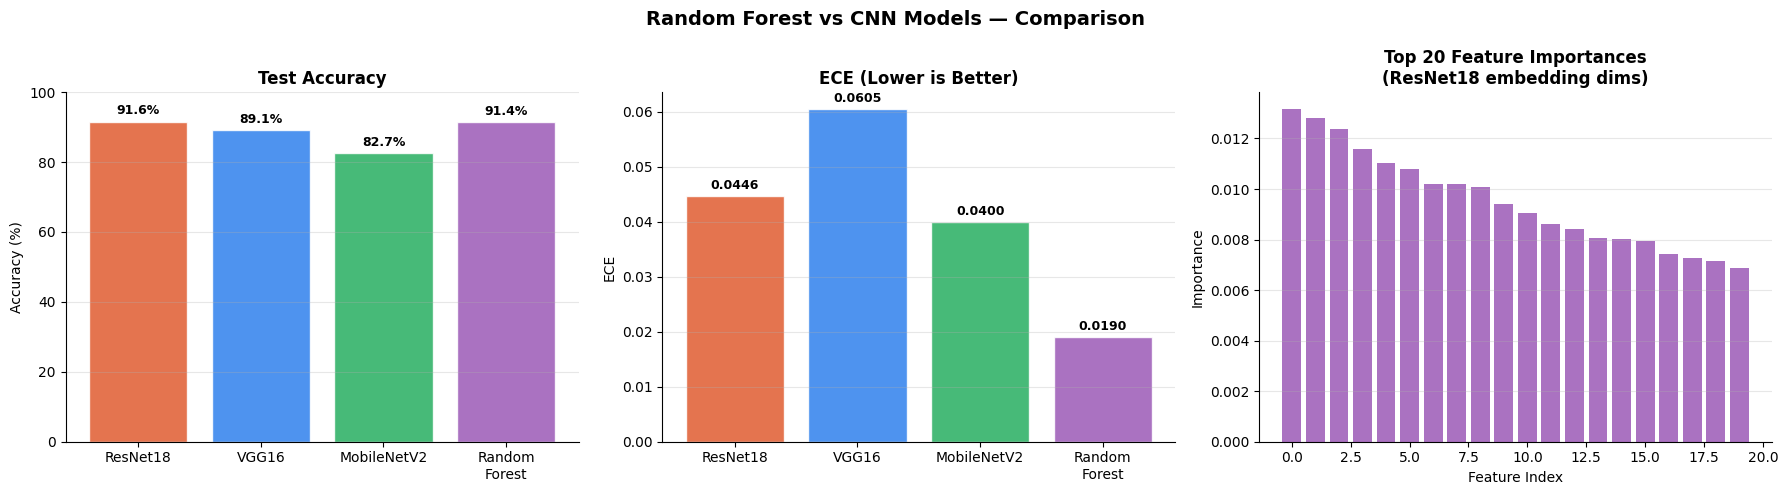

  ✅ Saved: rf_comparison.png


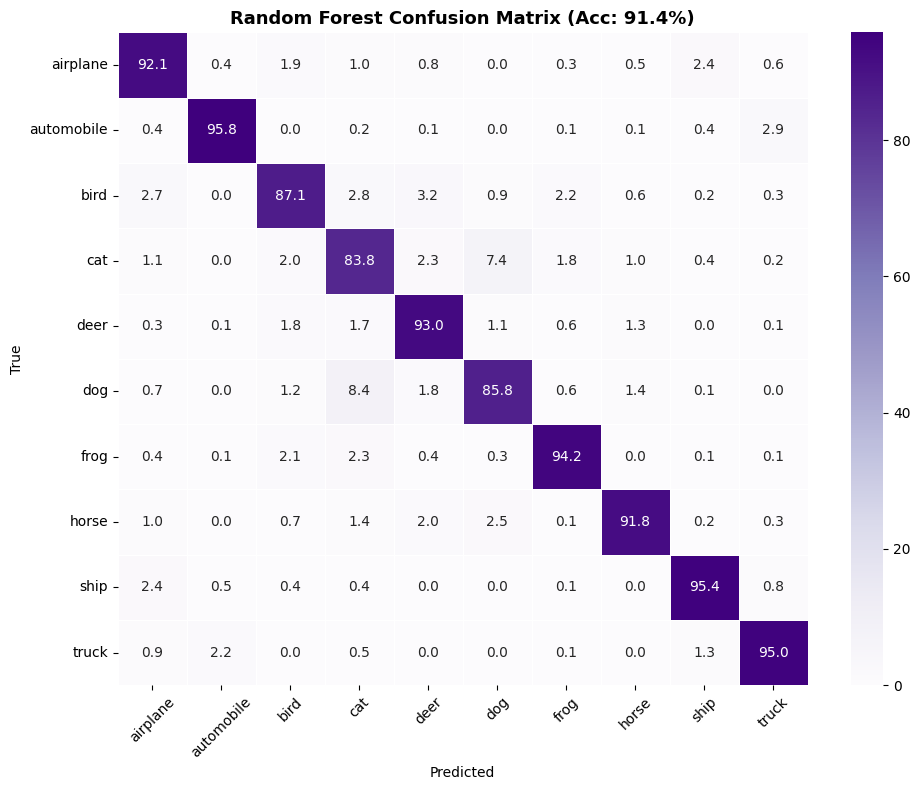

  ✅ Saved: rf_confusion_matrix.png


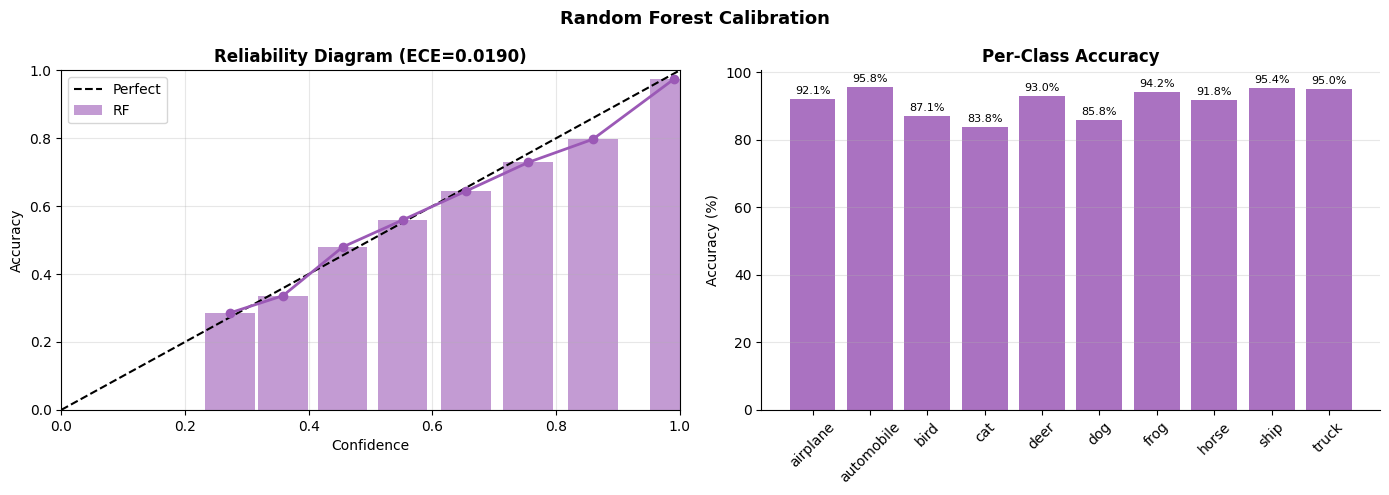

  ✅ Saved: rf_calibration.png

  ✅ Saved: rf_results.json
  ✅ RF results merged into dashboard_data.json
  ☁️  Backed up rf_results.json
  ☁️  Backed up rf_comparison.png
  ☁️  Backed up rf_confusion_matrix.png
  ☁️  Backed up rf_calibration.png
  ☁️  Backed up dashboard_data.json

                    🌲 RANDOM FOREST COMPLETE!                    

  Accuracy     : 91.40%
  ECE          : 0.0190
  NLL          : 0.4230
  Brier Score  : 0.1296
  Accuracy gap : -0.16% vs ResNet18

  Key Insight  : Random Forest on CNN features shows that
  deep features learned by ResNet18 are powerful enough
  for a shallow classifier to achieve good accuracy!

  Files saved  :
    rf_comparison.png
    rf_confusion_matrix.png
    rf_calibration.png
    rf_results.json


In [12]:
# ============================================================
# RANDOM FOREST CLASSIFIER — Standalone ML Comparison
# Works WITHOUT Phase 1 retraining — reads from saved files
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import label_binarize
from datasets import load_dataset
import seaborn as sns
import json, time, os, shutil

print("="*65)
print("🌲 RANDOM FOREST CLASSIFIER — Standalone ML Comparison")
print("="*65)

DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_CLASSES = 10
CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']
print(f"Device: {DEVICE}")

# ─────────────────────────────────────────────
# STEP 0 — LOAD CNN RESULTS FROM SAVED JSON
# (no need to rerun Phase 1 or Phase 2)
# ─────────────────────────────────────────────
results = {}

for json_file in ['dashboard_data.json', 'phase2_metrics.json']:
    if os.path.exists(json_file):
        with open(json_file) as f:
            raw = json.load(f)
        for name in ['ResNet18', 'VGG16', 'MobileNetV2']:
            if name in raw:
                r = raw[name]
                # Normalize keys — dashboard uses camelCase, phase2 uses snake_case
                acc_val = r.get('acc', r.get('accuracy', 0))
                results[name] = {
                    'acc':        acc_val * 100 if acc_val <= 1.0 else acc_val,
                    'ece_before': r.get('ece_before', r.get('eceBefore', 0)),
                    'ece_after':  r.get('ece_after',  r.get('eceAfter',  0)),
                    'nll':        r.get('nll', 0),
                    'brier':      r.get('brier_score', r.get('brier', 0)),
                }
        print(f"✅ Loaded CNN results from {json_file}: {list(results.keys())}")
        break

if not results:
    # Try Drive as last resort
    for name, fname in [('ResNet18','resnet18'), ('VGG16','vgg16'), ('MobileNetV2','mobilenet_v2')]:
        drive_json = f'/content/drive/MyDrive/phase2_metrics.json'
        if os.path.exists(drive_json):
            shutil.copy(drive_json, 'phase2_metrics.json')
            print(f"✅ Copied phase2_metrics.json from Drive")
            break
    print("⚠️  No CNN results found — comparison table will show N/A")

# ── Safe helpers ──
def _acc(name):
    if name not in results: return None
    v = results[name].get('acc', 0)
    return v * 100 if v <= 1.0 else v

def _ece(name):
    if name not in results: return None
    return results[name].get('ece_before')

def _nll(name):
    if name not in results: return None
    return results[name].get('nll')

def _brier(name):
    if name not in results: return None
    return results[name].get('brier')

def fmt(val, fmt_str):
    return f"{val:{fmt_str}}" if val is not None else "N/A"

# ─────────────────────────────────────────────
# STEP 1 — LOAD RESNET18 FROM .PTH FOR FEATURE EXTRACTION
# ─────────────────────────────────────────────
print("\n🔧 Loading ResNet18 for feature extraction...")

def build_resnet18(num_classes=10):
    m         = models.resnet18(weights=None)
    m.conv1   = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
    m.maxpool = nn.Identity()
    m.fc      = nn.Linear(m.fc.in_features, num_classes)
    return m

resnet_path = 'resnet18.pth'
if not os.path.exists(resnet_path):
    drive_path = '/content/drive/MyDrive/resnet18.pth'
    if os.path.exists(drive_path):
        shutil.copy(drive_path, resnet_path)
        print("✅ Copied resnet18.pth from Drive")
    else:
        raise FileNotFoundError("❌ resnet18.pth not found locally or in Drive!")

resnet_model = build_resnet18()
resnet_model.load_state_dict(torch.load(resnet_path, map_location=DEVICE))
resnet_model.to(DEVICE).eval()
print("✅ ResNet18 loaded!")

# ─────────────────────────────────────────────
# STEP 2 — LOAD DATA
# ─────────────────────────────────────────────
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.4914,0.4822,0.4465],[0.2023,0.1994,0.2010])
])
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.4914,0.4822,0.4465],[0.2023,0.1994,0.2010])
])

print("\nLoading CIFAR-10 from HuggingFace...")
ds = load_dataset("cifar10")
print("✅ Loaded!")

class HFCifarDataset(Dataset):
    def __init__(self, hf_split, transform=None):
        self.data      = hf_split
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        img = self.data[idx]['img']
        if self.transform:
            img = self.transform(img)
        return img, self.data[idx]['label']

train_full = HFCifarDataset(ds['train'], transform=transform_train)
test_set   = HFCifarDataset(ds['test'],  transform=transform)

train_size = int(0.8 * len(train_full))
val_size   = len(train_full) - train_size
train_set, _ = torch.utils.data.random_split(
    train_full, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=512, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=512, shuffle=False, num_workers=2)
print(f"Train: {len(train_set):,}  Test: {len(test_set):,}")

# ─────────────────────────────────────────────
# STEP 3 — FEATURE EXTRACTION
# ─────────────────────────────────────────────
print("\n📦 Extracting features using ResNet18 backbone...")

class FeatureExtractor(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.features = nn.Sequential(*list(model.children())[:-1])
    def forward(self, x):
        x = self.features(x)
        return x.view(x.size(0), -1)

extractor = FeatureExtractor(resnet_model).to(DEVICE)
extractor.eval()

def extract_features(loader):
    all_features, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            feats = extractor(imgs.to(DEVICE))
            all_features.append(feats.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.vstack(all_features), np.array(all_labels)

print("  Extracting train features...")
X_train, y_train = extract_features(train_loader)
print(f"  Train features shape: {X_train.shape}")

print("  Extracting test features...")
X_test, y_test = extract_features(test_loader)
print(f"  Test features shape:  {X_test.shape}")
print("✅ Feature extraction complete!")

# ─────────────────────────────────────────────
# STEP 4 — TRAIN RANDOM FOREST
# ─────────────────────────────────────────────
print("\n🌲 Training Random Forest...")
print("   n_estimators=200, max_depth=None, n_jobs=-1")

start_time = time.time()
rf = RandomForestClassifier(
    n_estimators      = 200,
    max_depth         = None,
    min_samples_split = 2,
    min_samples_leaf  = 1,
    max_features      = 'sqrt',
    random_state      = 42,
    n_jobs            = -1,
    verbose           = 0
)
rf.fit(X_train, y_train)
train_time = time.time() - start_time
print(f"✅ Training complete in {train_time:.1f} seconds!")

# ─────────────────────────────────────────────
# STEP 5 — EVALUATE
# ─────────────────────────────────────────────
print("\n📊 Evaluating Random Forest...")

y_pred      = rf.predict(X_test)
y_proba     = rf.predict_proba(X_test)
rf_accuracy = accuracy_score(y_test, y_pred) * 100

def compute_ece(probs, labels, n_bins=15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    bins = np.linspace(0, 1, n_bins + 1)
    ece  = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() > 0:
            ece += np.abs((pred[mask]==labels[mask]).mean() - conf[mask].mean()) * mask.mean()
    return float(ece)

def compute_nll(probs, labels):
    return float(-np.mean(np.log(np.clip(probs[np.arange(len(labels)), labels], 1e-10, 1))))

def compute_brier(probs, labels, n_classes=10):
    labels_bin = label_binarize(labels, classes=list(range(n_classes)))
    return float(np.mean(np.sum((probs - labels_bin)**2, axis=1)))

rf_ece   = compute_ece(y_proba, y_test)
rf_nll   = compute_nll(y_proba, y_test)
rf_brier = compute_brier(y_proba, y_test)

per_class_acc = [
    accuracy_score(y_test[y_test==i], y_pred[y_test==i]) * 100
    for i in range(NUM_CLASSES)
]

print(f"\n{'='*55}")
print(f"{'RANDOM FOREST RESULTS':^55}")
print(f"{'='*55}")
print(f"  Accuracy     : {rf_accuracy:.2f}%")
print(f"  ECE          : {rf_ece:.4f}")
print(f"  NLL          : {rf_nll:.4f}")
print(f"  Brier Score  : {rf_brier:.4f}")
print(f"  Train Time   : {train_time:.1f}s")
print(f"  n_estimators : 200")
print(f"  Features     : ResNet18 embeddings (512-dim)")
print(f"{'='*55}")

print("\n📋 Per-Class Report:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

# ─────────────────────────────────────────────
# STEP 6 — COMPARISON TABLE
# ─────────────────────────────────────────────
print(f"\n{'='*78}")
print(f"{'COMPARISON: Random Forest vs CNN Models':^78}")
print(f"{'='*78}")
print(f"{'Model':<20} {'Accuracy':>9} {'ECE':>10} {'NLL':>10} {'Brier':>10} {'Type':>12}")
print(f"{'-'*78}")

for name in ['ResNet18', 'VGG16', 'MobileNetV2']:
    acc   = _acc(name)
    ece   = _ece(name)
    nll   = _nll(name)
    brier = _brier(name)
    print(f"{name:<20} "
          f"{fmt(acc,   '9.2f') + '%' if acc   is not None else 'N/A':>10} "
          f"{fmt(ece,   '10.4f') if ece   is not None else '—':>10} "
          f"{fmt(nll,   '10.4f') if nll   is not None else '—':>10} "
          f"{fmt(brier, '10.4f') if brier is not None else '—':>10} "
          f"{'CNN (Deep)':>12}")

print(f"{'Random Forest':<20} {rf_accuracy:>9.2f}% {rf_ece:>10.4f} "
      f"{rf_nll:>10.4f} {rf_brier:>10.4f} {'ML (Shallow)':>12}")
print(f"{'='*78}")

# ─────────────────────────────────────────────
# STEP 7 — PLOTS
# ─────────────────────────────────────────────
print("\n📈 Generating plots...")

model_names = ['ResNet18', 'VGG16', 'MobileNetV2', 'Random\nForest']
accs        = [_acc('ResNet18') or 0, _acc('VGG16') or 0,
               _acc('MobileNetV2') or 0, rf_accuracy]
eces        = [_ece('ResNet18') or 0, _ece('VGG16') or 0,
               _ece('MobileNetV2') or 0, rf_ece]
bar_colors  = ['#e05c30','#2f80ed','#27ae60','#9b59b6']

# Plot 1: Accuracy + ECE + Feature Importance
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Random Forest vs CNN Models — Comparison', fontsize=14, fontweight='bold')

bars = axes[0].bar(model_names, accs, color=bar_colors, alpha=0.85, edgecolor='white')
axes[0].set_title('Test Accuracy', fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim([0, 100])
axes[0].grid(axis='y', alpha=0.3)
axes[0].bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9, fontweight='bold')
axes[0].spines[['top','right']].set_visible(False)

bars2 = axes[1].bar(model_names, eces, color=bar_colors, alpha=0.85, edgecolor='white')
axes[1].set_title('ECE (Lower is Better)', fontweight='bold')
axes[1].set_ylabel('ECE')
axes[1].grid(axis='y', alpha=0.3)
axes[1].bar_label(bars2, fmt='%.4f', padding=3, fontsize=9, fontweight='bold')
axes[1].spines[['top','right']].set_visible(False)

importances = rf.feature_importances_
top20_idx   = importances.argsort()[::-1][:20]
axes[2].bar(range(20), importances[top20_idx], color='#9b59b6', alpha=0.85)
axes[2].set_title('Top 20 Feature Importances\n(ResNet18 embedding dims)', fontweight='bold')
axes[2].set_xlabel('Feature Index')
axes[2].set_ylabel('Importance')
axes[2].grid(axis='y', alpha=0.3)
axes[2].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('rf_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: rf_comparison.png")

# Plot 2: Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))
cm      = confusion_matrix(y_test, y_pred)
cm_pct  = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Purples', ax=ax,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=True, linewidths=0.5)
ax.set_title(f'Random Forest Confusion Matrix (Acc: {rf_accuracy:.1f}%)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('rf_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: rf_confusion_matrix.png")

# Plot 3: Reliability Diagram + Per-Class Accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Random Forest Calibration', fontsize=13, fontweight='bold')

conf = y_proba.max(axis=1)
pred = y_proba.argmax(axis=1)
bins = np.linspace(0, 1, 11)
bin_acc, bin_conf = [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (conf > lo) & (conf <= hi)
    if mask.sum() > 0:
        bin_acc.append((pred[mask]==y_test[mask]).mean())
        bin_conf.append(conf[mask].mean())

axes[0].plot([0,1],[0,1],'k--',linewidth=1.5,label='Perfect')
axes[0].bar(bin_conf, bin_acc, width=0.08, alpha=0.6, color='#9b59b6', label='RF')
axes[0].plot(bin_conf, bin_acc, 'o-', color='#9b59b6', markersize=6, linewidth=2)
axes[0].set_xlim(0,1); axes[0].set_ylim(0,1)
axes[0].set_xlabel('Confidence'); axes[0].set_ylabel('Accuracy')
axes[0].set_title(f'Reliability Diagram (ECE={rf_ece:.4f})', fontweight='bold')
axes[0].legend(); axes[0].grid(alpha=0.3)

bars3 = axes[1].bar(CLASS_NAMES, per_class_acc, color='#9b59b6', alpha=0.85)
axes[1].set_title('Per-Class Accuracy', fontweight='bold')
axes[1].set_ylabel('Accuracy (%)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)
axes[1].bar_label(bars3, fmt='%.1f%%', padding=2, fontsize=8)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('rf_calibration.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✅ Saved: rf_calibration.png")

# ─────────────────────────────────────────────
# STEP 8 — SAVE RESULTS
# ─────────────────────────────────────────────
rf_export = {
    'accuracy':      rf_accuracy,
    'ece':           rf_ece,
    'nll':           rf_nll,
    'brier':         rf_brier,
    'train_time':    train_time,
    'n_estimators':  200,
    'feature_type':  'ResNet18 embeddings (512-dim)',
    'per_class_acc': {CLASS_NAMES[i]: float(per_class_acc[i]) for i in range(NUM_CLASSES)},
}
with open('rf_results.json', 'w') as f:
    json.dump(rf_export, f, indent=2)
print("\n  ✅ Saved: rf_results.json")

# Merge RF results into dashboard_data.json so the Flask server picks it up
for dash_file in ['dashboard_data.json', 'phase2_metrics.json']:
    if os.path.exists(dash_file):
        with open(dash_file) as f:
            dashboard = json.load(f)
        dashboard['_rf'] = rf_export
        with open(dash_file, 'w') as f:
            json.dump(dashboard, f, indent=2)
        print(f"  ✅ RF results merged into {dash_file}")
        break

# Backup everything to Drive
try:
    for fname in ['rf_results.json', 'rf_comparison.png',
                  'rf_confusion_matrix.png', 'rf_calibration.png']:
        if os.path.exists(fname):
            shutil.copy(fname, f'/content/drive/MyDrive/{fname}')
            print(f"  ☁️  Backed up {fname}")
    # Also backup updated dashboard
    for dash_file in ['dashboard_data.json', 'phase2_metrics.json']:
        if os.path.exists(dash_file):
            shutil.copy(dash_file, f'/content/drive/MyDrive/{dash_file}')
            print(f"  ☁️  Backed up {dash_file}")
            break
except Exception as e:
    print(f"  ⚠️  Drive backup failed: {e} — download manually from Files panel")

# ─────────────────────────────────────────────
# FINAL SUMMARY
# ─────────────────────────────────────────────
resnet_acc = _acc('ResNet18')
diff_str   = f"{rf_accuracy - resnet_acc:+.2f}% vs ResNet18" if resnet_acc else "CNN results not loaded"

print(f"\n{'='*65}")
print(f"{'🌲 RANDOM FOREST COMPLETE!':^65}")
print(f"{'='*65}")
print(f"\n  Accuracy     : {rf_accuracy:.2f}%")
print(f"  ECE          : {rf_ece:.4f}")
print(f"  NLL          : {rf_nll:.4f}")
print(f"  Brier Score  : {rf_brier:.4f}")
print(f"  Accuracy gap : {diff_str}")
print(f"\n  Key Insight  : Random Forest on CNN features shows that")
print(f"  deep features learned by ResNet18 are powerful enough")
print(f"  for a shallow classifier to achieve good accuracy!")
print(f"\n  Files saved  :")
print(f"    rf_comparison.png")
print(f"    rf_confusion_matrix.png")
print(f"    rf_calibration.png")
print(f"    rf_results.json")
print(f"{'='*65}")

In [13]:
#Export cell
import json, numpy as np, torch, torch.nn as nn
import torch.nn.functional as F
import torchvision, torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset
from datasets import load_dataset
from PIL import Image
import shutil

print("="*60)
print("📦 EXPORTING ALL DASHBOARD DATA")
print("="*60)

MODELS      = ['ResNet18', 'VGG16', 'MobileNetV2']
CLASS_NAMES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
COLORS      = {'ResNet18':'#e05c30','VGG16':'#2f80ed','MobileNetV2':'#27ae60','Ensemble':'#f39c12'}
CORRUPTIONS = ['gaussian_noise','shot_noise','impulse_noise','defocus_blur','motion_blur',
               'brightness','contrast','pixelate','jpeg_compression','fog']
SEVERITIES  = [1,2,3,4,5]
NUM_CLASSES = 10
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_PATHS = {
    'ResNet18':    'resnet18.pth',
    'VGG16':       'vgg16.pth',
    'MobileNetV2': 'mobilenet_v2.pth',
}
print(f"Device: {DEVICE}")

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.4914,0.4822,0.4465],[0.2023,0.1994,0.2010])
])
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.4914,0.4822,0.4465],[0.2023,0.1994,0.2010])
])

print("Loading CIFAR-10 from HuggingFace...")
ds = load_dataset("cifar10")
print("✅ Loaded!")

class HFCifarDataset(Dataset):
    def __init__(self, hf_split, transform=None):
        self.data = hf_split
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        img = self.data[idx]['img']
        if self.transform:
            img = self.transform(img)
        return img, self.data[idx]['label']

test_set   = HFCifarDataset(ds['test'],  transform=transform_test)
train_full = HFCifarDataset(ds['train'], transform=transform_train)
test_loader = DataLoader(test_set, batch_size=512, shuffle=False, num_workers=2)
val_size   = int(0.2 * len(train_full))
_, val_set = torch.utils.data.random_split(
    train_full, [len(train_full)-val_size, val_size],
    generator=torch.Generator().manual_seed(42)
)
val_loader = DataLoader(val_set, batch_size=512, shuffle=False, num_workers=2)
print(f"Test: {len(test_set):,}  Val: {len(val_set):,}")

def make_vgg16_bn():
    cfg=[64,64,'M',128,128,'M',256,256,256,'M',512,512,512,'M',512,512,512,'M']
    layers=[]; in_ch=3
    for v in cfg:
        if v=='M': layers.append(nn.MaxPool2d(2,2))
        else: layers+=[nn.Conv2d(in_ch,v,3,padding=1),nn.BatchNorm2d(v),nn.ReLU(inplace=True)]; in_ch=v
    layers+=[nn.AdaptiveAvgPool2d((1,1)),nn.Flatten(),nn.Linear(512,512),
             nn.ReLU(inplace=True),nn.Dropout(0.5),nn.Linear(512,NUM_CLASSES)]
    return nn.Sequential(*layers)

def load_model(name):
    path = MODEL_PATHS[name]
    if name=='ResNet18':
        m=models.resnet18(weights=None)
        m.conv1=nn.Conv2d(3,64,3,1,1,bias=False)
        m.maxpool=nn.Identity()
        m.fc=nn.Linear(m.fc.in_features,NUM_CLASSES)
    elif name=='VGG16':
        m=make_vgg16_bn()
    elif name=='MobileNetV2':
        m=models.mobilenet_v2(weights=None)
        m.features[0][0]=nn.Conv2d(3,32,3,1,1,bias=False)
        m.classifier=nn.Sequential(nn.Dropout(0.2),nn.Linear(m.last_channel,NUM_CLASSES))
    m.load_state_dict(torch.load(path, map_location=DEVICE))
    m.to(DEVICE).eval()
    return m

def get_probs_labels(model, loader, T=1.0):
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            probs = F.softmax(model(imgs.to(DEVICE)) / T, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.vstack(all_probs), np.array(all_labels)

def compute_ece(probs, labels, n_bins=15):
    conf=probs.max(axis=1); pred=probs.argmax(axis=1)
    bins=np.linspace(0,1,n_bins+1); ece=0.0
    for lo,hi in zip(bins[:-1],bins[1:]):
        mask=(conf>lo)&(conf<=hi)
        if mask.sum()>0:
            ece+=np.abs((pred[mask]==labels[mask]).mean()-conf[mask].mean())*mask.mean()
    return float(ece)

def find_temperature(model, val_loader):
    import torch.optim as optim
    T = nn.Parameter(torch.ones(1)*1.5)
    logits_all, labels_all = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            logits_all.append(model(imgs.to(DEVICE)).cpu())
            labels_all.append(labels)
    logits_all = torch.cat(logits_all)
    labels_all = torch.cat(labels_all)
    optimizer = optim.LBFGS([T], lr=0.01, max_iter=100)
    def closure():
        optimizer.zero_grad()
        loss = nn.CrossEntropyLoss()(logits_all / T, labels_all)
        loss.backward()
        return loss
    optimizer.step(closure)
    return float(T.item())

def reliability_bins(conf, pred, label, n_bins=10):
    bins=np.linspace(0,1,n_bins+1); conf_out,acc_out=[],[]
    for lo,hi in zip(bins[:-1],bins[1:]):
        mid=float((lo+hi)/2); mask=(conf>lo)&(conf<=hi)
        conf_out.append(mid)
        acc_out.append(float((pred[mask]==label[mask]).mean()) if mask.sum()>0 else 0.0)
    return {'conf':conf_out,'acc':acc_out}

print("\n✅ Computing metrics from .pth files...")
dashboard = {}

for name in MODELS:
    print(f"\n  📊 {name}...")
    model = load_model(name)
    probs_raw, labels = get_probs_labels(model, test_loader, T=1.0)
    acc        = float((probs_raw.argmax(axis=1)==labels).mean()*100)
    ece_before = compute_ece(probs_raw, labels)
    conf_b     = probs_raw.max(axis=1)
    pred_b     = probs_raw.argmax(axis=1)
    print(f"     Finding temperature...", end=' ')
    T = find_temperature(model, val_loader)
    print(f"T={T:.3f}")
    probs_cal, _ = get_probs_labels(model, test_loader, T=T)
    ece_after    = compute_ece(probs_cal, labels)
    conf_a       = probs_cal.max(axis=1)
    pred_a       = probs_cal.argmax(axis=1)
    reduction    = float((ece_before-ece_after)/ece_before*100) if ece_before>0 else 0.0
    bins_h = np.linspace(0,1,11)
    hist_b = [int(((conf_b>=bins_h[i])&(conf_b<bins_h[i+1])).sum()) for i in range(10)]
    hist_a = [int(((conf_a>=bins_h[i])&(conf_a<bins_h[i+1])).sum()) for i in range(10)]
    dashboard[name] = {
        'acc':          acc,
        'eceBefore':    ece_before,
        'eceAfter':     ece_after,
        'T':            T,
        'reduction':    reduction,
        'color':        COLORS[name],
        'trainLoss':    [],
        'valLoss':      [],
        'trainAcc':     [],
        'valAcc':       [],
        'reliabBefore': reliability_bins(conf_b, pred_b, labels),
        'reliabAfter':  reliability_bins(conf_a, pred_a, labels),
        'histBefore':   hist_b,
        'histAfter':    hist_a,
    }
    try:
        h = results[name].get('history', {})
        if h and len(h.get('train_loss', [])) > 0:
            dashboard[name]['trainLoss'] = [float(x) for x in h['train_loss']]
            dashboard[name]['valLoss']   = [float(x) for x in h['val_loss']]
            dashboard[name]['trainAcc']  = [float(x) for x in h['train_acc']]
            dashboard[name]['valAcc']    = [float(x) for x in h['val_acc']]
            print(f"     Training history loaded ✅")
        else:
            print(f"     No training history (reloaded model)")
    except (NameError, KeyError):
        print(f"     No results dict — skipping history")
    try:
        em  = extra_results.get('extended',      {}).get(name, {})
        pr  = extra_results.get('platt',         {}).get(name, {})
        hi  = extra_results.get('histogram',     {}).get(name, {})
        iso = extra_results.get('isotonic',      {}).get(name, {})
        pce = extra_results.get('per_class_ece', {}).get(name, [])
        dashboard[name]['extendedMetrics'] = {
            'tempScaling': {'ece':float(em.get('ece',ece_after)), 'mce':float(em.get('mce',0)),
                            'nll':float(em.get('nll',0)), 'brier':float(em.get('brier',0)),
                            'acc':float(em.get('acc',acc))},
            'platt':       {'ece':float(pr.get('ece',0)), 'mce':float(pr.get('mce',0)),
                            'nll':float(pr.get('nll',0)), 'brier':float(pr.get('brier',0)),
                            'acc':float(pr.get('acc',0))},
            'histogram':   {'ece':float(hi.get('ece',0)), 'mce':float(hi.get('mce',0)),
                            'nll':float(hi.get('nll',0)), 'brier':float(hi.get('brier',0)),
                            'acc':float(hi.get('acc',0))},
            'isotonic':    {'ece':float(iso.get('ece',0)), 'mce':float(iso.get('mce',0)),
                            'nll':float(iso.get('nll',0)), 'brier':float(iso.get('brier',0)),
                            'acc':float(iso.get('acc',0))},
        }
        dashboard[name]['perClassECE'] = {
            'classes': CLASS_NAMES,
            'values':  [float(v) for v in pce] if pce else [],
        }
        print(f"     Extended metrics loaded ✅")
    except NameError:
        print(f"     No extra_results — skipping extended metrics")
    print(f"     acc={acc:.2f}%  ECE {ece_before:.4f}→{ece_after:.4f}  T={T:.3f} ✅")

try:
    ens = extra_results.get('ensemble', {})
    if ens:
        dashboard['Ensemble'] = {
            'acc':       float(ens.get('acc',0)),
            'eceBefore': float(ens.get('ece',0)),
            'eceAfter':  float(ens.get('ece',0)),
            'mce':       float(ens.get('mce',0)),
            'nll':       float(ens.get('nll',0)),
            'brier':     float(ens.get('brier',0)),
            'T':         1.0,
            'color':     COLORS['Ensemble'],
        }
        print(f"\n  Ensemble: ACC={ens.get('acc',0):.2f}%  ECE={ens.get('ece',0):.4f} ✅")
except NameError:
    pass

try:
    with open('phase4_results.json','r') as f:
        p4raw = json.load(f)
    print("\n  Loading Phase 4 corruption data...")
    p4models = {}
    for name in MODELS:
        if name not in p4raw: continue
        avs_b, avs_a, evs_b, evs_a = [], [], [], []
        for sev in SEVERITIES:
            s  = str(sev)
            ab = [p4raw[name][c][s]['acc_before'] for c in CORRUPTIONS if c in p4raw[name] and s in p4raw[name][c]]
            aa = [p4raw[name][c][s]['acc_after']  for c in CORRUPTIONS if c in p4raw[name] and s in p4raw[name][c]]
            eb = [p4raw[name][c][s]['ece_before'] for c in CORRUPTIONS if c in p4raw[name] and s in p4raw[name][c]]
            ea = [p4raw[name][c][s]['ece_after']  for c in CORRUPTIONS if c in p4raw[name] and s in p4raw[name][c]]
            avs_b.append(float(np.mean(ab)*100) if ab else 0)
            avs_a.append(float(np.mean(aa)*100) if aa else 0)
            evs_b.append(float(np.mean(eb))     if eb else 0)
            evs_a.append(float(np.mean(ea))     if ea else 0)
        heatmap = []
        for c in CORRUPTIONS:
            row = []
            for sev in SEVERITIES:
                try:    row.append(float(p4raw[name][c][str(sev)]['acc_after']*100))
                except: row.append(0.0)
            heatmap.append(row)
        p4models[name] = {
            'color':              COLORS[name],
            'accuracyVsSeverity': {'before':avs_b, 'after':avs_a},
            'eceVsSeverity':      {'before':evs_b, 'after':evs_a},
            'heatmap':            heatmap,
        }
    dashboard['_phase4'] = {
        'corruptions': CORRUPTIONS,
        'severities':  SEVERITIES,
        'models':      p4models,
    }
    print("  Phase 4 data loaded ✅")
except FileNotFoundError:
    print("  ⚠️  phase4_results.json not found — skipping")

dashboard['_meta'] = {
    'hasExtended': 'extendedMetrics' in dashboard.get('ResNet18', {}),
    'hasEnsemble': 'Ensemble' in dashboard,
    'hasPhase4':   '_phase4' in dashboard,
    'models':      MODELS,
    'classNames':  CLASS_NAMES,
}

with open('dashboard_data.json', 'w') as f:
    json.dump(dashboard, f, indent=2)

size_kb = len(json.dumps(dashboard)) / 1024
print(f"\n{'='*60}")
print(f"✅ EXPORT COMPLETE!  ({size_kb:.0f} KB)")
print(f"{'='*60}")
for name in MODELS:
    d = dashboard[name]
    print(f"   {name:<15}: {d['acc']:.2f}%  ECE {d['eceBefore']:.4f}→{d['eceAfter']:.4f}  T={d['T']:.3f}")
print(f"\n   Extended metrics : {dashboard['_meta']['hasExtended']}")
print(f"   Ensemble         : {dashboard['_meta']['hasEnsemble']}")
print(f"   Phase 4 data     : {dashboard['_meta']['hasPhase4']}")
print(f"{'='*60}")

try:
    shutil.copy('dashboard_data.json', '/content/drive/MyDrive/dashboard_data.json')
    print("\n☁️  dashboard_data.json backed up to Drive")
except:
    print("\n⚠️  Drive not mounted — download manually from Files panel")

print("⬇️  Download dashboard_data.json from the Files panel")
print("🚀 Next: Run RF cell → Power BI CSV cell → done!")

📦 EXPORTING ALL DASHBOARD DATA
Device: cuda
Loading CIFAR-10 from HuggingFace...
✅ Loaded!
Test: 10,000  Val: 10,000

✅ Computing metrics from .pth files...

  📊 ResNet18...
     Finding temperature... T=1.187
     No training history (reloaded model)
     Extended metrics loaded ✅
     acc=91.56%  ECE 0.0446→0.0350  T=1.187 ✅

  📊 VGG16...
     Finding temperature... T=1.236
     No training history (reloaded model)
     Extended metrics loaded ✅
     acc=89.14%  ECE 0.0605→0.0432  T=1.236 ✅

  📊 MobileNetV2...
     Finding temperature... T=1.088
     No training history (reloaded model)
     Extended metrics loaded ✅
     acc=82.68%  ECE 0.0400→0.0256  T=1.088 ✅

  Ensemble: ACC=92.15%  ECE=0.0224 ✅
  ⚠️  phase4_results.json not found — skipping

✅ EXPORT COMPLETE!  (6 KB)
   ResNet18       : 91.56%  ECE 0.0446→0.0350  T=1.187
   VGG16          : 89.14%  ECE 0.0605→0.0432  T=1.236
   MobileNetV2    : 82.68%  ECE 0.0400→0.0256  T=1.088

   Extended metrics : True
   Ensemble         :

In [14]:
import json, shutil, os

hist_src = '/content/drive/MyDrive/training_history.json'
if not os.path.exists('training_history.json') and os.path.exists(hist_src):
    shutil.copy(hist_src, 'training_history.json')
    print("✅ Copied training_history.json from Drive")

try:
    with open('training_history.json') as f:
        history = json.load(f)

    with open('dashboard_data.json') as f:
        dashboard = json.load(f)

    for name in ['ResNet18', 'VGG16', 'MobileNetV2']:
        if name in history:
            h = history[name]
            dashboard[name]['trainLoss'] = h.get('train_loss', [])
            dashboard[name]['valLoss']   = h.get('val_loss',   [])
            dashboard[name]['trainAcc']  = h.get('train_acc',  [])
            dashboard[name]['valAcc']    = h.get('val_acc',    [])
            print(f"✅ {name}: {len(h.get('train_loss', []))} epochs loaded")
        else:
            print(f"⚠️  {name} not found in training_history.json")

    with open('dashboard_data.json', 'w') as f:
        json.dump(dashboard, f, indent=2)

    shutil.copy('dashboard_data.json', '/content/drive/MyDrive/dashboard_data.json')
    print("\n✅ Training curves patched and backed up to Drive")
    print("🚀 Now run the Flask server cell!")

except FileNotFoundError as e:
    print(f"❌ {e}")
    print("⚠️  training_history.json not found — training curves will be empty in dashboard")
    print("    This is okay, everything else will still work fine.")

✅ ResNet18: 30 epochs loaded
✅ VGG16: 30 epochs loaded
✅ MobileNetV2: 30 epochs loaded

✅ Training curves patched and backed up to Drive
🚀 Now run the Flask server cell!


In [15]:
import json, shutil

with open('dashboard_data.json', 'r') as f:
    dashboard = json.load(f)

with open('/content/drive/MyDrive/training_history.json', 'r') as f:
    training_history = json.load(f)

for name in ['ResNet18', 'VGG16', 'MobileNetV2']:
    if name in training_history:
        h = training_history[name]
        # camelCase keys for the dashboard/server
        dashboard[name]['trainLoss'] = h.get('train_loss', [])
        dashboard[name]['valLoss']   = h.get('val_loss',   [])
        dashboard[name]['trainAcc']  = h.get('train_acc',  [])
        dashboard[name]['valAcc']    = h.get('val_acc',    [])
        # also keep snake_case for anything that reads 'history'
        dashboard[name]['history']   = h
        print(f"✅ {name}: {len(h.get('train_loss', []))} epochs injected")

with open('dashboard_data.json', 'w') as f:
    json.dump(dashboard, f, indent=2)

shutil.copy('dashboard_data.json', '/content/drive/MyDrive/dashboard_data.json')
print("\n✅ dashboard_data.json updated with both key formats!")
print("🚀 Now run the Flask server cell!")

✅ ResNet18: 30 epochs injected
✅ VGG16: 30 epochs injected
✅ MobileNetV2: 30 epochs injected

✅ dashboard_data.json updated with both key formats!
🚀 Now run the Flask server cell!


In [18]:
#new
import os
os.system("wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared")
os.system("chmod +x cloudflared")
print("✅ cloudflared ready!")

✅ cloudflared ready!


In [1]:
# ============================================================
# COMBINED SERVER — Dashboard + Image Predictor (Fixed) new
# ============================================================

import os, io, base64, json, threading, subprocess, re, time
os.system("fuser -k 5000/tcp")
time.sleep(1)
subprocess.run(['pip', 'install', 'flask', 'flask-cors', '-q'], check=True)

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.models as models
from PIL import Image
from flask import Flask, jsonify, request
from flask_cors import CORS

print("="*65)
print("🚀 COMBINED SERVER — Dashboard + Image Predictor (Fixed)")
print("="*65)

DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']
COLORS      = {
    'ResNet18':    '#e05c30',
    'VGG16':       '#2f80ed',
    'MobileNetV2': '#27ae60',
    'RandomForest':'#9b59b6',
    'Ensemble':    '#f39c12',
}
print(f"Device: {DEVICE}")

# ── Load dashboard JSON ──────────────────────────────────────
dashboard_json = {}
for fname in ['dashboard_data.json', 'results.json']:   # ✅ FIXED: dashboard_data.json first
    if os.path.exists(fname):
        with open(fname, 'r') as f:
            dashboard_json = json.load(f)
        print(f"✅ Loaded {fname}")
        # ── Auto-map snake_case history keys → camelCase for dashboard ──
        for name in ['ResNet18', 'VGG16', 'MobileNetV2']:
            if name in dashboard_json:
                h = dashboard_json[name].get('history', {})
                if h:
                    dashboard_json[name]['trainLoss'] = h.get('train_loss', [])
                    dashboard_json[name]['trainAcc']  = h.get('train_acc', [])
                    dashboard_json[name]['valLoss']   = h.get('val_loss', [])
                    dashboard_json[name]['valAcc']    = h.get('val_acc', [])
                    print(f"  📈 {name}: history mapped ({len(dashboard_json[name]['trainLoss'])} epochs)")
        break
else:
    print("⚠️  No dashboard JSON found — /api/results will return {}")

# ── Load RF exported JSON (optional) ────────────────────────
rf_data = None
for rf_fname in ['rf_results.json', 'random_forest_results.json', 'rf_export.json']:
    if os.path.exists(rf_fname):
        with open(rf_fname, 'r') as f:
            rf_data = json.load(f)
        dashboard_json['_rf'] = rf_data
        print(f"✅ Loaded RF data from {rf_fname}")
        break
if rf_data is None:
    print("⚠️  No RF JSON found — RF skipped in dashboard")

# ============================================================
# ARCHITECTURE BUILDERS  (must match training exactly)
# ============================================================
def make_custom_vgg16_bn(num_classes=10):
    cfg    = [64,64,'M',128,128,'M',256,256,256,'M',512,512,512,'M',512,512,512,'M']
    layers = []
    in_ch  = 3
    for v in cfg:
        if v == 'M':
            layers.append(nn.MaxPool2d(2, 2))
        else:
            layers += [nn.Conv2d(in_ch, v, 3, padding=1),
                       nn.BatchNorm2d(v),
                       nn.ReLU(inplace=True)]
            in_ch = v
    layers += [
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
        nn.Linear(512, 512),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(512, num_classes),
    ]
    return nn.Sequential(*layers)

def build_model(name, num_classes=10):
    if name == 'ResNet18':
        m         = models.resnet18(weights=None)
        m.conv1   = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        m.maxpool = nn.Identity()
        m.fc      = nn.Linear(m.fc.in_features, num_classes)
    elif name == 'VGG16':
        m = make_custom_vgg16_bn(num_classes)
    elif name == 'MobileNetV2':
        m                = models.mobilenet_v2(weights=None)
        m.features[0][0] = nn.Conv2d(3, 32, 3, 1, 1, bias=False)
        m.classifier     = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(m.last_channel, num_classes)
        )
    else:
        raise ValueError(f"Unknown model: {name}")
    return m

# ============================================================
# MODEL LOADING
# ============================================================
results = {}

def try_load_model(name, path):
    if not os.path.exists(path):
        print(f"⚠️  {path} not found — skipping {name}")
        return
    try:
        checkpoint = torch.load(path, map_location=DEVICE)
        if isinstance(checkpoint, nn.Module):
            model = checkpoint.to(DEVICE).eval()
            T     = 1.0
        elif isinstance(checkpoint, dict):
            if 'model' in checkpoint and isinstance(checkpoint['model'], dict):
                state_dict = checkpoint['model']
                T          = float(checkpoint.get('T', 1.0))
            elif 'model_state_dict' in checkpoint:
                state_dict = checkpoint['model_state_dict']
                T          = float(checkpoint.get('T', 1.0))
            else:
                state_dict = checkpoint
                T          = 1.0
            model = build_model(name)
            model.load_state_dict(state_dict)
            model.to(DEVICE).eval()
        else:
            print(f"❌ {name}: unrecognised checkpoint format in {path}")
            return
        results[name] = {'model': model, 'T': T}
        print(f"✅ Loaded {name}  (T={T:.4f})")
    except Exception as e:
        print(f"❌ Failed to load {name} from {path}: {e}")

try_load_model('ResNet18',    'resnet18.pth')
try_load_model('VGG16',       'vgg16.pth')
try_load_model('MobileNetV2', 'mobilenet_v2.pth')  # ✅ retrained model
if 'MobileNetV2' not in results:
    try_load_model('MobileNetV2', 'mobilenet.pth')  # fallback

# ── Load optimal T from dashboard_data.json ──────────────────
try:
    for name in ['ResNet18', 'VGG16', 'MobileNetV2']:
        if name in results and name in dashboard_json:
            T = dashboard_json[name].get('T', None)
            if T:
                results[name]['T'] = float(T)
                print(f"  🌡️  {name}: T={results[name]['T']:.4f} from dashboard_data.json")
except Exception as e:
    print(f"⚠️  Could not read T from dashboard_json: {e}")

print(f"\n📦 Models loaded: {list(results.keys()) or 'NONE — check .pth filenames!'}")

# ── Load RF sklearn model (optional) ────────────────────────
rf_model = None
try:
    import pickle
    for rf_pkl in ['rf_model.pkl', 'random_forest.pkl']:
        if os.path.exists(rf_pkl):
            with open(rf_pkl, 'rb') as f:
                rf_model = pickle.load(f)
            print(f"✅ Loaded RF sklearn model from {rf_pkl}")
            break
except Exception as e:
    print(f"⚠️  RF model not loaded: {e}")

# ============================================================
# IMAGE PRE-PROCESSING & PREDICTION
# ============================================================
preprocess = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize([0.4914, 0.4822, 0.4465],
                         [0.2023, 0.1994, 0.2010])
])

def predict_image(img_pil):
    tensor         = preprocess(img_pil).unsqueeze(0).to(DEVICE)
    all_results    = []
    all_probs_list = []

    for name in ['ResNet18', 'VGG16', 'MobileNetV2']:
        if name not in results:
            continue
        model = results[name]['model']
        T     = float(results[name]['T'])
        with torch.no_grad():
            logits    = model(tensor)
            probs_raw = F.softmax(logits,     dim=1).cpu().numpy()[0]
            probs_cal = F.softmax(logits / T, dim=1).cpu().numpy()[0]
        all_probs_list.append(probs_cal)
        pred_raw = int(probs_raw.argmax())
        pred_cal = int(probs_cal.argmax())
        all_results.append({
            'model':       name,
            'color':       COLORS[name],
            'temperature': round(T, 3),
            'raw': {
                'prediction': CLASS_NAMES[pred_raw],
                'confidence': round(float(probs_raw[pred_raw]) * 100, 2),
                'probs':      [round(float(p) * 100, 2) for p in probs_raw],
            },
            'calibrated': {
                'prediction': CLASS_NAMES[pred_cal],
                'confidence': round(float(probs_cal[pred_cal]) * 100, 2),
                'probs':      [round(float(p) * 100, 2) for p in probs_cal],
            },
        })

    if rf_model is not None:
        try:
            flat     = preprocess(img_pil).numpy().flatten().reshape(1, -1)
            probs_rf = rf_model.predict_proba(flat)[0]
            pred_rf  = int(probs_rf.argmax())
            all_probs_list.append(probs_rf)
            all_results.append({
                'model':       'RandomForest',
                'color':       COLORS['RandomForest'],
                'temperature': 1.0,
                'raw': {
                    'prediction': CLASS_NAMES[pred_rf],
                    'confidence': round(float(probs_rf[pred_rf]) * 100, 2),
                    'probs':      [round(float(p) * 100, 2) for p in probs_rf],
                },
                'calibrated': {
                    'prediction': CLASS_NAMES[pred_rf],
                    'confidence': round(float(probs_rf[pred_rf]) * 100, 2),
                    'probs':      [round(float(p) * 100, 2) for p in probs_rf],
                },
            })
        except Exception as e:
            print(f"⚠️  RF prediction failed: {e}")

    if all_probs_list:
        ens      = np.mean(all_probs_list, axis=0)
        pred_ens = int(ens.argmax())
        n_models = len(all_probs_list)
        agree    = sum(1 for r in all_results
                       if r['calibrated']['prediction'] == CLASS_NAMES[pred_ens])
        all_results.append({
            'model':       'Ensemble',
            'color':       COLORS['Ensemble'],
            'temperature': 1.0,
            'n_models':    n_models,
            'agree':       agree,
            'raw': {
                'prediction': CLASS_NAMES[pred_ens],
                'confidence': round(float(ens.max()) * 100, 2),
                'probs':      [round(float(p) * 100, 2) for p in ens],
            },
            'calibrated': {
                'prediction': CLASS_NAMES[pred_ens],
                'confidence': round(float(ens.max()) * 100, 2),
                'probs':      [round(float(p) * 100, 2) for p in ens],
            },
        })
    else:
        all_results.append({
            'model':      'Ensemble',
            'color':      COLORS['Ensemble'],
            'error':      'No models loaded.',
            'n_models':   0,
            'agree':      0,
            'raw':        {'prediction':'unknown','confidence':0,'probs':[0]*10},
            'calibrated': {'prediction':'unknown','confidence':0,'probs':[0]*10},
        })

    return {
        'results':    all_results,
        'classNames': CLASS_NAMES,
        'colors':     COLORS,
        'n_models':   len(all_probs_list),
    }

# ============================================================
# FLASK APP
# ============================================================
app = Flask(__name__)
CORS(app)

@app.route('/api/results', methods=['GET'])
def get_results():
    return jsonify(dashboard_json)

@app.route('/health', methods=['GET'])
def health():
    return jsonify({'status': 'ok'})

@app.route('/ping', methods=['GET'])
def ping():
    loaded = list(results.keys())
    if rf_model is not None:
        loaded.append('RandomForest')
    return jsonify({
        'status':   'ok',
        'models':   loaded,
        'device':   str(DEVICE),
        'n_models': len(loaded),
    })

@app.route('/predict', methods=['POST'])
def predict():
    try:
        data = request.get_json()
        if not data or 'image' not in data:
            return jsonify({'error': 'No image data provided'}), 400
        image_data = data['image']
        if ',' in image_data:
            image_data = image_data.split(',')[1]
        img_pil = Image.open(io.BytesIO(base64.b64decode(image_data))).convert('RGB')
        return jsonify(predict_image(img_pil))
    except Exception as e:
        import traceback
        traceback.print_exc()
        return jsonify({'error': str(e)}), 500

@app.route('/predict_url', methods=['POST'])
def predict_url():
    try:
        import urllib.request
        data = request.get_json()
        req  = urllib.request.Request(
            data.get('url', ''), headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=10) as r:
            img_pil = Image.open(io.BytesIO(r.read())).convert('RGB')
        return jsonify(predict_image(img_pil))
    except Exception as e:
        return jsonify({'error': str(e)}), 500

# ============================================================
# START SERVER + CLOUDFLARED TUNNEL
# ============================================================
def run_flask():
    app.run(host='0.0.0.0', port=5000, debug=False, use_reloader=False)

print("\n🔧 Starting Flask server...")
t = threading.Thread(target=run_flask, daemon=True)
t.start()
time.sleep(2)

print("🌐 Creating cloudflared tunnel...")
process = subprocess.Popen(
    ['./cloudflared', 'tunnel', '--url', 'http://localhost:5000'],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(8)
public_url = None
for i in range(30):
    line = process.stderr.readline().decode('utf-8')
    if 'trycloudflare.com' in line and 'https://' in line:
        urls = re.findall(r'https://[^\s]+trycloudflare\.com', line)
        if urls:
            public_url = urls[0]
            break

if public_url:
    print("\n" + "="*65)
    print("✅ COMBINED SERVER IS LIVE!")
    print("="*65)
    print(f"\n📡 Dashboard URL : {public_url}/api/results")
    print(f"🐱 Predictor URL : {public_url}")
    print(f"💡 Health        : {public_url}/health")
    print(f"📋 Ping          : {public_url}/ping")
    print(f"\n📦 Models ready  : {list(results.keys())}")
    print("\n📊 Steps:")
    print(f"   1. Open live_dashboard.html")
    print(f"   2. Paste: {public_url} → click ⚡ Live")
    print(f"   3. Image Predictor tab → Paste: {public_url} → Connect")
    print("\n⚠️  Keep this cell running!")
    print("="*65)
else:
    print("❌ Could not get cloudflared URL")
    print(f"   Try: curl http://localhost:5000/ping")

try:
    while True:
        time.sleep(1)
except KeyboardInterrupt:
    print("\n🛑 Server stopped.")

🚀 COMBINED SERVER — Dashboard + Image Predictor (Fixed)
Device: cuda
✅ Loaded dashboard_data.json
  📈 ResNet18: history mapped (30 epochs)
  📈 VGG16: history mapped (30 epochs)
  📈 MobileNetV2: history mapped (30 epochs)
✅ Loaded RF data from rf_results.json
✅ Loaded ResNet18  (T=1.0000)
✅ Loaded VGG16  (T=1.0000)
✅ Loaded MobileNetV2  (T=1.0000)
  🌡️  ResNet18: T=1.1870 from dashboard_data.json
  🌡️  VGG16: T=1.2365 from dashboard_data.json
  🌡️  MobileNetV2: T=1.0876 from dashboard_data.json

📦 Models loaded: ['ResNet18', 'VGG16', 'MobileNetV2']

🔧 Starting Flask server...
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit


🌐 Creating cloudflared tunnel...
❌ Could not get cloudflared URL
   Try: curl http://localhost:5000/ping

🛑 Server stopped.
